# Formula 1 Podium Prediction — Milestone 1 

**Prediction cutoff:** after qualifying, before race start. **Grain:** one driver entering one race. **Label:** `positionOrder <= 3`, as specified in the milestone. **Primary model-selection metric:** validation F1. **Secondary:** validation average precision (PR-AUC). The held-out 2022–2024 test set is for reporting, never tuning.



### How this notebook is organized

This notebook follows the milestone steps: inspect the F1 tables, clean the data, answer three analysis questions, create pre-race features, train models, compare experiments, explain predictions and test inference.

The model-building functions keep the training code organized. The original CSV data is saved separately as `raw_data`. To check the final results, run every cell in order on Kaggle with the F1 dataset attached.


### Environment and libraries
Import only the libraries used by the notebook up to this stopping point. Additional modeling and explainability imports belong with those future sections.

In [1]:
import os
import glob
from datetime import datetime, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
np.random.seed(42)


### Load the 14 relational CSV tables

Find the Kaggle dataset files and load each table into a dictionary. The source tables remain available for raw-data auditing.

In [2]:
# Set the dataset folder path from Kaggle's Input section
data_folder = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
if not os.path.isdir(data_folder):
    candidates = glob.glob("/kaggle/input/**/results.csv", recursive=True)
    if not candidates:
        raise FileNotFoundError("Attach the Formula 1 World Championship CSV dataset to this Kaggle notebook.")
    data_folder = os.path.dirname(candidates[0])

# Find all CSV files inside the dataset folder
csv_files = glob.glob(
    os.path.join(data_folder, "**", "*.csv"),
    recursive=True
)

# Load all CSV files into a dictionary
data = {
    os.path.splitext(os.path.basename(file))[0]: pd.read_csv(
        file, na_values=[r"\N"]
    )
    for file in csv_files
}

required_tables = {"circuits", "constructors", "constructor_results", "constructor_standings",
    "drivers", "driver_standings", "races", "results", "qualifying", "lap_times",
    "pit_stops", "sprint_results", "seasons", "status"}
missing_tables = required_tables - set(data)
if missing_tables:
    raise ValueError(f"Dataset is missing expected CSV tables: {sorted(missing_tables)}")

# Display the loaded tables
print("Number of CSV files loaded:", len(data))

for name, df in data.items():
    print(f"{name}: {df.shape}")

# Keep a separate copy of the CSV data before any conversions.
raw_data = {name: frame.copy(deep=True) for name, frame in data.items()}


Number of CSV files loaded: 14
races: (1125, 18)
constructor_results: (12625, 5)
drivers: (861, 9)
constructors: (212, 5)
lap_times: (589081, 6)
status: (139, 2)
driver_standings: (34863, 7)
seasons: (75, 2)
pit_stops: (11371, 7)
sprint_results: (360, 16)
constructor_standings: (13391, 7)
results: (26759, 18)
circuits: (77, 9)
qualifying: (10494, 9)


### Inspect table samples and dimensions

Display the first five records and shape of each table to understand the available fields and relational structure.

In [3]:
for name, df in data.items(): #checking first 5 rows of each table fel dataset 
    print(f"\n{'=' * 50}")
    print(f"Table: {name}")
    print(f"Shape: {df.shape}")
    display(df.head())



Table: races
Shape: (1125, 18)


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Table: constructor_results
Shape: (12625, 5)


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN



Table: drivers
Shape: (861, 9)


...

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1



Table: circuits
Shape: (77, 9)


,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.96800,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.73800,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.51060,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.26111,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.40500,130,http://en.wikipedia.org/wiki/Istanbul_Park



Table: qualifying
Shape: (10494, 9)


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


### Audit original column types

Inspect data types before conversion to identify text-based dates, durations, identifiers, and numeric columns.

In [4]:
#checking the datatypes
for name, df in data.items():
    print(f"\n--- {name} ---")
    print(data[name].dtypes)



--- races ---
raceId          int64
year            int64
round           int64
circuitId       int64
name           object
date           object
time           object
url            object
fp1_date       object
fp1_time       object
fp2_date       object
fp2_time       object
fp3_date       object
fp3_time       object
quali_date     object
quali_time     object
sprint_date    object
sprint_time    object
dtype: object

--- constructor_results ---
constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

--- drivers ---
driverId         int64
driverRef       object
number         float64
code            object
forename        object
surname         object
dob             object
nationality     object
url             object
dtype: object

--- constructors ---
constructorId      int64
constructorRef    object
name              object
nationality       object
url         

### Convert missing sentinels and semantic types

Normalize placeholder missing values and convert relevant date/time fields to usable types. Review the conversion rules before running downstream analysis.

In [5]:
# Convert durations to seconds
def convert_f1_time_to_seconds(value):
    if pd.isna(value) or str(value).strip() in ["", "\\N"]:
        return np.nan

    if isinstance(value, pd.Timedelta):
        return value.total_seconds()

    try:
        parts = str(value).strip().split(":")

        if len(parts) == 3:
            return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])
        elif len(parts) == 2:
            return float(parts[0]) * 60 + float(parts[1])
        elif len(parts) == 1:
            return float(parts[0])
    except (ValueError, TypeError):
        return np.nan

    return np.nan


# Convert clock times
def convert_clock_time(value):
    if pd.isna(value) or str(value).strip() in ["", "\\N"]:
        return pd.NaT

    if isinstance(value, datetime):
        return value.time()

    if isinstance(value, time):
        return value

    try:
        return datetime.strptime(str(value).strip(), "%H:%M:%S").time()
    except (ValueError, TypeError):
        return pd.NaT


# 1. Convert dates
date_columns = {
    "races": [
        "date", "fp1_date", "fp2_date", "fp3_date",
        "quali_date", "sprint_date"
    ],
    "drivers": ["dob"]
}

for table, columns in date_columns.items():
    if table in data:
        for col in columns:
            if col in data[table].columns:
                data[table][col] = pd.to_datetime(
                    data[table][col], errors="coerce"
                )


# 2. Extract race year
if "races" in data and "date" in data["races"].columns:
    data["races"]["race_year"] = data["races"]["date"].dt.year


# 3. Convert race session clock times
clock_columns = [
    "time", "fp1_time", "fp2_time", "fp3_time",
    "quali_time", "sprint_time"
]

if "races" in data:
    for col in clock_columns:
        if col in data["races"].columns:
            data["races"][col] = data["races"][col].apply(
                convert_clock_time
            )


# 4. Convert lap times
if "lap_times" in data and "time" in data["lap_times"].columns:
    data["lap_times"]["time_seconds"] = data["lap_times"]["time"].apply(
        convert_f1_time_to_seconds
    )


# 5. Convert pit stop durations
if "pit_stops" in data and "duration" in data["pit_stops"].columns:
    data["pit_stops"]["duration_seconds"] = data["pit_stops"]["duration"].apply(
        convert_f1_time_to_seconds
    )


# 6. Convert fastest lap times
for table in ["results", "sprint_results"]:
    if table in data and "fastestLapTime" in data[table].columns:
        data[table]["fastest_lap_seconds"] = data[table]["fastestLapTime"].apply(
            convert_f1_time_to_seconds
        )


# 7. Convert qualifying times
if "qualifying" in data:
    for col in ["q1", "q2", "q3"]:
        if col in data["qualifying"].columns:
            data["qualifying"][col + "_seconds"] = data["qualifying"][col].apply(
                convert_f1_time_to_seconds
            )


# 8. Remove incorrect current-age column
if "drivers" in data:
    data["drivers"].drop(
        columns=["age_at_dob"],
        errors="ignore",
        inplace=True
    )


# 9. Display converted columns
for table in [
    "races", "drivers", "lap_times", "pit_stops",
    "results", "qualifying", "sprint_results"
]:
    if table in data:
        print(f"\n--- {table} ---")

        converted = [
            col for col in data[table].columns
            if col.endswith("_seconds")
            or col in ["date", "dob", "race_year"]
            or col in date_columns.get(table, [])
            or (table == "races" and col in clock_columns)
        ]

        print(data[table][converted].dtypes)
        display(data[table][converted].head(3))



--- races ---
date           datetime64[ns]
time                   object
fp1_date       datetime64[ns]
fp1_time               object
fp2_date       datetime64[ns]
fp2_time               object
fp3_date       datetime64[ns]
fp3_time               object
quali_date     datetime64[ns]
quali_time             object
sprint_date    datetime64[ns]
sprint_time            object
race_year               int32
dtype: object


,date,time,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time,race_year
0,2009-03-29,06:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
1,2009-04-05,09:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
2,2009-04-19,07:00:00,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009



--- drivers ---
dob    datetime64[ns]
dtype: object


,dob
0,1985-01-07
1,1977-05-10
2,1985-06-27



--- lap_times ---
time_seconds    float64
dtype: object


...

,fastest_lap_seconds
0,87.452
1,87.739
2,88.090



--- qualifying ---
q1_seconds    float64
q2_seconds    float64
q3_seconds    float64
dtype: object


,q1_seconds,q2_seconds,q3_seconds
0,86.572,85.187,86.714
1,86.103,85.315,86.869
2,85.664,85.452,87.079



--- sprint_results ---
fastest_lap_seconds    float64
dtype: object


,fastest_lap_seconds
0,90.013
1,89.937
2,89.958


### Verify converted types

Check selected date and duration columns after conversion.

In [6]:
print(data["races"]["date"].dtype)
print(data["lap_times"]["time_seconds"].dtype)
print(data["pit_stops"]["duration_seconds"].dtype)
print(data["qualifying"][["q1_seconds", "q2_seconds", "q3_seconds"]].dtypes)


datetime64[ns]
float64
float64
q1_seconds    float64
q2_seconds    float64
q3_seconds    float64
dtype: object


### Check relational key integrity

Audit primary-key uniqueness and missingness, and verify foreign-key references between the linked CSV tables.

In [7]:
# 1. Primary Keys mapping
primary_keys = {
    "circuits": "circuitId",
    "constructor_results": "constructorResultsId",
    "constructor_standings": "constructorStandingsId",
    "constructors": "constructorId",
    "driver_standings": "driverStandingsId",
    "drivers": "driverId",
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": "qualifyId",
    "races": "raceId",
    "results": "resultId",
    "seasons": "year",
    "sprint_results": "resultId",
    "status": "statusId",
}

# 2. Foreign Key relationships
foreign_keys = [
    ("races", "circuitId", "circuits", "circuitId"),
    ("races", "year", "seasons", "year"),
    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),
    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),
    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),
    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),
    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),
    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),
    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),
    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
]

# 3. Check missing values
def is_missing(series):
    text = series.astype("string").str.strip()
    return (
        series.isna()
        | text.isin(["", "\\N", "nan", "None"]).fillna(False)
    )


# 4. Primary Key Audit
print("=== PRIMARY KEY AUDIT (Uniqueness & Non-Null) ===")

for table, pk in primary_keys.items():
    if table in data and data[table] is not None:
        df = data[table]
        pk_cols = [pk] if isinstance(pk, str) else pk

        missing_cols = [col for col in pk_cols if col not in df.columns]

        if missing_cols:
            print(f"Table '{table}' SKIPPED: Missing columns {missing_cols}")
            continue

        null_counts = sum(
            int(is_missing(df[col]).sum()) for col in pk_cols
        )

        duplicates = df.duplicated(subset=pk_cols).sum()

        status = "PASS" if null_counts == 0 and duplicates == 0 else "FAIL"

        print(
            f"Table '{table}' (PK: {pk}): {status} | "
            f"Nulls: {null_counts} | Duplicates: {duplicates}"
        )
    else:
        print(f"Table '{table}' SKIPPED: Table not found")


# 5. Foreign Key Audit
print("\n=== FOREIGN KEY AUDIT (Referential Integrity) ===")

for child, fk_col, parent, pk_col in foreign_keys:
    if (
        child in data
        and parent in data
        and data[child] is not None
        and data[parent] is not None
    ):
        child_df = data[child]
        parent_df = data[parent]

        if fk_col in child_df.columns and pk_col in parent_df.columns:

            fk_series = child_df[fk_col]
            pk_series = parent_df[pk_col]

            missing_count = int(is_missing(fk_series).sum())

            valid_parents = set(
                pk_series[~is_missing(pk_series)]
                .astype("string")
                .str.strip()
            )

            non_null_child_fks = (
                fk_series[~is_missing(fk_series)]
                .astype("string")
                .str.strip()
            )

            orphans = ~non_null_child_fks.isin(valid_parents)
            orphan_count = int(orphans.sum())

            status = (
                "PASS"
                if missing_count == 0 and orphan_count == 0
                else "FAIL"
            )

            print(
                f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
                f"{status} | Missing: {missing_count} | "
                f"Orphan rows: {orphan_count}"
            )

        else:
            print(
                f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
                f"SKIPPED | Column not found"
            )
    else:
        print(
            f"FK {child}.{fk_col} -> {parent}.{pk_col}: "
            f"SKIPPED | Table not found"
        )


=== PRIMARY KEY AUDIT (Uniqueness & Non-Null) ===
Table 'circuits' (PK: circuitId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructor_results' (PK: constructorResultsId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructor_standings' (PK: constructorStandingsId): PASS | Nulls: 0 | Duplicates: 0
Table 'constructors' (PK: constructorId): PASS | Nulls: 0 | Duplicates: 0
Table 'driver_standings' (PK: driverStandingsId): PASS | Nulls: 0 | Duplicates: 0
Table 'drivers' (PK: driverId): PASS | Nulls: 0 | Duplicates: 0
Table 'lap_times' (PK: ['raceId', 'driverId', 'lap']): PASS | Nulls: 0 | Duplicates: 0
Table 'pit_stops' (PK: ['raceId', 'driverId', 'stop']): PASS | Nulls: 0 | Duplicates: 0
Table 'qualifying' (PK: qualifyId): PASS | Nulls: 0 | Duplicates: 0
Table 'races' (PK: raceId): PASS | Nulls: 0 | Duplicates: 0
Table 'results' (PK: resultId): PASS | Nulls: 0 | Duplicates: 0
Table 'seasons' (PK: year): PASS | Nulls: 0 | Duplicates: 0
Table 'sprint_results' (PK: resultId): PASS | Nulls: 0 | 

### Inspect missingness across source tables

Quantify and visualize missing values so cleaning decisions are based on measured data quality.


--- races ---


,Missing Count,Missing Percentage (%)
sprint_time,1110,98.67
sprint_date,1107,98.40
fp3_time,1072,95.29
quali_time,1057,93.96
fp2_time,1057,93.96
fp1_time,1057,93.96
fp3_date,1053,93.60
fp2_date,1035,92.00
fp1_date,1035,92.00
quali_date,1035,92.00


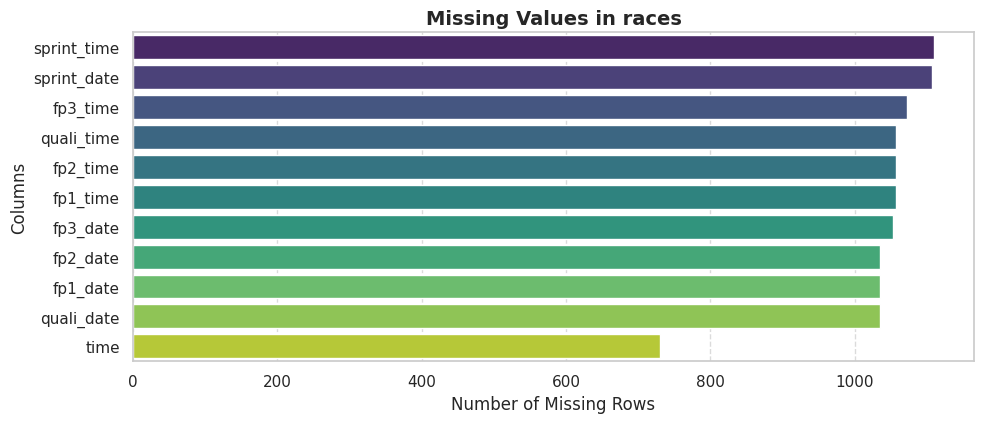


--- constructor_results ---


,Missing Count,Missing Percentage (%)
status,12608,99.87


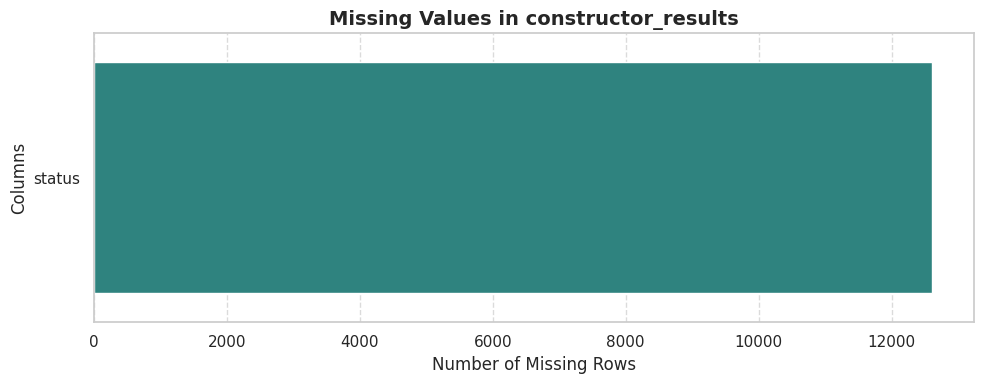


--- drivers ---


,Missing Count,Missing Percentage (%)
number,802,93.15
code,757,87.92


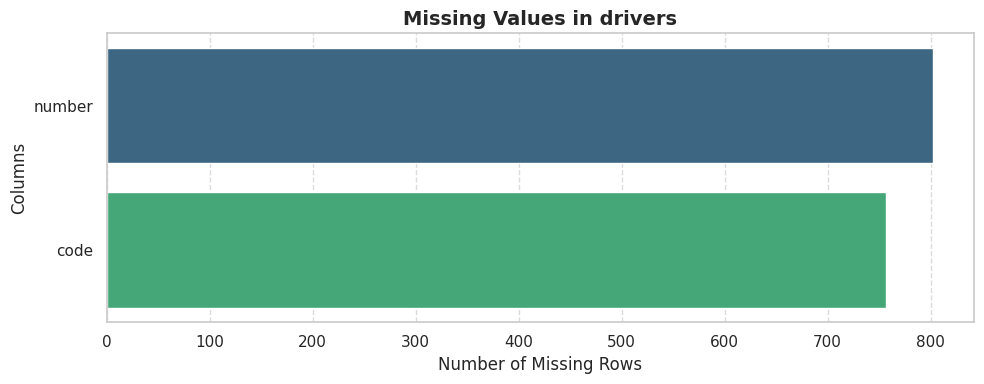


--- constructors ---
No missing values found.

--- lap_times ---
No missing values found.

--- status ---
No missing values found.

--- driver_standings ---
No missing values found.

--- seasons ---
No missing values found.

--- pit_stops ---
No missing values found.

--- sprint_results ---


,Missing Count,Missing Percentage (%)
time,20,5.56
milliseconds,20,5.56
position,15,4.17
fastestLap,9,2.50
fastestLapTime,9,2.50
fastest_lap_seconds,9,2.50


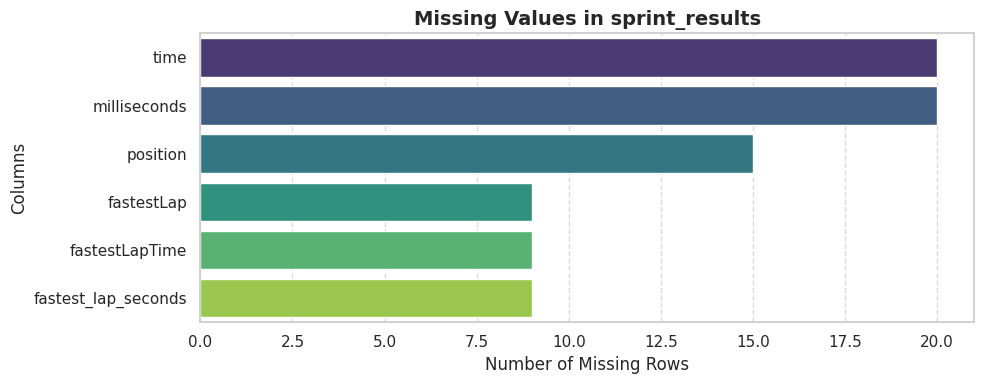


--- constructor_standings ---
No missing values found.

--- results ---


,Missing Count,Missing Percentage (%)
time,19079,71.30
milliseconds,19079,71.30
fastest_lap_seconds,18507,69.16
fastestLap,18507,69.16
fastestLapTime,18507,69.16
fastestLapSpeed,18507,69.16
rank,18249,68.20
position,10953,40.93
number,6,0.02


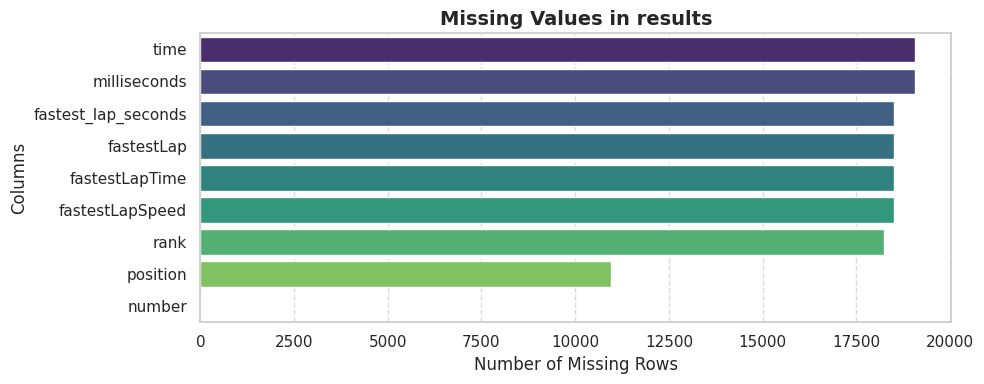


--- circuits ---
No missing values found.

--- qualifying ---


,Missing Count,Missing Percentage (%)
q3_seconds,6865,65.42
q3,6865,65.42
q2_seconds,4647,44.28
q2,4647,44.28
q1,156,1.49
q1_seconds,156,1.49


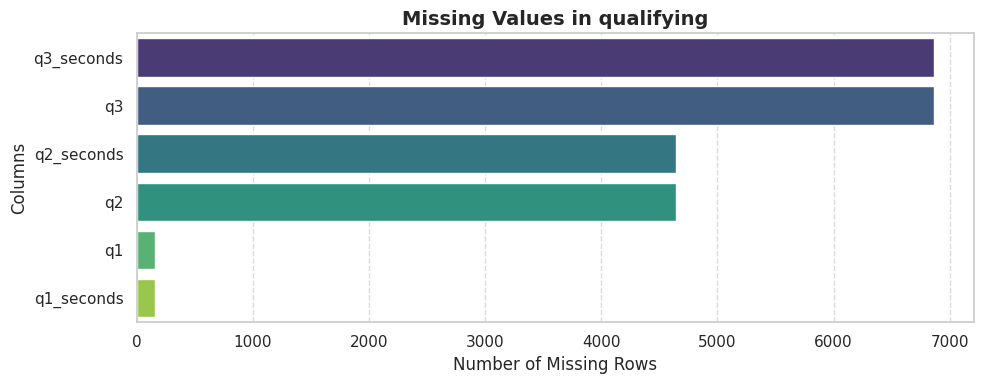

In [8]:
# checking missing values and plotting
for name, df in data.items():
  missing = df.isnull().sum()
  missing = missing[missing > 0].sort_values(ascending=False)

  print(f"\n--- {name} ---")

  if missing.empty:
    print("No missing values found.")
  else:
    missing_table = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage (%)": (missing / len(df) * 100).round(2),
    })
    display(missing_table)

    # Plotting missing values as a bar chart
    plt.figure(figsize=(10, max(4, len(missing) * 0.4)))
    sns.barplot(
        x=missing.values, y=missing.index, palette="viridis", hue=missing.index
    )
    plt.title(f"Missing Values in {name}", fontsize=14, fontweight="bold")
    plt.xlabel("Number of Missing Rows", fontsize=12)
    plt.ylabel("Columns", fontsize=12)
    plt.grid(axis="x", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()


### Initial EDA on original data

Visualize the raw dataset before cleaning. This establishes a baseline for the later before/after comparison.

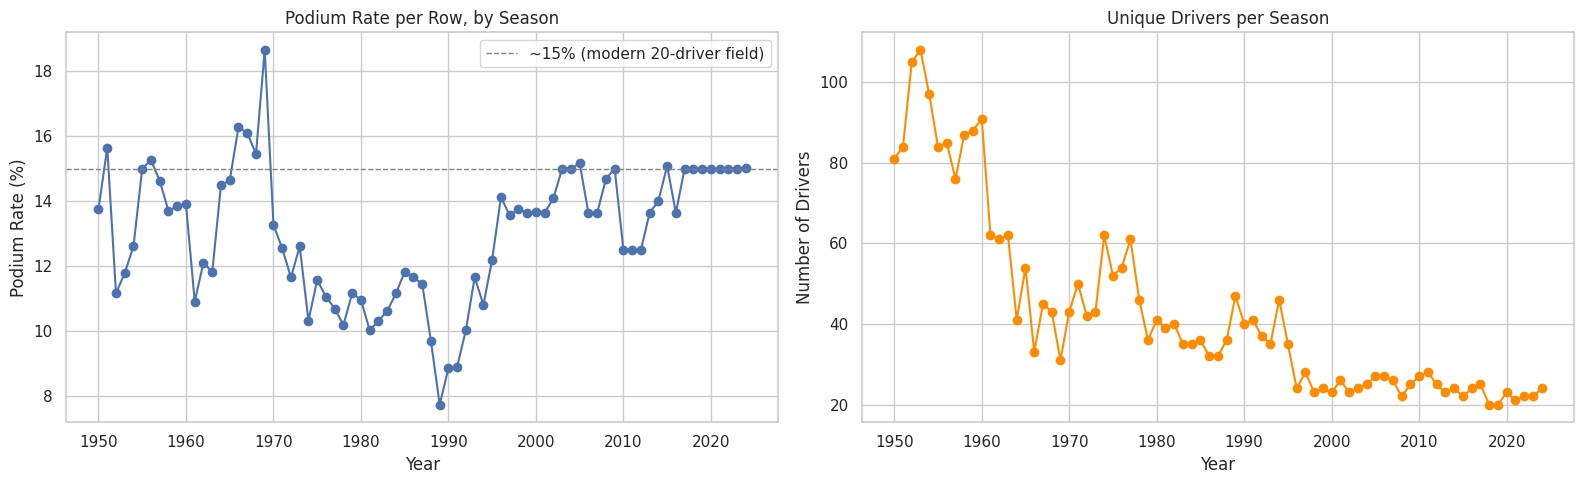

Note: podium rate per row falls as field size grows (more entrants per podium slot), which is why the podium base rate is much lower than 15% in early, larger-field seasons.


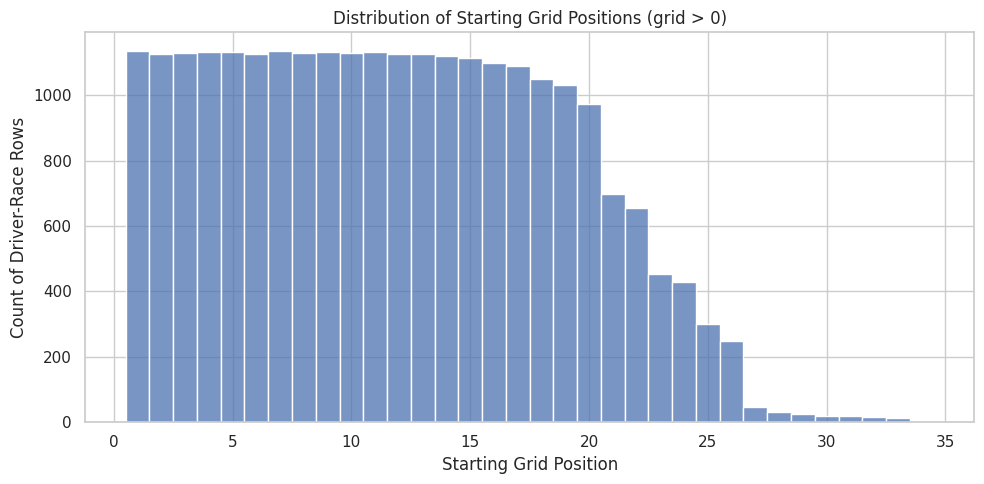

Grid = 0 rows excluded from this plot: 1638 (these represent pit-lane starts or other non-standard grid entries; see note in glossary that grid=0 needs verification in EDA).


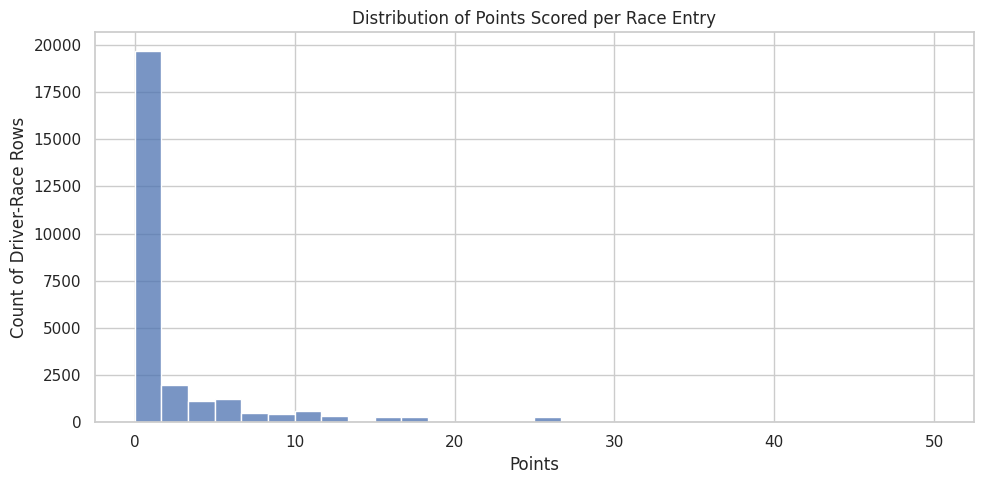

Share of rows scoring 0 points: 69.5%
Points are heavily zero-inflated (most drivers in most races score no points), and the non-zero values cluster at different levels across eras because the points-paying system itself changed over 1950-2024 (more points-paying positions, different point values for 1st-10th, etc.).


In [9]:
# ============================================================
# INITIAL EDA: distributions and trends (raw data, before cleaning)
# ============================================================



# Use a season (year) column joined onto results; raw 'data', not 'clean'.
res_raw = data["results"].merge(
    data["races"][["raceId", "year"]],
    on="raceId",
    how="left"
)

res_raw["grid"] = pd.to_numeric(res_raw["grid"], errors="coerce")
res_raw["positionOrder"] = pd.to_numeric(res_raw["positionOrder"], errors="coerce")
res_raw["points"] = pd.to_numeric(res_raw["points"], errors="coerce")

res_raw["podium"] = res_raw["positionOrder"].between(1, 3).astype(int)


# ------------------------------------------------------------
# 1. Podium rate trend over seasons
# ------------------------------------------------------------
podium_by_year = (
    res_raw.groupby("year")["podium"]
    .mean()
    .mul(100)
    .reset_index(name="podium_rate")
)

field_size_by_year = (
    res_raw.groupby("year")["driverId"]
    .nunique()
    .reset_index(name="unique_drivers")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(podium_by_year["year"], podium_by_year["podium_rate"], marker="o")
axes[0].set_title("Podium Rate per Row, by Season")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Podium Rate (%)")
axes[0].axhline(15, color="grey", linestyle="--", linewidth=1, label="~15% (modern 20-driver field)")
axes[0].legend()

axes[1].plot(field_size_by_year["year"], field_size_by_year["unique_drivers"],
             marker="o", color="darkorange")
axes[1].set_title("Unique Drivers per Season")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of Drivers")

plt.tight_layout()
plt.show()

print(
    "Note: podium rate per row falls as field size grows (more entrants per podium "
    "slot), which is why the podium base rate is much lower than 15% in early, "
    "larger-field seasons."
)


# ------------------------------------------------------------
# 2. Starting grid position distribution
# ------------------------------------------------------------
grid_valid = res_raw[res_raw["grid"] > 0]["grid"]  # grid 0 = non-standard start (pit lane / excluded)

plt.figure(figsize=(10, 5))
sns.histplot(grid_valid, bins=range(1, int(grid_valid.max()) + 2), discrete=True)
plt.title("Distribution of Starting Grid Positions (grid > 0)")
plt.xlabel("Starting Grid Position")
plt.ylabel("Count of Driver-Race Rows")
plt.tight_layout()
plt.show()

print(
    f"Grid = 0 rows excluded from this plot: {(res_raw['grid'] == 0).sum()} "
    "(these represent pit-lane starts or other non-standard grid entries; "
    "see note in glossary that grid=0 needs verification in EDA)."
)


# ------------------------------------------------------------
# 3. Points distribution (raw, shows zero-inflation + scoring-system eras)
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.histplot(res_raw["points"].dropna(), bins=30)
plt.title("Distribution of Points Scored per Race Entry")
plt.xlabel("Points")
plt.ylabel("Count of Driver-Race Rows")
plt.tight_layout()
plt.show()

zero_pts_pct = (res_raw["points"] == 0).mean() * 100
print(f"Share of rows scoring 0 points: {zero_pts_pct:.1f}%")
print(
    "Points are heavily zero-inflated (most drivers in most races score no points), "
    "and the non-zero values cluster at different levels across eras because the "
    "points-paying system itself changed over 1950-2024 (more points-paying "
    "positions, different point values for 1st-10th, etc.)."
)


### Check driver–race uniqueness

Find repeated `(raceId, driverId)` combinations in tables where one entry per driver and race is expected.

In [10]:
# Grain check: each of these tables should have one row per (raceId, driverId)
for t in ["results", "qualifying", "sprint_results"]:
    df = data[t]
    extra = df.duplicated(["raceId", "driverId"]).sum()
    involved = df.duplicated(["raceId", "driverId"], keep=False).sum()
    print(f"{t}: {extra} extra rows, {involved} rows involved")


results: 91 extra rows, 176 rows involved
qualifying: 0 extra rows, 0 rows involved
sprint_results: 0 extra rows, 0 rows involved


### Investigate shared-drive duplicates

Inspect duplicated race entries and their historical context before choosing which record to retain.

,raceId,driverId,year,rows,constructors,started
0,540,229,1978,2,2,0
1,717,373,1964,2,1,2
2,733,465,1962,2,2,0
3,742,475,1961,2,2,2
4,745,418,1961,2,1,2
5,746,475,1960,2,1,2
6,766,541,1958,2,2,0
7,770,479,1958,2,1,2
8,774,566,1958,2,1,2
9,776,581,1957,2,1,2


,resultId,raceId,year,name,driverId,constructorId,grid,positionOrder,positionText,points,statusId
13188,13189,540,1978,Italian Grand Prix,229,54,0,26,F,0.0,81
13191,13192,540,1978,Italian Grand Prix,229,57,0,29,F,0.0,97
17362,17363,717,1964,United States Grand Prix,373,172,1,7,7,0.0,60
24298,24304,717,1964,United States Grand Prix,373,172,1,12,R,0.0,98
17740,17741,733,1962,British Grand Prix,465,172,0,22,W,0.0,54
17743,17744,733,1962,British Grand Prix,465,97,0,25,W,0.0,54
17961,17962,742,1961,British Grand Prix,475,102,20,19,D,0.0,2
17963,17964,742,1961,British Grand Prix,475,172,5,21,R,0.0,23
18062,18063,745,1961,United States Grand Prix,418,172,11,17,R,0.0,6
24297,24303,745,1961,United States Grand Prix,418,172,15,11,11,0.0,18


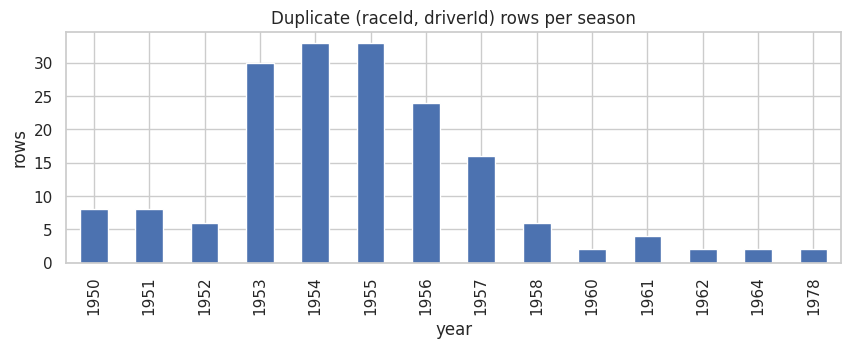

In [11]:
res = data["results"].merge(data["races"][["raceId", "year", "name"]], on="raceId", how="left")
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].sort_values(["raceId", "driverId", "resultId"])

# Did the driver have different cars in the same race (shared drive)?
summary = (dups.groupby(["raceId", "driverId"])
               .agg(year=("year", "first"), rows=("resultId", "size"),
                    constructors=("constructorId", "nunique"),
                    started=("grid", lambda g: (g > 0).sum()))
               .reset_index())
display(summary.head(20))

display(dups[["resultId", "raceId", "year", "name", "driverId", "constructorId",
              "grid", "positionOrder", "positionText", "points", "statusId"]].head(20))

# Plot: duplicates per season
ax = dups.groupby("year").size().plot(kind="bar", figsize=(10, 3), title="Duplicate (raceId, driverId) rows per season")
ax.set_ylabel("rows")
plt.show()


### Resolve shared-drive entries without pretending that they are ordinary duplicates

The required prediction grain is **one driver per race**. In the 1950s, a driver could appear in several result rows because of shared cars. We preserve all original rows in `raw_data` and use a reproducible rule on a copy: prefer a row with a recorded positive starting grid, then the lowest `resultId` (stable source order). This represents the driver's original entry, rather than cherry-picking a good finish. The choice can affect historical labels; the following cell reports how many duplicate groups have conflicting podium outcomes. We **do not** assume that the smallest grid position means the most correct finish.

In [12]:
clean = {name: frame.copy() for name, frame in data.items()}
r = clean["results"].copy()
r["_has_start_grid"] = pd.to_numeric(r["grid"], errors="coerce").gt(0).astype(int)
r["_source_result_id"] = pd.to_numeric(r["resultId"], errors="coerce")
shared_groups = r.loc[r.duplicated(["raceId", "driverId"], keep=False)].copy()
if not shared_groups.empty:
    shared_groups["_podium_label"] = pd.to_numeric(shared_groups["positionOrder"], errors="coerce").between(1, 3).astype(int)
    conflicting_groups = (shared_groups.groupby(["raceId", "driverId"])["_podium_label"].nunique() > 1).sum()
    print("Shared-drive groups with conflicting row-level podium labels:", int(conflicting_groups))
    print("Such groups require caution when interpreting early-era labels.")
r = r.sort_values(["raceId", "driverId", "_has_start_grid", "_source_result_id"],
                  ascending=[True, True, False, True], kind="mergesort")
kept = r.drop_duplicates(["raceId", "driverId"], keep="first")
dropped = r.loc[~r.index.isin(kept.index)].copy()
kept = kept.drop(columns=["_has_start_grid", "_source_result_id"])
assert not kept.duplicated(["raceId", "driverId"]).any()
assert len(kept) + len(dropped) == len(clean["results"])
print(f"results: {len(clean['results'])} -> {len(kept)} rows ({len(dropped)} shared-drive rows excluded)")
clean["results"] = kept.sort_values("resultId").reset_index(drop=True)


Shared-drive groups with conflicting row-level podium labels: 21
Such groups require caution when interpreting early-era labels.
results: 26759 -> 26668 rows (91 shared-drive rows excluded)


### Inspect missingness before treatment

Examine missing-value patterns in the cleaned copies before applying column-specific handling.

=== MISSING VALUES SUMMARY FOR ALL TABLES ===


,Table,Rows,Columns,Missing Values,Columns With Missing Values,Rows With Missing Values,Rows Missing (%)
11,results,26668,19,140755,9,22403,84.01
13,qualifying,10494,12,23336,6,6865,65.42
1,constructor_results,12625,5,12608,1,12608,99.87
0,races,1125,19,11349,11,1125,100.00
2,drivers,861,9,1559,2,802,93.15
9,sprint_results,360,17,82,6,20,5.56
5,status,139,2,0,0,0,0.00
4,lap_times,589081,7,0,0,0,0.00
3,constructors,212,5,0,0,0,0.00
6,driver_standings,34863,7,0,0,0,0.00



=== RACES ===


,Missing Count,Missing (%),Non-Missing Count
sprint_time,1110,98.67,15
sprint_date,1107,98.40,18
fp3_time,1072,95.29,53
quali_time,1057,93.96,68
fp2_time,1057,93.96,68
fp1_time,1057,93.96,68
fp3_date,1053,93.60,72
fp2_date,1035,92.00,90
fp1_date,1035,92.00,90
quali_date,1035,92.00,90


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time,race_year
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2009


...


=== QUALIFYING ===


,Missing Count,Missing (%),Non-Missing Count
q3_seconds,6865,65.42,3629
q3,6865,65.42,3629
q2_seconds,4647,44.28,5847
q2,4647,44.28,5847
q1,156,1.49,10338
q1_seconds,156,1.49,10338


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3,q1_seconds,q2_seconds,q3_seconds
9,10,18,20,5,15,10,1:26.702,1:25.842,NaN,86.702,85.842,NaN
10,11,18,22,11,17,11,1:26.369,1:26.173,NaN,86.369,86.173,NaN
11,12,18,4,4,5,12,1:26.907,1:26.188,NaN,86.907,86.188,NaN



=== IMPORTANT IDENTIFIER CHECK ===

=== QUALIFYING MISSING VALUES BY YEAR (%) ===


,q1_seconds,q2_seconds,q3_seconds
year,,,
1994,0.26,100.00,100.00
1995,5.74,100.00,100.00
1996,2.03,100.00,100.00
1997,0.45,100.00,100.00
1998,1.31,100.00,100.00
1999,1.54,100.00,100.00
2000,0.00,100.00,100.00
2001,0.00,100.00,100.00
2002,0.00,100.00,100.00


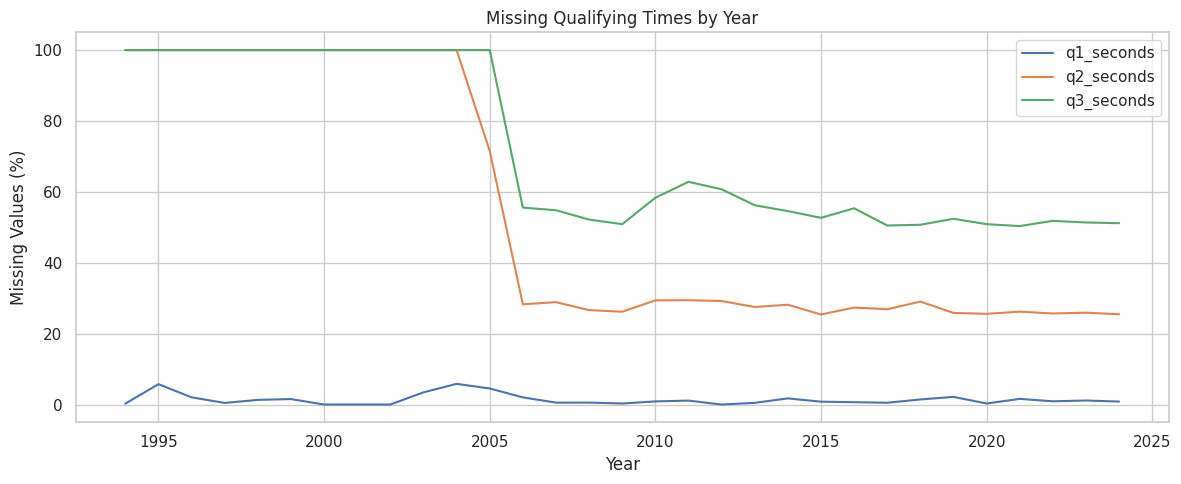


Missing-value inspection completed. No data was modified.


In [13]:
#inspect before we handle missing values


# Inspect missing values in all cleaned tables.
# We only investigate here; no values are filled or removed.

summary = []

for name, df in clean.items():
    missing = df.isna().sum()

    summary.append({
        "Table": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": missing.sum(),
        "Columns With Missing Values": (missing > 0).sum(),
        "Rows With Missing Values": df.isna().any(axis=1).sum(),
        "Rows Missing (%)": round(df.isna().any(axis=1).mean() * 100, 2)
    })

summary_df = pd.DataFrame(summary).sort_values(
    "Missing Values", ascending=False
)

print("=== MISSING VALUES SUMMARY FOR ALL TABLES ===")
display(summary_df)

# Show missing-value counts and percentages for every affected column.
# Percentages help us compare tables of different sizes.

for name, df in clean.items():
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    if missing.empty:
        continue

    print(f"\n=== {name.upper()} ===")

    details = pd.DataFrame({
        "Missing Count": missing,
        "Missing (%)": (missing / len(df) * 100).round(2),
        "Non-Missing Count": len(df) - missing
    })

    display(details)

    # Show up to 3 example records, including their missing columns.
    # This helps identify whether missingness is normal or problematic.
    example_rows = df[df.isna().any(axis=1)].head(3)
    display(example_rows)

# Check identifiers because missing IDs may prevent correct table joins.

print("\n=== IMPORTANT IDENTIFIER CHECK ===")

for name, df in clean.items():
    id_columns = [
        col for col in df.columns
        if col.endswith("Id") or col in ["year", "round"]
    ]

    missing_ids = df[id_columns].isna().sum()
    missing_ids = missing_ids[missing_ids > 0]

    if not missing_ids.empty:
        print(f"\n{name}")
        display(missing_ids)

# Investigate qualifying missingness by year.
# Q2 and Q3 can be absent because a driver did not reach those sessions.
# Older seasons can also have different qualifying formats.

if "qualifying" in clean and "races" in clean:
    q = clean["qualifying"].merge(
        clean["races"][["raceId", "year"]],
        on="raceId",
        how="left"
    )

    time_cols = [
        col for col in ["q1_seconds", "q2_seconds", "q3_seconds"]
        if col in q.columns
    ]

    if time_cols:
        yearly_missing = (
            q.groupby("year")[time_cols]
            .apply(lambda x: x.isna().mean() * 100)
        )

        print("\n=== QUALIFYING MISSING VALUES BY YEAR (%) ===")
        display(yearly_missing.round(2))

        yearly_missing.plot(figsize=(12, 5))
        plt.title("Missing Qualifying Times by Year")
        plt.xlabel("Year")
        plt.ylabel("Missing Values (%)")
        plt.tight_layout()
        plt.show()

print("\nMissing-value inspection completed. No data was modified.")


### Cleaning missing values and preserving race-specific qualifying information

The original CSV values are preserved in `raw_data`. Type conversion happens in `data`, and further cleaning happens in `clean`. Duration strings are parsed into seconds, non-predictive empty columns are dropped, and historical lap data are recovered for EDA only. Missing Q1 times **remain missing**, because times from different circuits and eras cannot be compared. The fastest Q1 reference is computed only from genuine observed laps in the same race. The model's imputer is trained on training rows, avoiding validation/test information in fitted preprocessing.

In [14]:
#HANDLE NULLS

# Use clean created by the duplicate-removal cell.
# The original data dictionary remains unchanged.

def to_seconds(value):
    if pd.isna(value):
        return np.nan

    try:
        parts = str(value).split(":")

        if len(parts) == 3:
            return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])

        if len(parts) == 2:
            return float(parts[0]) * 60 + float(parts[1])

        return float(parts[0])

    except (ValueError, TypeError):
        return np.nan


# 1. RACES
# Remove highly incomplete session schedules.
# Keep race date, year, round and circuit information.
# Keep race start time in historical data.

clean["races"] = clean["races"].drop(columns=[
    "fp1_date", "fp1_time",
    "fp2_date", "fp2_time",
    "fp3_date", "fp3_time",
    "quali_date", "quali_time",
    "sprint_date", "sprint_time"
], errors="ignore")


# 2. DRIVERS
# Number and code are mostly missing.
# driverId already identifies the driver.

clean["drivers"] = clean["drivers"].drop(
    columns=["number", "code"],
    errors="ignore"
)


# 3. CONSTRUCTOR RESULTS
# status is almost entirely missing.

clean["constructor_results"] = clean["constructor_results"].drop(
    columns=["status"],
    errors="ignore"
)


# 4. RESULTS
# Restore historical results and fastest-lap statistics.
# Only remove the unnecessary car number.
# Keep official positions and timing records unchanged.

r = clean["results"].copy()

r = r.drop(columns=["number"], errors="ignore")

r["position_missing"] = r["position"].isna().astype(int)

# Recover fastest-lap seconds from recorded strings.
if "fastestLapTime" in r.columns:
    converted = r["fastestLapTime"].apply(to_seconds)

    if "fastest_lap_seconds" not in r.columns:
        r["fastest_lap_seconds"] = converted
    else:
        r["fastest_lap_seconds"] = (
            r["fastest_lap_seconds"].fillna(converted)
        )

# Recover missing fastest-lap measurements from lap_times.
laps = clean["lap_times"].copy()

fastest = (
    laps.sort_values(["raceId", "driverId", "milliseconds", "lap"])
    .drop_duplicates(["raceId", "driverId"])
    [["raceId", "driverId", "lap", "milliseconds"]]
    .rename(columns={
        "lap": "recovered_lap",
        "milliseconds": "recovered_ms"
    })
)

r = r.merge(
    fastest,
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

r["fastestLap"] = pd.to_numeric(
    r["fastestLap"], errors="coerce"
).fillna(r["recovered_lap"])

r["fastest_lap_seconds"] = (
    r["fastest_lap_seconds"].fillna(
        r["recovered_ms"] / 1000
    )
)

# Recover fastest-lap rank only for races where
# all retained drivers have recorded fastest-lap times.

r["rank"] = pd.to_numeric(r["rank"], errors="coerce")

complete_race = (
    r.groupby("raceId")["fastest_lap_seconds"]
    .transform(lambda x: x.notna().all())
)

calculated_rank = (
    r.groupby("raceId")["fastest_lap_seconds"]
    .rank(method="min")
)

r["rank"] = r["rank"].fillna(
    calculated_rank.where(complete_race)
)

r["fastest_lap_missing"] = (
    r["fastest_lap_seconds"].isna().astype(int)
)

r = r.drop(columns=[
    "recovered_lap", "recovered_ms"
])

clean["results"] = r


# 5. QUALIFYING
# Restore Q1, Q2 and Q3 seconds.
# Missing Q2/Q3 is meaningful because drivers may
# not have reached those sessions.

q = clean["qualifying"].copy()

for col in ["q1", "q2", "q3"]:
    seconds_col = col + "_seconds"

    if col in q.columns:
        converted = q[col].apply(to_seconds)

        if seconds_col not in q.columns:
            q[seconds_col] = converted
        else:
            q[seconds_col] = (
                q[seconds_col].fillna(converted)
            )

    q["has_" + col + "_time"] = (
        q[seconds_col].notna().astype(int)
    )

# Q1 times are circuit-specific. Do not fill a missing lap with a median
# from other races: that would invent a time and distort same-race gaps.
# Keep observed values only; the train-fitted model imputer handles missing gaps.
q["q1_missing"] = q["q1_seconds"].isna().astype(int)
q = q.drop(columns=["q1", "q2", "q3"], errors="ignore")
clean["qualifying"] = q.reset_index(drop=True)


# 6. SPRINT RESULTS
# Restore sprint fastest-lap information.
# Recover recorded times without inventing official results.

s = clean["sprint_results"].copy()

if "fastestLapTime" in s.columns:
    converted = s["fastestLapTime"].apply(to_seconds)

    if "fastest_lap_seconds" not in s.columns:
        s["fastest_lap_seconds"] = converted
    else:
        s["fastest_lap_seconds"] = (
            s["fastest_lap_seconds"].fillna(converted)
        )

s["position_missing"] = s["position"].isna().astype(int)

s["fastest_lap_missing"] = (
    s["fastest_lap_seconds"].isna().astype(int)
)

# Drop redundant text fastest-lap time.
# Keep the numeric seconds and other historical information.
s = s.drop(
    columns=["fastestLapTime"],
    errors="ignore"
)

clean["sprint_results"] = s


# 7. OTHER TABLES
# No missing values were found in the remaining eight tables.


# 8. SUMMARY

summary = []

for name in data:
    before = data[name]
    after = clean[name]

    summary.append({
        "Table": name,
        "Rows Before": len(before),
        "Rows After": len(after),
        "Columns Before": len(before.columns),
        "Columns After": len(after.columns),
        "Missing Before": int(before.isna().sum().sum()),
        "Missing After": int(after.isna().sum().sum())
    })

print("=== CLEANING SUMMARY ===")
display(pd.DataFrame(summary))


# 9. REMAINING MISSING VALUES

print("\n=== REMAINING MISSING VALUES ===")

for name, df in clean.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print("\n" + name.upper())

        display(pd.DataFrame({
            "Missing Count": missing,
            "Missing (%)": (
                missing / len(df) * 100
            ).round(2)
        }).sort_values("Missing Count", ascending=False))


# 10. FINAL CHECK

print(
    "\nDuplicate race-driver results:",
    clean["results"].duplicated(
        ["raceId", "driverId"]
    ).sum()
)

print("\nCleaning completed.")


=== CLEANING SUMMARY ===


,Table,Rows Before,Rows After,Columns Before,Columns After,Missing Before,Missing After
0,races,1125,1125,19,9,11349,731
1,constructor_results,12625,12625,5,4,12608,0
2,drivers,861,861,9,7,1559,0
3,constructors,212,212,5,5,0,0
4,lap_times,589081,589081,7,7,0,0
5,status,139,139,2,2,0,0
6,driver_standings,34863,34863,7,7,0,0
7,seasons,75,75,2,2,0,0
8,pit_stops,11371,11371,8,8,0,0
9,sprint_results,360,360,17,18,82,73



=== REMAINING MISSING VALUES ===

RACES


,Missing Count,Missing (%)
time,731,64.98



SPRINT_RESULTS


...


RESULTS


,Missing Count,Missing (%)
time,19005,71.27
milliseconds,19005,71.27
fastestLapSpeed,18416,69.06
fastestLapTime,18416,69.06
rank,16972,63.64
fastestLap,15624,58.59
fastest_lap_seconds,15624,58.59
position,10917,40.94



QUALIFYING


,Missing Count,Missing (%)
q3_seconds,6865,65.42
q2_seconds,4647,44.28
q1_seconds,156,1.49



Duplicate race-driver results: 0

Cleaning completed.


### Compare EDA before and after cleaning

Use consistent visual comparisons to show how cleaning affects distributions, missingness, and the driver–race data.

1. TABLE SIZE BEFORE AND AFTER


,Table,Rows Before,Rows After,Rows Removed,Columns Before,Columns After,Columns Removed
0,races,1125,1125,0,19,9,10
1,constructor_results,12625,12625,0,5,4,1
2,drivers,861,861,0,9,7,2
3,constructors,212,212,0,5,5,0
4,lap_times,589081,589081,0,7,7,0
5,status,139,139,0,2,2,0
6,driver_standings,34863,34863,0,7,7,0
7,seasons,75,75,0,2,2,0
8,pit_stops,11371,11371,0,8,8,0
9,sprint_results,360,360,0,17,18,1


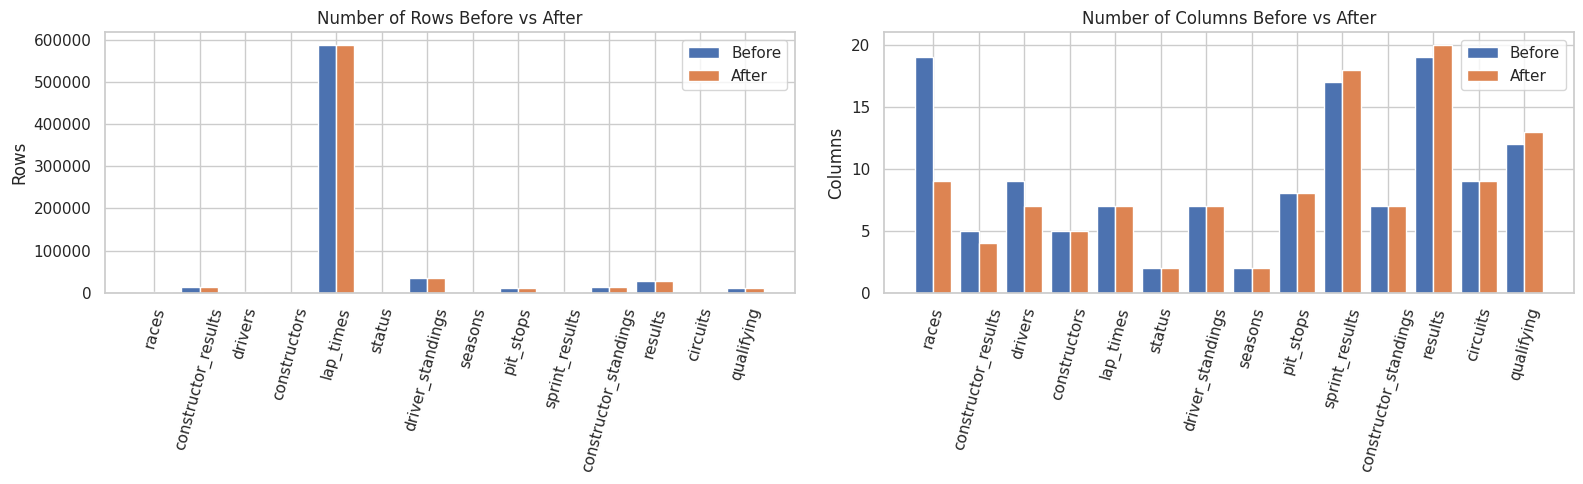


2. MISSING VALUES BEFORE AND AFTER


,Table,Missing Before,Missing After,Missing in Removed Columns,Missing Before in Shared Columns,Missing After in Shared Columns
0,races,11349,731,10618,731,731
1,constructor_results,12608,0,12608,0,0
2,drivers,1559,0,1559,0,0
3,constructors,0,0,0,0,0
4,lap_times,0,0,0,0,0
5,status,0,0,0,0,0
6,driver_standings,0,0,0,0,0
7,seasons,0,0,0,0,0
8,pit_stops,0,0,0,0,0
9,sprint_results,82,73,9,73,73


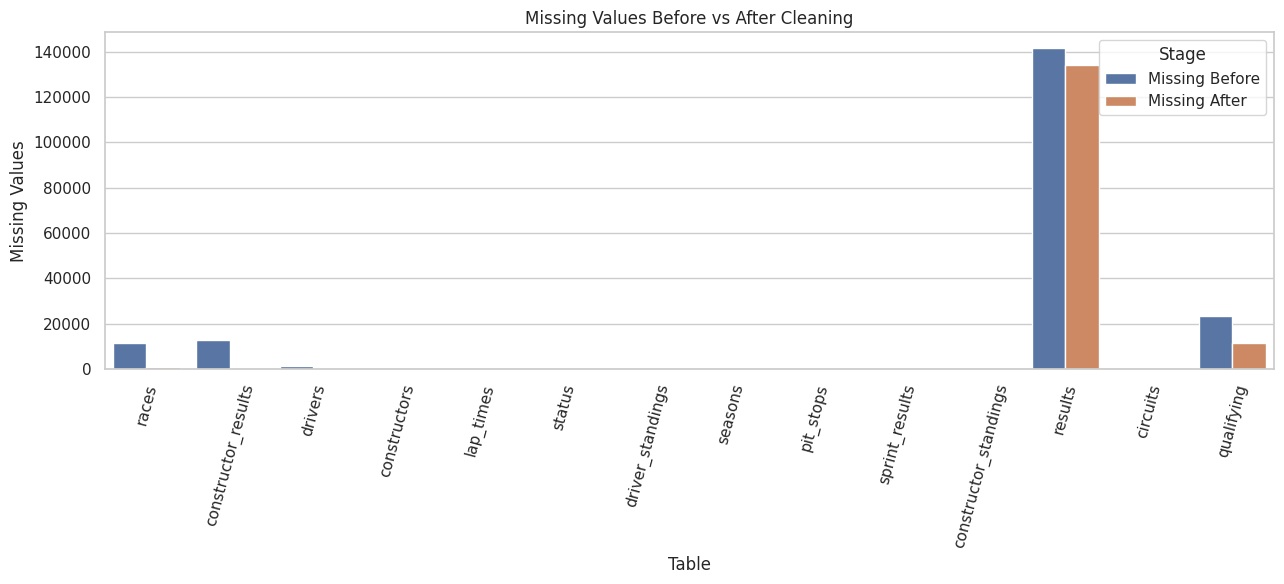


3. MISSING PERCENTAGE BY COLUMN


,Table,Column,Missing Before (%),Missing After (%),Action
0,races,time,64.98,64.98,Kept
1,races,fp1_date,92.00,NaN,Dropped
2,races,fp1_time,93.96,NaN,Dropped
3,races,fp2_date,92.00,NaN,Dropped
4,races,fp2_time,93.96,NaN,Dropped
5,races,fp3_date,93.60,NaN,Dropped
6,races,fp3_time,95.29,NaN,Dropped
7,races,quali_date,92.00,NaN,Dropped
8,races,quali_time,93.96,NaN,Dropped
9,races,sprint_date,98.40,NaN,Dropped


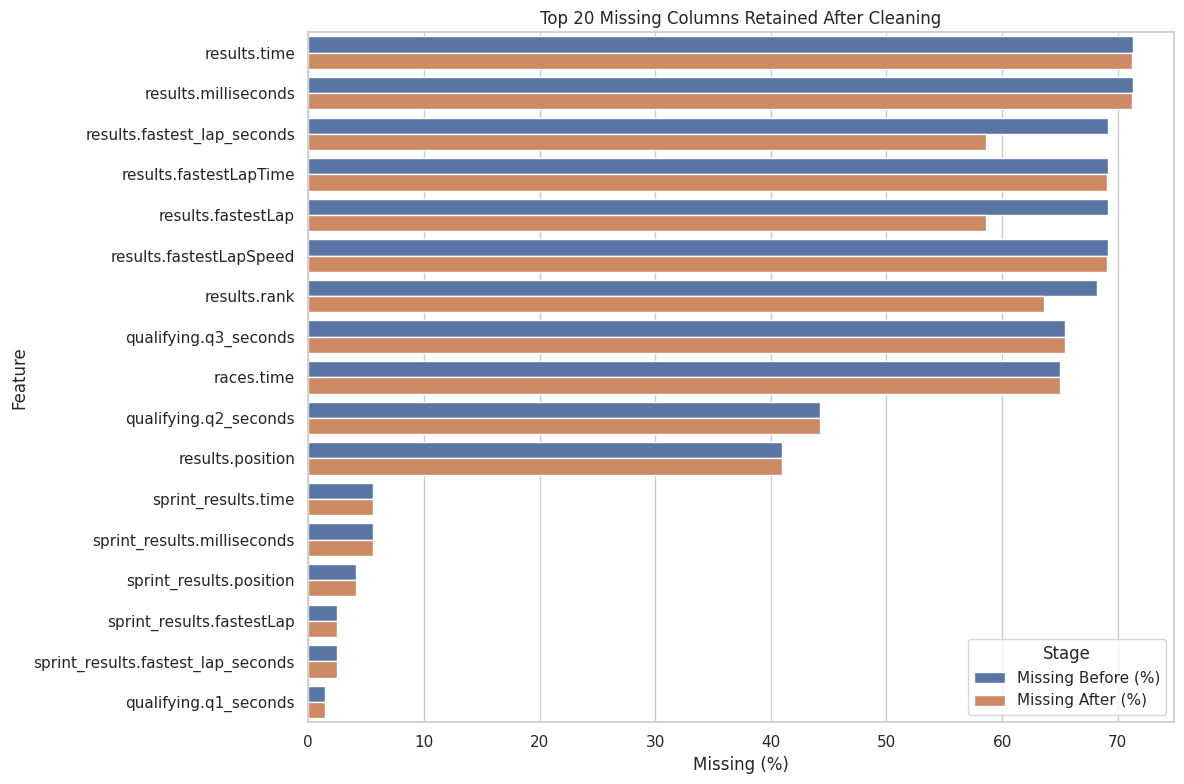


4. DUPLICATES BEFORE AND AFTER


,Table,Duplicates Before,Duplicates After
0,results,91,0
1,qualifying,0,0
2,sprint_results,0,0


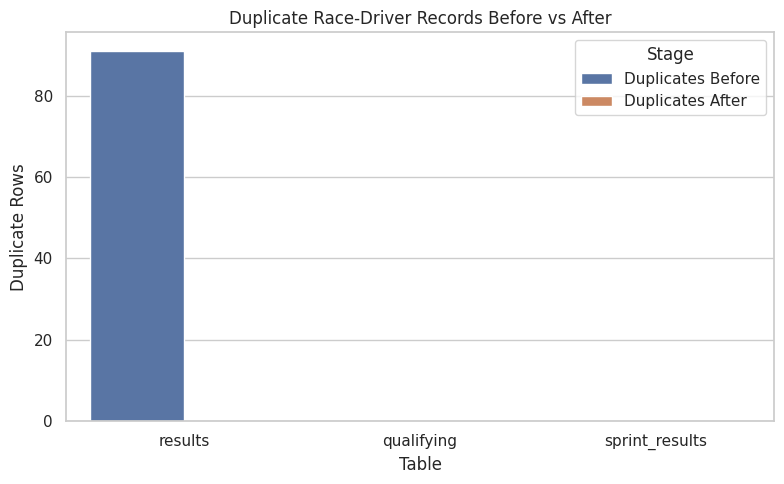


5. PODIUM DISTRIBUTION BEFORE AND AFTER


,Stage,Podium,Not Podium,Podium (%),Missing Position Order
0,Before,3397,23362,12.69,0
1,After,3379,23289,12.67,0


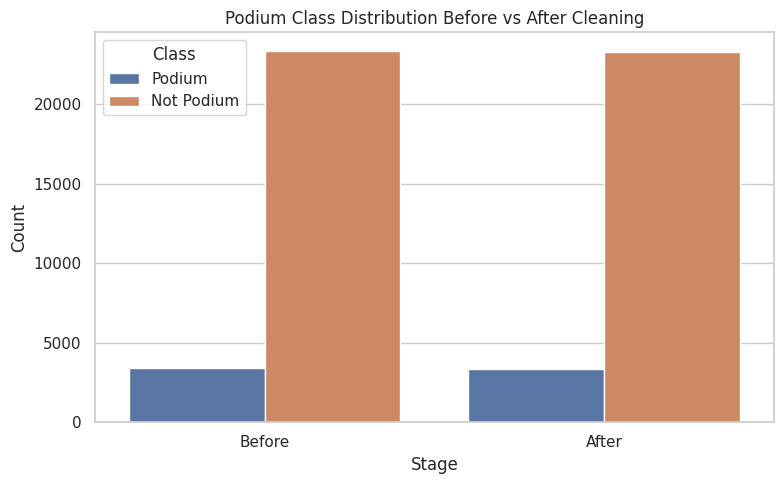


6. DROPPED COLUMNS AND THEIR MISSINGNESS


,Table,Dropped Column,Missing Count,Missing (%)
10,constructor_results,status,12608,99.87
9,races,sprint_time,1110,98.67
8,races,sprint_date,1107,98.40
5,races,fp3_time,1072,95.29
7,races,quali_time,1057,93.96
1,races,fp1_time,1057,93.96
3,races,fp2_time,1057,93.96
4,races,fp3_date,1053,93.60
12,drivers,number,802,93.15
0,races,fp1_date,1035,92.00



7. FINAL CHECKS
races raceId missing: 0
races date missing: 0
results raceId missing: 0
results driverId missing: 0
results positionOrder missing: 0
qualifying raceId missing: 0
qualifying driverId missing: 0
Remaining result duplicates: 0

Before-and-after EDA completed.


In [15]:
#EDA BEFOR VS AFTER



# Compare original data with cleaned data.
# The original tables are not modified.
# Dropped columns are counted separately so that a reduction in
# missing values is not confused with successfully filling values.

# 1. TABLE SIZE COMPARISON
table_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    table_summary.append({
        "Table": name,
        "Rows Before": len(before),
        "Rows After": len(after),
        "Rows Removed": len(before) - len(after),
        "Columns Before": len(before.columns),
        "Columns After": len(after.columns),
        "Columns Removed": len(set(before.columns) - set(after.columns))
    })

table_summary = pd.DataFrame(table_summary)

print("1. TABLE SIZE BEFORE AND AFTER")
display(table_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

x = np.arange(len(table_summary))
w = 0.4

axes[0].bar(x - w/2, table_summary["Rows Before"], w, label="Before")
axes[0].bar(x + w/2, table_summary["Rows After"], w, label="After")
axes[0].set_xticks(x)
axes[0].set_xticklabels(table_summary["Table"], rotation=75)
axes[0].set_title("Number of Rows Before vs After")
axes[0].set_ylabel("Rows")
axes[0].legend()

axes[1].bar(x - w/2, table_summary["Columns Before"], w, label="Before")
axes[1].bar(x + w/2, table_summary["Columns After"], w, label="After")
axes[1].set_xticks(x)
axes[1].set_xticklabels(table_summary["Table"], rotation=75)
axes[1].set_title("Number of Columns Before vs After")
axes[1].set_ylabel("Columns")
axes[1].legend()

plt.tight_layout()
plt.show()


# 2. MISSING VALUES BY TABLE
# This shows the total missing cells remaining in each table.
# A decrease may result from removing columns, not just filling values.

missing_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    common = before.columns.intersection(after.columns)
    removed = before.columns.difference(after.columns)

    missing_summary.append({
        "Table": name,
        "Missing Before": int(before.isna().sum().sum()),
        "Missing After": int(after.isna().sum().sum()),
        "Missing in Removed Columns": int(
            before[removed].isna().sum().sum()
        ),
        "Missing Before in Shared Columns": int(
            before[common].isna().sum().sum()
        ),
        "Missing After in Shared Columns": int(
            after[common].isna().sum().sum()
        )
    })

missing_summary = pd.DataFrame(missing_summary)

print("\n2. MISSING VALUES BEFORE AND AFTER")
display(missing_summary)

plot_data = missing_summary.melt(
    id_vars="Table",
    value_vars=["Missing Before", "Missing After"],
    var_name="Stage",
    value_name="Missing Values"
)

plt.figure(figsize=(13, 6))
sns.barplot(
    data=plot_data,
    x="Table",
    y="Missing Values",
    hue="Stage"
)
plt.title("Missing Values Before vs After Cleaning")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


# 3. MISSING PERCENTAGE FOR EVERY COLUMN
# Removed columns are shown as "Dropped", not as 0% missing.
# This makes the comparison scientifically accurate.

column_summary = []

for name in data:
    before = data[name]
    after = clean[name]

    for col in before.columns:
        before_pct = before[col].isna().mean() * 100

        if col in after.columns:
            after_pct = after[col].isna().mean() * 100
            action = "Kept"
        else:
            after_pct = np.nan
            action = "Dropped"

        if before_pct > 0:
            column_summary.append({
                "Table": name,
                "Column": col,
                "Missing Before (%)": round(before_pct, 2),
                "Missing After (%)": round(after_pct, 2)
                    if pd.notna(after_pct) else np.nan,
                "Action": action
            })

column_summary = pd.DataFrame(column_summary)

print("\n3. MISSING PERCENTAGE BY COLUMN")
display(column_summary)

# Compare missingness only for columns retained in both versions.
shared_missing = column_summary[
    column_summary["Action"] == "Kept"
].copy()

if not shared_missing.empty:
    shared_missing["Feature"] = (
        shared_missing["Table"] + "." + shared_missing["Column"]
    )

    top = shared_missing.sort_values(
        "Missing Before (%)", ascending=False
    ).head(20)

    top_plot = top.melt(
        id_vars="Feature",
        value_vars=[
            "Missing Before (%)",
            "Missing After (%)"
        ],
        var_name="Stage",
        value_name="Missing (%)"
    )

    plt.figure(figsize=(12, 8))
    sns.barplot(
        data=top_plot,
        y="Feature",
        x="Missing (%)",
        hue="Stage"
    )
    plt.title("Top 20 Missing Columns Retained After Cleaning")
    plt.tight_layout()
    plt.show()


# 4. DUPLICATE COMPARISON
# Results, qualifying and sprint_results should have at most
# one record per race-driver combination in our modeling tables.

duplicate_summary = []

for name in ["results", "qualifying", "sprint_results"]:
    before = data[name]
    after = clean[name]

    keys = ["raceId", "driverId"]

    duplicate_summary.append({
        "Table": name,
        "Duplicates Before": int(before.duplicated(keys).sum()),
        "Duplicates After": int(after.duplicated(keys).sum())
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

print("\n4. DUPLICATES BEFORE AND AFTER")
display(duplicate_summary)

duplicate_plot = duplicate_summary.melt(
    id_vars="Table",
    var_name="Stage",
    value_name="Duplicate Rows"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=duplicate_plot,
    x="Table",
    y="Duplicate Rows",
    hue="Stage"
)
plt.title("Duplicate Race-Driver Records Before vs After")
plt.tight_layout()
plt.show()


# 5. PODIUM DISTRIBUTION
# Compare class balance before and after duplicate removal.
# positionOrder is used here as the provisional podium definition.

podium_summary = []

for stage, df in [
    ("Before", data["results"]),
    ("After", clean["results"])
]:
    valid = df["positionOrder"].notna()
    positions = df.loc[valid, "positionOrder"]

    podium = positions.between(1, 3).sum()
    not_podium = len(positions) - podium

    podium_summary.append({
        "Stage": stage,
        "Podium": int(podium),
        "Not Podium": int(not_podium),
        "Podium (%)": round(podium / len(positions) * 100, 2)
            if len(positions) else np.nan,
        "Missing Position Order": int((~valid).sum())
    })

podium_summary = pd.DataFrame(podium_summary)

print("\n5. PODIUM DISTRIBUTION BEFORE AND AFTER")
display(podium_summary)

podium_plot = podium_summary.melt(
    id_vars="Stage",
    value_vars=["Podium", "Not Podium"],
    var_name="Class",
    value_name="Count"
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=podium_plot,
    x="Stage",
    y="Count",
    hue="Class"
)
plt.title("Podium Class Distribution Before vs After Cleaning")
plt.tight_layout()
plt.show()


# 6. SUMMARY OF DROPPED COLUMNS
# Document exactly which features were removed and their missingness.
# This justifies feature removal instead of hiding missing values.

removed_summary = []

for name in data:
    removed = data[name].columns.difference(clean[name].columns)

    for col in removed:
        removed_summary.append({
            "Table": name,
            "Dropped Column": col,
            "Missing Count": int(data[name][col].isna().sum()),
            "Missing (%)": round(
                data[name][col].isna().mean() * 100, 2
            )
        })

print("\n6. DROPPED COLUMNS AND THEIR MISSINGNESS")

if removed_summary:
    display(pd.DataFrame(removed_summary).sort_values(
        "Missing (%)", ascending=False
    ))
else:
    print("No columns were dropped.")


# 7. FINAL DATA QUALITY CHECKS
# Confirm that cleaning did not create missing identifiers
# or leave duplicate race-driver records in results.

print("\n7. FINAL CHECKS")

for name, columns in {
    "races": ["raceId", "date"],
    "results": ["raceId", "driverId", "positionOrder"],
    "qualifying": ["raceId", "driverId"]
}.items():
    for col in columns:
        if col in clean[name].columns:
            print(
                name, col,
                "missing:", int(clean[name][col].isna().sum())
            )

print(
    "Remaining result duplicates:",
    clean["results"].duplicated(["raceId", "driverId"]).sum()
)

print("\nBefore-and-after EDA completed.")


### Question 1 — front-row podium conversion

Join circuit, race, qualifying, and result information to compare podium conversion from grid positions 1–2 before and after 2014. Qualifying position and starting grid are distinct.

=== FRONT-ROW STARTERS ===
Total front-row starts: 2250
Total podiums: 1345

=== FRONT-ROW PODIUM CONVERSION BY CIRCUIT ===


,circuit,era,starts,podiums,podium_rate
68,Miami International Autodrome,2014 onwards,6,6,100.00
93,Suzuka Circuit,2014 onwards,18,16,88.89
29,Circuit Park Zandvoort,2014 onwards,8,7,87.50
58,Jeddah Corniche Circuit,2014 onwards,8,7,87.50
97,Yas Marina Circuit,2014 onwards,22,19,86.36
...,...,...,...,...,...
84,Scandinavian Raceway,Before 2014,12,5,41.67
22,Brands Hatch,Before 2014,28,11,39.29
13,Autódromo Internacional Nelson Piquet,Before 2014,20,7,35.00
45,Detroit Street Circuit,Before 2014,14,4,28.57



=== TOP 5 CIRCUITS BEFORE 2014 ===


,circuit,era,starts,podiums,podium_rate
23,Buddh International Circuit,Before 2014,6,5,83.33
37,Circuit de Nevers Magny-Cours,Before 2014,36,29,80.56
56,Istanbul Park,Before 2014,14,11,78.57
46,Dijon-Prenois,Before 2014,12,9,75.00
94,Suzuka Circuit,Before 2014,50,35,70.00



=== TOP 5 CIRCUITS FROM 2014 ONWARDS ===


,circuit,era,starts,podiums,podium_rate
68,Miami International Autodrome,2014 onwards,6,6,100.00
93,Suzuka Circuit,2014 onwards,18,16,88.89
29,Circuit Park Zandvoort,2014 onwards,8,7,87.50
58,Jeddah Corniche Circuit,2014 onwards,8,7,87.50
97,Yas Marina Circuit,2014 onwards,22,19,86.36


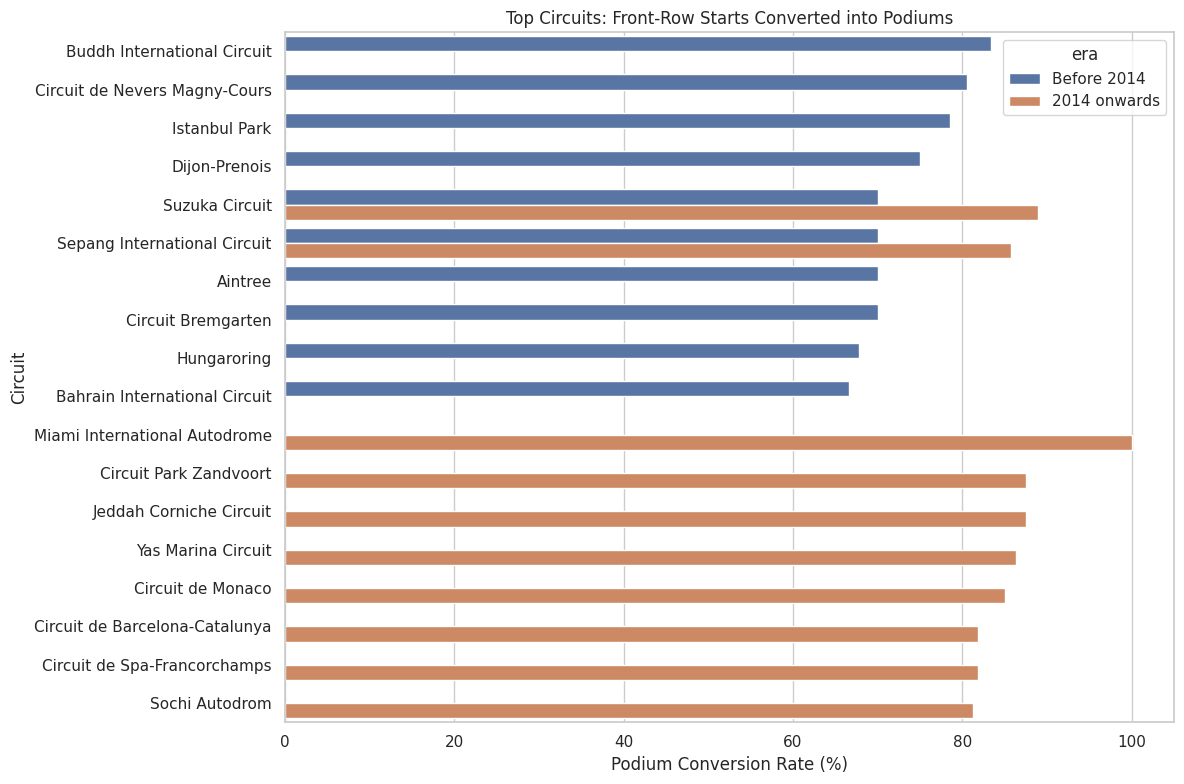


=== QUALIFYING POSITION VS STARTING GRID ===
Drivers compared: 10407
Drivers with different qualifying and grid positions: 2422
Missing qualifying positions: 16174


,raceId,driverId,year,circuit,qualifying_position,grid
3,18,4,2008,Albert Park Grand Prix Circuit,12.0,11
5,18,6,2008,Albert Park Grand Prix Circuit,14.0,13
6,18,7,2008,Albert Park Grand Prix Circuit,18.0,17
7,18,8,2008,Albert Park Grand Prix Circuit,16.0,15
9,18,10,2008,Albert Park Grand Prix Circuit,9.0,18
10,18,11,2008,Albert Park Grand Prix Circuit,20.0,19
11,18,12,2008,Albert Park Grand Prix Circuit,21.0,20
15,18,16,2008,Albert Park Grand Prix Circuit,19.0,22
16,18,17,2008,Albert Park Grand Prix Circuit,15.0,14
17,18,18,2008,Albert Park Grand Prix Circuit,13.0,12



=== CIRCUIT RANKING BEFORE VS AFTER 2014 ===


era,2014 onwards,Before 2014,Rank Before,Rank After,Rank Change
circuit,,,,,
Suzuka Circuit,88.89,70.00,1,1,0
Circuit Park Zandvoort,87.50,58.33,12,2,10
Yas Marina Circuit,86.36,60.00,8,3,5
Sepang International Circuit,85.71,70.00,1,4,-3
Circuit de Monaco,85.00,49.17,20,5,15
Circuit de Barcelona-Catalunya,81.82,65.22,5,6,-1
Circuit de Spa-Francorchamps,81.82,53.85,17,6,11
Autódromo José Carlos Pace,78.95,59.68,10,8,2
Shanghai International Circuit,78.57,65.00,6,9,-3



=== RANKING CHANGE SUMMARY ===
Circuits compared: 21
Circuits with changed rankings: 18


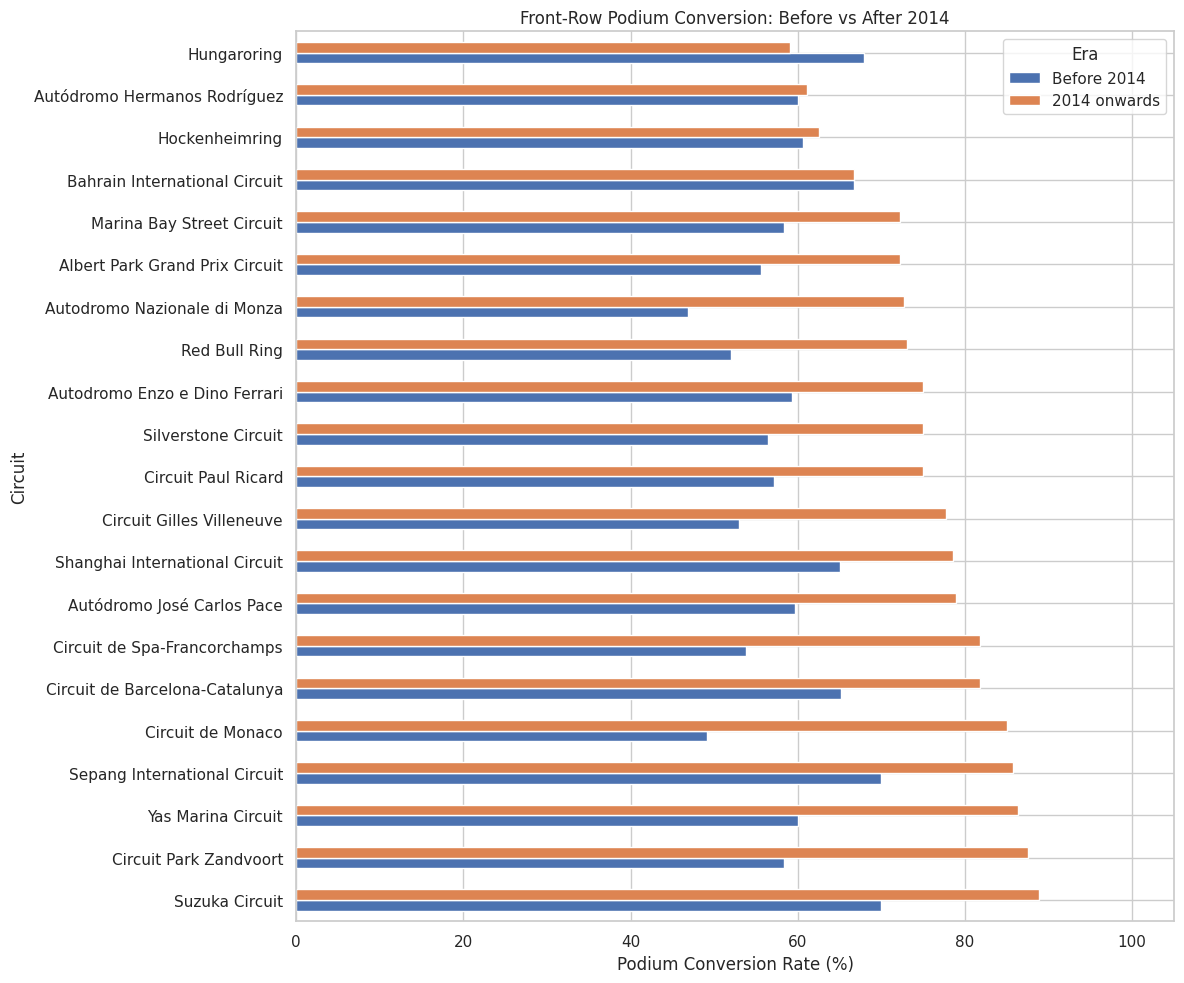


=== QUESTION 1 ANSWER ===
Highest before 2014: Buddh International Circuit (83.33%, 5/6 starts)
Highest from 2014 onwards: Miami International Autodrome (100.00%, 6/6 starts)
Among 21 circuits present in both eras, 18 changed ranking.

Note: Ranking changes are calculated only among circuits with enough starts in both eras.


In [16]:
# QUESTION 1: FRONT-ROW START TO PODIUM CONVERSION


# 1. JOIN THE REQUIRED TABLES

df = clean["results"][[
    "raceId", "driverId", "grid", "positionOrder"
]].merge(
    clean["races"][["raceId", "year", "circuitId"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["circuits"][["circuitId", "name"]],
    on="circuitId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["qualifying"][[
        "raceId", "driverId", "position"
    ]].rename(
        columns={"position": "qualifying_position"}
    ),
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

df = df.rename(columns={"name": "circuit"})

df["grid"] = pd.to_numeric(df["grid"], errors="coerce")
df["positionOrder"] = pd.to_numeric(
    df["positionOrder"], errors="coerce"
)
df["qualifying_position"] = pd.to_numeric(
    df["qualifying_position"], errors="coerce"
)

# 2. DEFINE PODIUM AND ERAS

# A podium means finishing in positions 1, 2 or 3.
df["podium"] = df["positionOrder"].between(1, 3).astype(int)

df["era"] = np.where(
    df["year"] < 2014,
    "Before 2014",
    "2014 onwards"
)

# 3. SELECT FRONT-ROW STARTERS

# Front row means actual starting grid position 1 or 2.
front = df[df["grid"].isin([1, 2])].copy()

print("=== FRONT-ROW STARTERS ===")
print("Total front-row starts:", len(front))
print("Total podiums:", front["podium"].sum())

# 4. CALCULATE PODIUM CONVERSION RATE

rates_all = front.groupby(
    ["circuit", "era"]
).agg(
    starts=("podium", "size"),
    podiums=("podium", "sum")
).reset_index()

rates_all["podium_rate"] = (
    rates_all["podiums"] / rates_all["starts"] * 100
)

# Require at least 5 front-row starts per circuit and era.
# This reduces the effect of very small samples.
rates = rates_all[
    rates_all["starts"] >= 5
].copy()

rates = rates.sort_values(
    ["era", "podium_rate", "starts"],
    ascending=[True, False, False]
)

print("\n=== FRONT-ROW PODIUM CONVERSION BY CIRCUIT ===")
display(rates.round(2))

# 5. SHOW TOP 5 CIRCUITS IN EACH ERA

before = rates[
    rates["era"] == "Before 2014"
].sort_values(
    ["podium_rate", "starts"],
    ascending=[False, False]
)

after = rates[
    rates["era"] == "2014 onwards"
].sort_values(
    ["podium_rate", "starts"],
    ascending=[False, False]
)

print("\n=== TOP 5 CIRCUITS BEFORE 2014 ===")
display(before.head(5).round(2))

print("\n=== TOP 5 CIRCUITS FROM 2014 ONWARDS ===")
display(after.head(5).round(2))

# 6. VISUALIZE TOP CIRCUITS IN EACH ERA

top = pd.concat([
    before.head(10),
    after.head(10)
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top,
    x="podium_rate",
    y="circuit",
    hue="era",
    hue_order=["Before 2014", "2014 onwards"]
)

plt.title("Top Circuits: Front-Row Starts Converted into Podiums")
plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

# 7. COMPARE QUALIFYING POSITION WITH ACTUAL GRID

# Only compare records with valid grid and qualifying positions.
# A grid of 0 is not a normal starting grid position.
comparison = df[
    (df["grid"] > 0) &
    (df["qualifying_position"] > 0)
].copy()

comparison["grid_changed"] = (
    comparison["grid"] != comparison["qualifying_position"]
)

print("\n=== QUALIFYING POSITION VS STARTING GRID ===")
print("Drivers compared:", len(comparison))
print(
    "Drivers with different qualifying and grid positions:",
    comparison["grid_changed"].sum()
)

print(
    "Missing qualifying positions:",
    df["qualifying_position"].isna().sum()
)

display(
    comparison.loc[
        comparison["grid_changed"],
        [
            "raceId", "driverId", "year",
            "circuit", "qualifying_position", "grid"
        ]
    ].head(10)
)

# 8. COMPARE CIRCUITS THAT APPEAR IN BOTH ERAS

# Only circuits with at least 5 front-row starts
# in each era are included in this comparison.

comparison_rates = rates.pivot(
    index="circuit",
    columns="era",
    values="podium_rate"
).dropna().copy()

comparison_rates["Rank Before"] = (
    comparison_rates["Before 2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

comparison_rates["Rank After"] = (
    comparison_rates["2014 onwards"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive = improved ranking after 2014.
# Negative = dropped in ranking after 2014.
comparison_rates["Rank Change"] = (
    comparison_rates["Rank Before"] -
    comparison_rates["Rank After"]
)

comparison_rates = comparison_rates.sort_values(
    "Rank After"
)

print("\n=== CIRCUIT RANKING BEFORE VS AFTER 2014 ===")
display(comparison_rates.round(2))

print("\n=== RANKING CHANGE SUMMARY ===")
print("Circuits compared:", len(comparison_rates))
print(
    "Circuits with changed rankings:",
    (comparison_rates["Rank Change"] != 0).sum()
)

# 9. VISUALIZE BEFORE VS AFTER 2014 FOR THE SAME CIRCUITS

comparison_rates[
    ["Before 2014", "2014 onwards"]
].plot(
    kind="barh",
    figsize=(12, 10)
)

plt.title("Front-Row Podium Conversion: Before vs After 2014")
plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.xlim(0, 105)
plt.legend(title="Era")
plt.tight_layout()
plt.show()

# 10. PRINT THE ANSWER AUTOMATICALLY

print("\n=== QUESTION 1 ANSWER ===")

if not before.empty:
    best_before = before.iloc[0]
    print(
        f"Highest before 2014: {best_before['circuit']} "
        f"({best_before['podium_rate']:.2f}%, "
        f"{int(best_before['podiums'])}/"
        f"{int(best_before['starts'])} starts)"
    )

if not after.empty:
    best_after = after.iloc[0]
    print(
        f"Highest from 2014 onwards: {best_after['circuit']} "
        f"({best_after['podium_rate']:.2f}%, "
        f"{int(best_after['podiums'])}/"
        f"{int(best_after['starts'])} starts)"
    )

changed = (comparison_rates["Rank Change"] != 0).sum()

print(
    f"Among {len(comparison_rates)} circuits present "
    f"in both eras, {changed} changed ranking."
)

print(
    "\nNote: Ranking changes are calculated only "
    "among circuits with enough starts in both eras."
)


Question 1 — Front-Row to Podium Conversion

The analysis joins results, races, circuits, and qualifying at the driver-race level. A front-row start means grid position 1 or 2, and a podium means finishing in the top 3.

The podium conversion rate is calculated for each circuit before 2014 and from 2014 onwards. Circuits with fewer than 5 front-row starts per era are excluded to reduce the effect of small samples. Rankings are compared for circuits appearing in both periods.

Actual starting grid is used instead of qualifying position because penalties can change a driver's starting position. Missing qualifying positions are excluded from that comparison, but do not prevent the use of valid grid results.

Grid position is known before the race, while the finishing position is only known afterward.

### Question 2 — home-country podium advantage

Match driver nationality to circuit country and compare home versus away podium rates while accounting for starting-grid position.

=== UNMAPPED NATIONALITIES ===
['American-Italian', 'Argentine-Italian']

Rows before filtering: 26668
Rows after filtering: 25030

=== OVERALL HOME VS AWAY PODIUM RATES ===


,starts,podiums,podium_rate
home_race,,,
False,22708,3119,13.74
True,2322,260,11.20



=== PODIUM RATES BY STARTING GRID ===


,grid_group,home_race,starts,podiums,podium_rate
0,1-3,False,3111,1723,55.38
1,1-3,True,266,143,53.76
6,4-6,False,3117,811,26.02
7,4-6,True,260,63,24.23
8,7-10,False,4117,380,9.23
9,7-10,True,384,32,8.33
2,11-15,False,5125,152,2.97
3,11-15,True,471,15,3.18
4,16+,False,7238,53,0.73
5,16+,True,941,7,0.74


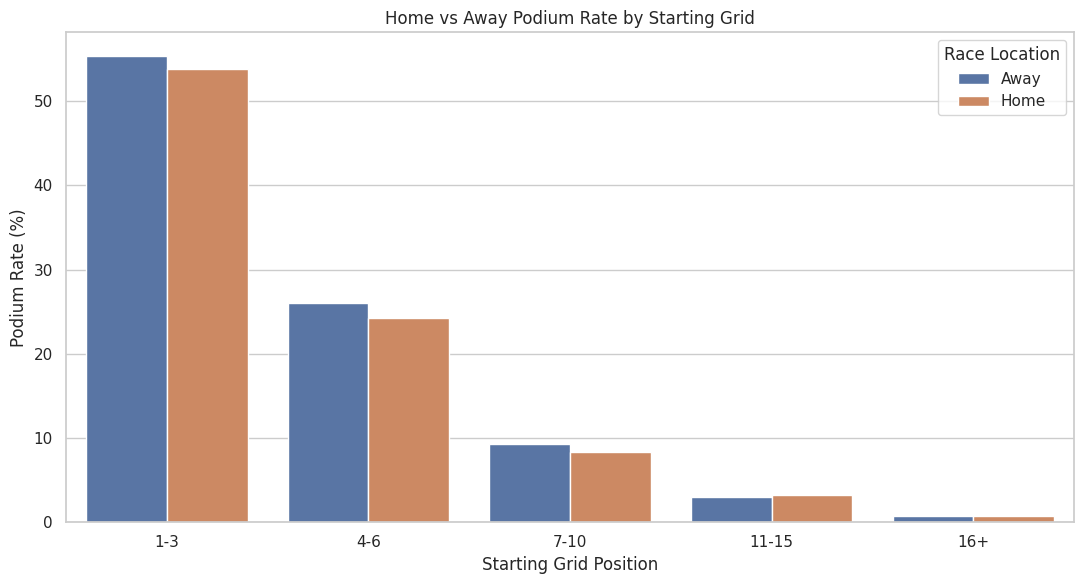


=== HOME ADVANTAGE BY GRID GROUP ===


home_race,Away (%),Home (%),Difference (pp)
grid_group,,,
1-3,55.38,53.76,-1.62
4-6,26.02,24.23,-1.79
7-10,9.23,8.33,-0.90
11-15,2.97,3.18,0.22
16+,0.73,0.74,0.01



=== GRID-ADJUSTED PODIUM RATES ===
Home: 12.98%
Away: 13.54%
Difference: -0.57 percentage points

=== QUESTION 2 ANSWER ===
Drivers had a lower podium rate at home after controlling for starting position.
Note: Nationality is used as a proxy for home country. Dual or unknown nationalities are excluded.


In [17]:
# QUESTION 2: HOME-COUNTRY PODIUM ADVANTAGE


# 1. Join results, races, circuits and drivers.
home = clean["results"][[
    "raceId", "driverId", "grid", "positionOrder"
]].merge(
    clean["races"][["raceId", "circuitId"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="inner",
    validate="many_to_one"
)

# 2. Convert driver nationalities to countries.
home["nationality"] = home["nationality"].str.strip()

nationality_to_country = {
    "American": "USA",
    "Argentine": "Argentina",
    "Argentinian": "Argentina",
    "Australian": "Australia",
    "Austrian": "Austria",
    "Belgian": "Belgium",
    "Brazilian": "Brazil",
    "British": "UK",
    "Canadian": "Canada",
    "Chinese": "China",
    "Colombian": "Colombia",
    "Czech": "Czech Republic",
    "Danish": "Denmark",
    "Dutch": "Netherlands",
    "Finnish": "Finland",
    "French": "France",
    "German": "Germany",
    "Hungarian": "Hungary",
    "Indian": "India",
    "Indonesian": "Indonesia",
    "Irish": "Ireland",
    "Italian": "Italy",
    "Japanese": "Japan",
    "Malaysian": "Malaysia",
    "Mexican": "Mexico",
    "Monegasque": "Monaco",
    "New Zealander": "New Zealand",
    "Polish": "Poland",
    "Portuguese": "Portugal",
    "Russian": "Russia",
    "South African": "South Africa",
    "Spanish": "Spain",
    "Swedish": "Sweden",
    "Swiss": "Switzerland",
    "Thai": "Thailand",
    "Uruguayan": "Uruguay",
    "Venezuelan": "Venezuela",
    "Chilean": "Chile",
    "East German": "Germany",
    "Liechtensteiner": "Liechtenstein",
    "Rhodesian": "Zimbabwe"
}

# Dual nationalities are ambiguous, so exclude them.
home["driver_country"] = home["nationality"].map(
    nationality_to_country
)

country_aliases = {
    "United States": "USA",
    "United Kingdom": "UK",
    "Great Britain": "UK",
    "UAE": "United Arab Emirates",
    "Korea": "South Korea"
}

home["circuit_country"] = home["country"].replace(
    country_aliases
)

home["driver_country"] = home["driver_country"].replace(
    country_aliases
)

print("=== UNMAPPED NATIONALITIES ===")
print(sorted(
    home.loc[
        home["driver_country"].isna(),
        "nationality"
    ].dropna().unique()
))

# 3. Remove rows with invalid grid or unknown country.
home["grid"] = pd.to_numeric(
    home["grid"], errors="coerce"
)

home["positionOrder"] = pd.to_numeric(
    home["positionOrder"], errors="coerce"
)

print("\nRows before filtering:", len(home))

home = home[
    (home["grid"] > 0) &
    home["positionOrder"].notna() &
    home["driver_country"].notna() &
    home["circuit_country"].notna()
].copy()

print("Rows after filtering:", len(home))

# 4. Identify home races and podium finishes.
home["home_race"] = (
    home["driver_country"] == home["circuit_country"]
)

home["podium"] = home["positionOrder"].between(
    1, 3
).astype(int)

# 5. Overall podium rates.
overall = home.groupby("home_race")["podium"].agg(
    starts="size",
    podiums="sum",
    podium_rate="mean"
)

overall["podium_rate"] *= 100

print("\n=== OVERALL HOME VS AWAY PODIUM RATES ===")
display(overall.round(2))

# 6. Group similar starting grid positions.
def grid_group(grid):
    if grid <= 3:
        return "1-3"
    elif grid <= 6:
        return "4-6"
    elif grid <= 10:
        return "7-10"
    elif grid <= 15:
        return "11-15"
    else:
        return "16+"

home["grid_group"] = home["grid"].apply(grid_group)

grid_order = ["1-3", "4-6", "7-10", "11-15", "16+"]

# 7. Calculate podium rates for each starting group.
grid_rates = home.groupby(
    ["grid_group", "home_race"]
)["podium"].agg(
    starts="size",
    podiums="sum",
    podium_rate="mean"
).reset_index()

grid_rates["podium_rate"] *= 100

grid_rates["grid_group"] = pd.Categorical(
    grid_rates["grid_group"],
    categories=grid_order,
    ordered=True
)

grid_rates = grid_rates.sort_values(
    ["grid_group", "home_race"]
)

print("\n=== PODIUM RATES BY STARTING GRID ===")
display(grid_rates.round(2))

# 8. Visualize home vs away for each grid group.
plt.figure(figsize=(11, 6))

sns.barplot(
    data=grid_rates,
    x="grid_group",
    y="podium_rate",
    hue="home_race",
    hue_order=[False, True],
    order=grid_order,
    errorbar=None
)

plt.title("Home vs Away Podium Rate by Starting Grid")
plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.legend(
    title="Race Location",
    labels=["Away", "Home"]
)
plt.tight_layout()
plt.show()

# 9. Compare home and away rates directly.
comparison2 = grid_rates.pivot(
    index="grid_group",
    columns="home_race",
    values="podium_rate"
)

comparison2 = comparison2.rename(
    columns={
        False: "Away (%)",
        True: "Home (%)"
    }
)

comparison2["Difference (pp)"] = (
    comparison2["Home (%)"] - comparison2["Away (%)"]
)

print("\n=== HOME ADVANTAGE BY GRID GROUP ===")
display(comparison2.round(2))

# 10. Calculate grid-adjusted podium rates.
# Use identical grid-group weights for home and away.
counts = home["grid_group"].value_counts(
    normalize=True
)

valid_groups = comparison2.dropna(
    subset=["Home (%)", "Away (%)"]
).index

weights = counts.reindex(valid_groups)
weights = weights / weights.sum()

adjusted_home = (
    comparison2.loc[valid_groups, "Home (%)"] * weights
).sum()

adjusted_away = (
    comparison2.loc[valid_groups, "Away (%)"] * weights
).sum()

difference = adjusted_home - adjusted_away

print("\n=== GRID-ADJUSTED PODIUM RATES ===")
print(f"Home: {adjusted_home:.2f}%")
print(f"Away: {adjusted_away:.2f}%")
print(f"Difference: {difference:+.2f} percentage points")

# 11. Print the answer.
print("\n=== QUESTION 2 ANSWER ===")

if difference > 0:
    print(
        "Drivers had a higher podium rate at home "
        "after controlling for starting position."
    )
elif difference < 0:
    print(
        "Drivers had a lower podium rate at home "
        "after controlling for starting position."
    )
else:
    print(
        "Home and away podium rates were equal "
        "after controlling for starting position."
    )

print(
    "Note: Nationality is used as a proxy for home country. "
    "Dual or unknown nationalities are excluded."
)


### Question 2 — Home-country podium comparison (grid-adjusted association)

The analysis joins results, races, circuits and drivers at the driver–race grain. It compares home and away podium rates **within similar starting-grid groups**, using nationality as a proxy for home country. Missing nationality or invalid grids are excluded.

**Interpret the rates printed by the code and the accompanying plot**, not a fixed percentage copied from an earlier run. Grid stratification reduces one obvious source of confounding, but does not adjust for all differences in driver skill, team, circuit, season or nationality mapping. A small or negative adjusted home–away difference **does not establish a causal effect or prove that home advantage is absent**. Podium labels are post-race outcomes used only for analysis, not as pre-race features.

### Question 3 — mechanical retirements

Join results to race years, constructors, and retirement status; compare mechanical retirement rates for 2014–2021 and 2022–2024.

=== NON-START ENTRIES EXCLUDED ===


,status,count
0,Withdrew,14



=== MECHANICAL FAILURE REASONS ===


,status,count
0,Engine,81
1,Brakes,49
2,Gearbox,42
3,Power Unit,42
4,Suspension,25
5,Hydraulics,15
6,Electrical,14
7,Power loss,13
8,Wheel,11
9,Oil leak,10



=== MECHANICAL FAILURES WITH ZERO LAPS ===
Total: 24


,year,constructor,status,grid,laps
22345,2014,Caterham,Power Unit,20,0
22458,2015,Lotus F1,Power loss,8,0
22482,2015,Manor Marussia,Fuel system,0,0
22522,2015,McLaren,ERS,20,0
22622,2015,Sauber,Gearbox,16,0
22662,2015,Force India,Power loss,11,0
22865,2016,Ferrari,Engine,3,0
22866,2016,Renault,Hydraulics,19,0
23344,2017,McLaren,Power Unit,17,0
23364,2017,McLaren,Power Unit,15,0



=== MECHANICAL RETIREMENT RATES BY CONSTRUCTOR ===


,constructor,period,starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
14,Lotus F1,2014-2021,75,13,17.33
28,Toro Rosso,2014-2021,242,38,15.70
17,McLaren,2014-2021,318,46,14.47
25,Renault,2014-2021,200,28,14.00
26,Sauber,2014-2021,200,22,11.00
23,Red Bull,2014-2021,319,33,10.34
2,AlphaTauri,2014-2021,78,8,10.26
16,Marussia,2014-2021,31,3,9.68
12,Haas F1 Team,2014-2021,241,23,9.54



=== TOP 10 CONSTRUCTORS IN EACH PERIOD ===


,constructor,period,starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
14,Lotus F1,2014-2021,75,13,17.33
28,Toro Rosso,2014-2021,242,38,15.70
17,McLaren,2014-2021,318,46,14.47
25,Renault,2014-2021,200,28,14.00
26,Sauber,2014-2021,200,22,11.00
23,Red Bull,2014-2021,319,33,10.34
2,AlphaTauri,2014-2021,78,8,10.26
16,Marussia,2014-2021,31,3,9.68
12,Haas F1 Team,2014-2021,241,23,9.54


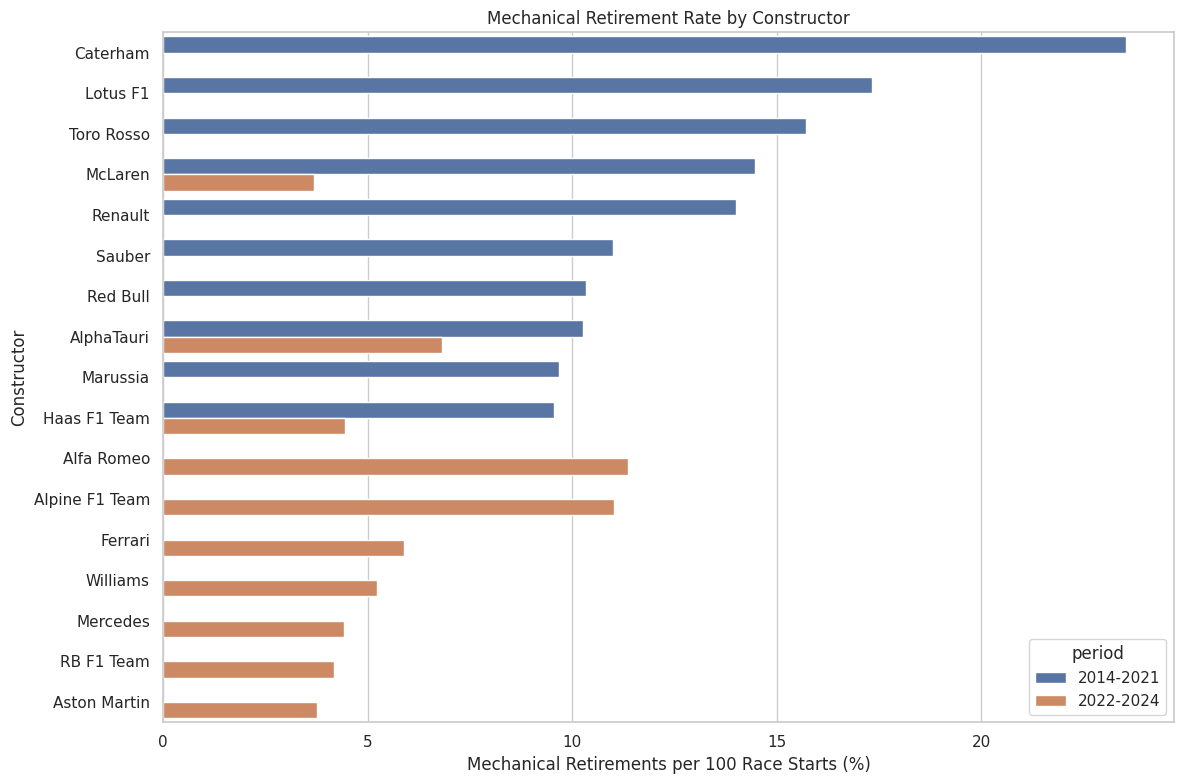


=== CONSTRUCTOR COMPARISON BETWEEN PERIODS ===


period,2014-2021,2022-2024,Difference (pp)
constructor,,,
Alfa Romeo,4.17,11.36,7.20
Alpine F1 Team,6.82,11.03,4.21
Aston Martin,2.27,3.76,1.49
Mercedes,4.06,4.41,0.35
Ferrari,6.25,5.88,-0.37
Williams,7.52,5.22,-2.30
AlphaTauri,10.26,6.82,-3.44
Haas F1 Team,9.54,4.44,-5.10
Red Bull,10.34,3.68,-6.67


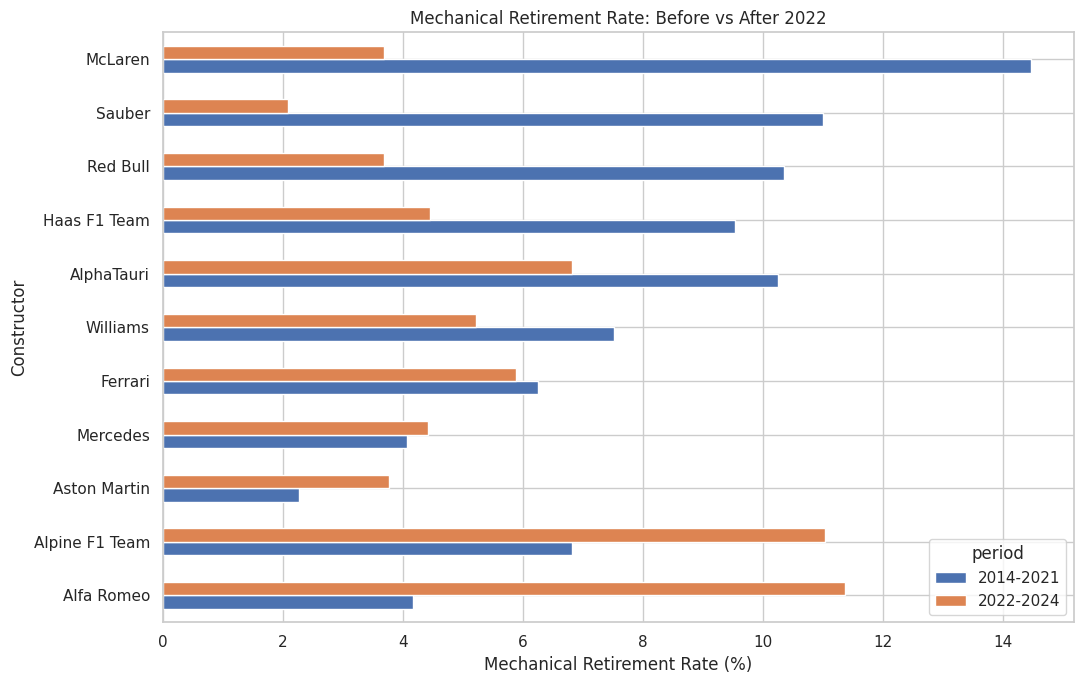


=== FINAL ANSWER: HIGHEST MECHANICAL RETIREMENT RATE ===
2014-2021: Caterham - 23.53% (8 retirements / 34 starts)
2022-2024: Alfa Romeo - 11.36% (10 retirements / 88 starts)

=== FINAL CHECKS ===
Total race starts analyzed: 4612
Total mechanical retirements: 388
Missing status descriptions: 0
Duplicate race-driver records: 0

Question 3 completed.


In [18]:
# QUESTION 3: MECHANICAL RETIREMENT RATES BY CONSTRUCTOR


# 1. JOIN THE TABLES

mechanical = clean["results"][[
    "raceId", "driverId", "constructorId",
    "grid", "laps", "statusId"
]].merge(
    clean["races"][["raceId", "year"]],
    on="raceId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["constructors"][["constructorId", "name"]],
    on="constructorId",
    how="inner",
    validate="many_to_one"
).merge(
    clean["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

mechanical = mechanical.rename(
    columns={"name": "constructor"}
)

# 2. KEEP 2014 TO 2024

mechanical = mechanical[
    mechanical["year"].between(2014, 2024)
].copy()

mechanical["period"] = np.where(
    mechanical["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)

# 3. DEFINE MECHANICAL FAILURES

mechanical_reasons = [
    "Engine",
    "Gearbox",
    "Transmission",
    "Clutch",
    "Hydraulics",
    "Electrical",
    "Electronics",
    "Suspension",
    "Brakes",
    "Brake duct",
    "Brake failure",
    "Wheel",
    "Wheel bearing",
    "Wheel nut",
    "Driveshaft",
    "Differential",
    "Alternator",
    "Battery",
    "Fuel system",
    "Fuel pump",
    "Fuel pressure",
    "Fuel leak",
    "Oil leak",
    "Oil pressure",
    "Oil pump",
    "Water leak",
    "Water pressure",
    "Water pump",
    "Cooling system",
    "Radiator",
    "Overheating",
    "Turbo",
    "Turbocharger",
    "Power Unit",
    "Power loss",
    "ERS",
    "MGU-K",
    "MGU-H",
    "Exhaust",
    "Throttle",
    "Steering",
    "Pneumatics",
    "Ignition",
    "Spark plugs",
    "Injection",
    "Vibrations",
    "Mechanical"
]

mechanical_set = {
    reason.lower() for reason in mechanical_reasons
}

mechanical["is_mechanical"] = (
    mechanical["status"]
    .fillna("")
    .str.strip()
    .str.lower()
    .isin(mechanical_set)
    .astype(int)
)

# 4. EXCLUDE DRIVERS WHO DID NOT START

non_start_reasons = [
    "Did not start",
    "Did not qualify",
    "Did not prequalify",
    "Withdrawn",
    "Withdrew",
    "Not classified as a starter"
]

non_start_set = {
    reason.lower() for reason in non_start_reasons
}

mechanical["is_start"] = ~(
    mechanical["status"]
    .fillna("")
    .str.strip()
    .str.lower()
    .isin(non_start_set)
)

print("=== NON-START ENTRIES EXCLUDED ===")

display(
    mechanical[~mechanical["is_start"]]["status"]
    .value_counts()
    .reset_index()
)

mechanical = mechanical[
    mechanical["is_start"]
].copy()

# 5. CHECK MECHANICAL FAILURE REASONS

print("\n=== MECHANICAL FAILURE REASONS ===")

failure_counts = (
    mechanical[mechanical["is_mechanical"] == 1]
    ["status"]
    .value_counts()
    .reset_index()
)

display(failure_counts)

# 6. CHECK ZERO-LAP MECHANICAL FAILURES
# Zero completed laps does not necessarily mean no start.
# A driver may retire during the first lap.

mechanical["laps"] = pd.to_numeric(
    mechanical["laps"], errors="coerce"
)

zero_lap_failures = mechanical[
    (mechanical["is_mechanical"] == 1) &
    (mechanical["laps"] == 0)
]

print("\n=== MECHANICAL FAILURES WITH ZERO LAPS ===")
print("Total:", len(zero_lap_failures))

display(
    zero_lap_failures[[
        "year", "constructor", "status", "grid", "laps"
    ]]
)

# 7. CALCULATE MECHANICAL RETIREMENT RATES

rates3 = mechanical.groupby(
    ["constructor", "period"]
)["is_mechanical"].agg(
    starts="size",
    mechanical_retirements="sum"
).reset_index()

rates3["retirement_rate"] = (
    rates3["mechanical_retirements"] /
    rates3["starts"] * 100
)

# Minimum 20 race starts in each period.
rates3 = rates3[
    rates3["starts"] >= 20
].copy()

rates3 = rates3.sort_values(
    ["period", "retirement_rate"],
    ascending=[True, False]
)

print("\n=== MECHANICAL RETIREMENT RATES BY CONSTRUCTOR ===")

display(rates3.round(2))

# 8. TOP CONSTRUCTORS IN EACH PERIOD

print("\n=== TOP 10 CONSTRUCTORS IN EACH PERIOD ===")

top3 = (
    rates3.groupby("period", group_keys=False)
    .head(10)
)

display(top3.round(2))

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top3,
    x="retirement_rate",
    y="constructor",
    hue="period",
    errorbar=None
)

plt.title("Mechanical Retirement Rate by Constructor")
plt.xlabel("Mechanical Retirements per 100 Race Starts (%)")
plt.ylabel("Constructor")
plt.tight_layout()
plt.show()

# 9. COMPARE CONSTRUCTORS PRESENT IN BOTH PERIODS

comparison3 = rates3.pivot(
    index="constructor",
    columns="period",
    values="retirement_rate"
).dropna()

comparison3["Difference (pp)"] = (
    comparison3["2022-2024"] -
    comparison3["2014-2021"]
)

comparison3 = comparison3.sort_values(
    "Difference (pp)", ascending=False
)

print("\n=== CONSTRUCTOR COMPARISON BETWEEN PERIODS ===")

display(comparison3.round(2))

if not comparison3.empty:
    comparison3[["2014-2021", "2022-2024"]].plot(
        kind="barh",
        figsize=(11, 7)
    )

    plt.title("Mechanical Retirement Rate: Before vs After 2022")
    plt.xlabel("Mechanical Retirement Rate (%)")
    plt.ylabel("Constructor")
    plt.tight_layout()
    plt.show()

# 10. FINAL ANSWER

print("\n=== FINAL ANSWER: HIGHEST MECHANICAL RETIREMENT RATE ===")

for period in ["2014-2021", "2022-2024"]:
    period_data = rates3[
        rates3["period"] == period
    ].sort_values("retirement_rate", ascending=False)

    if not period_data.empty:
        winner = period_data.iloc[0]

        print(
            f"{period}: {winner['constructor']} - "
            f"{winner['retirement_rate']:.2f}% "
            f"({int(winner['mechanical_retirements'])} "
            f"retirements / {int(winner['starts'])} starts)"
        )

# 11. FINAL QUALITY CHECKS

print("\n=== FINAL CHECKS ===")

print("Total race starts analyzed:", len(mechanical))
print("Total mechanical retirements:", mechanical["is_mechanical"].sum())
print("Missing status descriptions:", mechanical["status"].isna().sum())
print(
    "Duplicate race-driver records:",
    mechanical.duplicated(["raceId", "driverId"]).sum()
)

print("\nQuestion 3 completed.")


### Question 3 — Mechanical retirement rates

This analysis combines results, race years, constructors and status descriptions. It counts mechanical failures such as engine or gearbox problems, but excludes crashes and non-starts. We compare 2014–2021 with 2022–2024. Only constructors with at least 20 starts in a period are ranked.

The table and chart above show which constructors have the highest rates. A higher rate means more recorded mechanical retirements per start, not necessarily that one constructor caused the failures. Retirement reasons can be incomplete or unclear. These outcomes are used only for analysis, never as prediction inputs.


## 3. Feature Selection & Engineering

All features below are computed so that, for a given (raceId, driverId) row, they use
only information available after qualifying and before the race starts — consistent
with our prediction cutoff. "Form" and "standings" features are built with
groupby + shift so that a race never sees its own result or any future race's result.

Each feature group is introduced with a short hypothesis from our earlier EDA/terminology
review, then checked against the data before being kept.

### Create the driver–race modeling table

Assemble the binary podium target and the information needed to construct pre-race predictors. Each `(raceId, driverId)` should occur once.
**Target convention:** The model predicts whether the driver is among the first three entries in the source `results.positionOrder` field. This is not asserted to reproduce every historically awarded trophy or post-penalty official podium. A separate audit below reports disagreements with numeric classified position.


In [19]:
# ============================================================
# BASE MODELING TABLE: one row per (raceId, driverId)
# ============================================================

model_df = clean["results"][[
    "raceId", "driverId", "constructorId", "grid", "positionOrder"
]].merge(
    clean["races"][["raceId", "year", "round", "date", "circuitId"]],
    on="raceId", how="inner", validate="many_to_one"
)

# Pre-race driver age (available before the event); preserve the original race grain.
_driver_birth = clean["drivers"][["driverId", "dob"]].drop_duplicates("driverId").copy()
_driver_birth["dob"] = pd.to_datetime(_driver_birth["dob"], errors="coerce")
model_df = model_df.merge(_driver_birth, on="driverId", how="left", validate="many_to_one")
model_df["driver_age"] = ((pd.to_datetime(model_df["date"], errors="coerce") - model_df["dob"]).dt.days / 365.2425)
model_df.loc[~model_df["driver_age"].between(15, 80), "driver_age"] = np.nan
model_df["race_round"] = pd.to_numeric(model_df["round"], errors="coerce")

model_df["grid"] = pd.to_numeric(model_df["grid"], errors="coerce")
model_df["positionOrder"] = pd.to_numeric(model_df["positionOrder"], errors="coerce")

# grid 0 = pit-lane / non-standard start, not pole: place it behind the field
field_max = model_df.groupby("raceId")["grid"].transform("max")
model_df.loc[model_df["grid"] == 0, "grid"] = field_max + 1

# Target: podium finish (positionOrder <= 3)
model_df["podium"] = model_df["positionOrder"].between(1, 3).astype(int)

# --- Qualifying features ---
q = clean["qualifying"][["raceId", "driverId", "position", "q1_seconds", "q2_seconds", "q3_seconds"]].copy()
q = q.rename(columns={"position": "qualifying_position"})
q["qualifying_position"] = pd.to_numeric(q["qualifying_position"], errors="coerce")

# Best available qualifying lap per driver (Q1, Q2 or Q3, whichever is fastest)
q_times = q[["q1_seconds", "q2_seconds", "q3_seconds"]].apply(pd.to_numeric, errors="coerce")
q_times = q_times.where(q_times > 0)          # guard against 0 / invalid times
q["best_quali_time"] = q_times.min(axis=1, skipna=True)


model_df = model_df.merge(q, on=["raceId", "driverId"], how="left", validate="one_to_one")

# Fastest qualifying lap in the same race (any session)
pole_time = model_df.groupby("raceId")["best_quali_time"].transform("min")
model_df["quali_gap_to_fastest"] = model_df["best_quali_time"] - pole_time
model_df["quali_gap_pct"] = model_df["quali_gap_to_fastest"] / pole_time * 100
model_df["quali_gap_missing"] = model_df["quali_gap_to_fastest"].isna().astype(int)

# Grid vs qualifying: captures penalties (grid worse than earned pace)
model_df["grid_vs_quali_diff"] = model_df["grid"] - model_df["qualifying_position"]
model_df["grid_worse_than_qualifying"] = np.where(
    model_df["qualifying_position"].isna(),
    np.nan,
    (model_df["grid_vs_quali_diff"] > 0).astype(float)
)

model_df = model_df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

print(model_df.shape)
model_df.tail(20)


(26668, 23)


,raceId,driverId,constructorId,grid,positionOrder,year,round,date,circuitId,dob,...,qualifying_position,q1_seconds,q2_seconds,q3_seconds,best_quali_time,quali_gap_to_fastest,quali_gap_pct,quali_gap_missing,grid_vs_quali_diff,grid_worse_than_qualifying
26648,1144,1,131,16,4,2024,24,2024-12-08,24,1985-01-07,...,18.0,83.887,NaN,NaN,83.887,1.292,1.564259,0,-2.0,0.0
26649,1144,4,117,8,9,2024,24,2024-12-08,24,1981-07-29,...,8.0,83.794,83.268,83.196,83.196,0.601,0.727647,0,0.0,0.0
26650,1144,807,210,7,8,2024,24,2024-12-08,24,1987-08-19,...,4.0,83.722,83.040,82.886,82.886,0.291,0.352322,0,3.0,1.0
26651,1144,815,9,10,20,2024,24,2024-12-08,24,1990-01-26,...,10.0,83.559,83.379,83.264,83.264,0.669,0.809976,0,0.0,0.0
26652,1144,822,15,9,18,2024,24,2024-12-08,24,1989-08-28,...,9.0,83.481,83.341,83.204,83.204,0.609,0.737333,0,0.0,0.0
26653,1144,825,210,14,16,2024,24,2024-12-08,24,1992-10-05,...,15.0,83.632,83.877,NaN,83.632,1.037,1.255524,0,-1.0,0.0
26654,1144,830,9,4,6,2024,24,2024-12-08,24,1997-09-30,...,5.0,83.516,82.998,82.945,82.945,0.350,0.423754,0,-1.0,0.0
26655,1144,832,6,3,2,2024,24,2024-12-08,24,1994-09-01,...,3.0,83.487,82.985,82.824,82.824,0.229,0.277256,0,0.0,0.0
26656,1144,840,117,13,14,2024,24,2024-12-08,24,1998-10-29,...,13.0,83.729,83.784,NaN,83.729,1.134,1.372964,0,0.0,0.0
26657,1144,842,214,5,7,2024,24,2024-12-08,24,1996-02-07,...,6.0,83.548,83.086,82.984,82.984,0.389,0.470973,0,-1.0,0.0


### Verify the specified podium target (do not silently change it)

The assignment explicitly defines the label as `positionOrder <= 3`. We retain **that exact definition**, rather than replacing it with the text `position` field. The next audit checks disagreement with classified numeric positions and shows examples. A discrepancy is a historical-data caveat, not permission to redefine the task. The target is used for training/evaluation only, never as a feature.

In [20]:
label_audit = clean["results"][["raceId", "driverId", "positionOrder", "position"]].copy()
label_audit["position_numeric"] = pd.to_numeric(label_audit["position"], errors="coerce")
label_audit["ordered_podium"] = pd.to_numeric(label_audit["positionOrder"], errors="coerce").between(1, 3)
label_audit["classified_podium"] = label_audit["position_numeric"].between(1, 3)
comparable = label_audit["position_numeric"].notna()
disagreements = label_audit[comparable & (label_audit["ordered_podium"] != label_audit["classified_podium"])]
print("Entries with numeric classified position:", int(comparable.sum()))
print("Disagreements between ordered and classified podium:", len(disagreements))
print("Missing numeric classified position:", int((~comparable).sum()))
print("Races not containing exactly three ordered top-three entries:", int((label_audit.groupby("raceId")["ordered_podium"].sum() != 3).sum()))
display(disagreements.head(15))


Entries with numeric classified position: 15751
Disagreements between ordered and classified podium: 1
Missing numeric classified position: 10917
Races not containing exactly three ordered top-three entries: 4


,raceId,driverId,positionOrder,position,position_numeric,ordered_podium,classified_podium
10657,452,172,3,4.0,4.0,True,False


**Qualifying gap and grid interpretation:** `quali_gap_to_fastest` is the driver's observed Qualyfing time minus the fastest **observed Qualyfingtime in that race**. It is not the pole lap. Missing Q1 laps stay missing and are imputed by a pipeline fitted **only on training rows**; `quali_gap_missing` records their absence. `grid_worse_than_qualifying` means the starting grid is worse than the recorded qualifying position; it is a *proxy for movement* and **not proof of a formal penalty**. Grid positions and qualifying positions may differ for several reasons.

### Hypothesis: grid position is the dominant predictor

From the terminology doc and Question 1's analysis, pole/front-row starts convert to
podiums at a high rate. We check this directly against the target before committing
to the feature.

### Evidence for starting-grid features

Visualize podium frequency by grid bucket as an exploratory justification for including starting position.

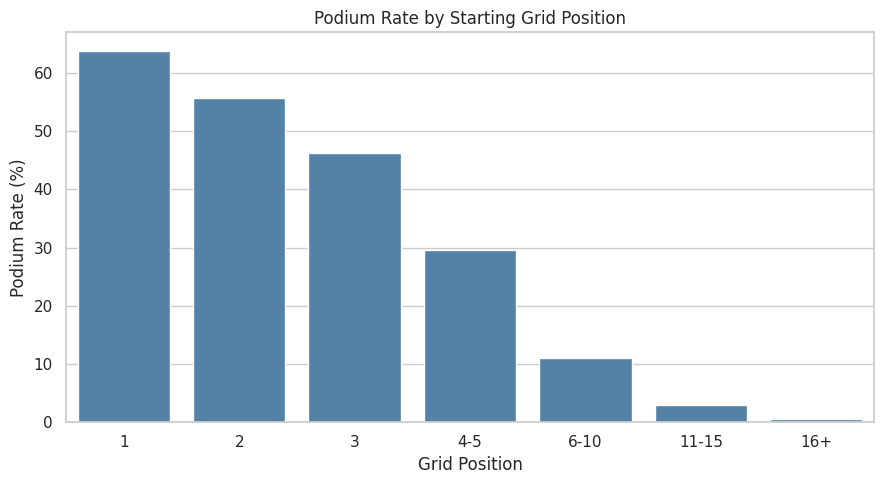

Point-biserial correlation (grid, podium): -0.436
Point-biserial correlation (quali_gap_to_fastest, podium): -0.073


In [21]:
# ============================================================
# EDA: podium rate by grid position bucket
# ============================================================

grid_valid = model_df[model_df["grid"] > 0].copy()
grid_valid["grid_bucket"] = pd.cut(
    grid_valid["grid"],
    bins=[0, 1, 2, 3, 5, 10, 15, 100],
    labels=["1", "2", "3", "4-5", "6-10", "11-15", "16+"]
)

grid_podium = grid_valid.groupby("grid_bucket", observed=False)["podium"].agg(
    starts="size", podium_rate="mean"
).reset_index()
grid_podium["podium_rate"] *= 100

plt.figure(figsize=(9, 5))
sns.barplot(data=grid_podium, x="grid_bucket", y="podium_rate", color="steelblue")
plt.title("Podium Rate by Starting Grid Position")
plt.xlabel("Grid Position")
plt.ylabel("Podium Rate (%)")
plt.tight_layout()
plt.show()

print(f"Point-biserial correlation (grid, podium): "
      f"{grid_valid['grid'].corr(grid_valid['podium']):.3f}")
print(f"Point-biserial correlation (quali_gap_to_fastest, podium): "
      f"{model_df['quali_gap_to_fastest'].corr(model_df['podium']):.3f}")


### Build historical driver and constructor form

Calculate rolling summaries from earlier results, using shifts to avoid including the current race outcome in its own predictors.

In [22]:
# ============================================================
# DRIVER AND CONSTRUCTOR "FORM" FEATURES (leakage-safe)
# ============================================================
# shift(1) before rolling/expanding ensures the CURRENT race's result
# is never used to build its own feature.

model_df = model_df.sort_values(["driverId", "date"])

g = model_df.groupby("driverId")
model_df["driver_past_starts"] = g.cumcount()
model_df["driver_podium_rate_last5"] = g["podium"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)
model_df["driver_avg_finish_last5"] = g["positionOrder"].transform(
    lambda s: s.shift(1).rolling(5, min_periods=1).mean()
)
model_df["driver_career_podium_rate"] = g["podium"].transform(
    lambda s: s.shift(1).expanding(min_periods=1).mean()
)

# Aggregate constructor results once per completed race, not per driver entry.
# Every driver for the same constructor/race receives identical pre-race form.
constructor_races = (model_df.groupby(["constructorId", "raceId", "date"], as_index=False)
    .agg(constructor_race_podium=("podium", "max"),
         constructor_race_finish=("positionOrder", "mean")))
constructor_races = constructor_races.sort_values(["constructorId", "date", "raceId"])
gc = constructor_races.groupby("constructorId")
constructor_races["constructor_past_starts"] = gc.cumcount()
constructor_races["constructor_podium_rate_last5"] = gc["constructor_race_podium"].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean())
constructor_races["constructor_avg_finish_last5"] = gc["constructor_race_finish"].transform(
    lambda x: x.shift(1).rolling(5, min_periods=1).mean())
model_df = model_df.merge(constructor_races[["constructorId", "raceId",
    "constructor_past_starts", "constructor_podium_rate_last5", "constructor_avg_finish_last5"]],
    on=["constructorId", "raceId"], how="left", validate="many_to_one")

model_df = model_df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)

print("Driver form missing (first race for a driver):", model_df["driver_podium_rate_last5"].isna().sum())
print("Constructor form missing (first race for a constructor):", model_df["constructor_podium_rate_last5"].isna().sum())


Driver form missing (first race for a driver): 861
Constructor form missing (first race for a constructor): 347


### Visualize historical form and podium outcomes

Inspect relationships between historical form measures and the binary podium target.

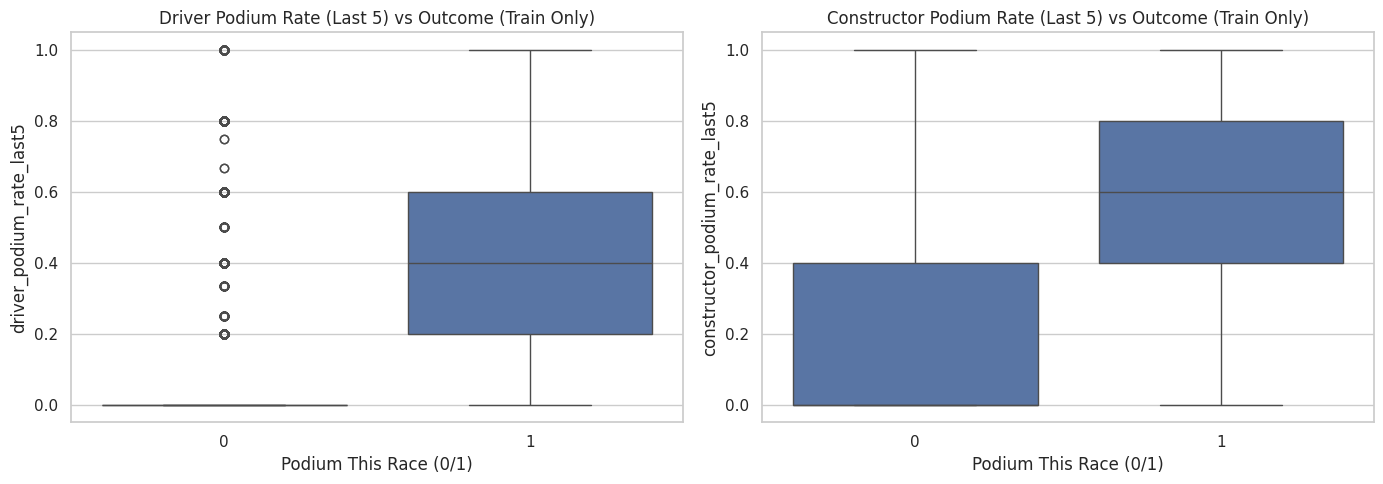

driver_podium_rate_last5         0.464053
constructor_podium_rate_last5    0.414856
podium                           1.000000
Name: podium, dtype: float64


In [23]:
# ============================================================
# EDA: form features vs podium outcome
# ============================================================

# Target-dependent feature EDA is restricted to training seasons to protect the held-out test set.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=model_df.loc[model_df["year"] <= 2019], x="podium", y="driver_podium_rate_last5", ax=axes[0])
axes[0].set_title("Driver Podium Rate (Last 5) vs Outcome (Train Only)")
axes[0].set_xlabel("Podium This Race (0/1)")

sns.boxplot(data=model_df.loc[model_df["year"] <= 2019], x="podium", y="constructor_podium_rate_last5", ax=axes[1])
axes[1].set_title("Constructor Podium Rate (Last 5) vs Outcome (Train Only)")
axes[1].set_xlabel("Podium This Race (0/1)")

plt.tight_layout()
plt.show()

print(model_df.loc[model_df["year"] <= 2019, ["driver_podium_rate_last5", "constructor_podium_rate_last5", "podium"]].corr()["podium"])


### Create standings entering each race

Use prior-round standings rather than current-race standings, which would contain information unavailable before race start.

**Merge safety:** The standings snapshot’s `raceId` is renamed `historical_raceId` before `merge_asof`. This preserves the entrant race’s `raceId`, avoids pandas suffix collisions, and asserts that any matched standings came from an earlier round. Missing previous standings produce zero points and a missing rank (handled by the model imputer).

In [24]:
# ============================================================
# CHAMPIONSHIP STANDINGS ENTERING THE RACE (leakage-safe)
# ============================================================
# driver_standings / constructor_standings store cumulative totals
# AFTER each race. We shift by one round WITHIN THE SAME SEASON
# (points reset each year) to get "standing before this race".

# Standings tables are post-race snapshots. For a given entrant, use the most recent
# earlier round in the SAME season, even if that entrant has no snapshot for the prior round.
def prior_standings(table, entity, prefix):
    history = clean[table][["raceId", entity, "points", "position"]].merge(
        clean["races"][["raceId", "year", "round"]], on="raceId", how="inner")
    history = history.sort_values([entity, "year", "round", "raceId"]).drop_duplicates(
        [entity, "year", "round"], keep="last")
    entrant = model_df[["raceId", entity, "year", "round"]].drop_duplicates().copy()
    # Strict inequality on rounds prevents use of this race's completed standings.
    history = history.rename(columns={"round": "historical_round", "raceId": "historical_raceId"})
    matched = pd.merge_asof(
        entrant.sort_values("round"),
        history.sort_values("historical_round"),
        left_on="round", right_on="historical_round", by=[entity, "year"],
        direction="backward", allow_exact_matches=False)
    matched[f"{prefix}_points_before"] = matched["points"].fillna(0)
    matched[f"{prefix}_standing_before"] = matched["position"]
    # raceId belongs to the entrant; historical_raceId identifies an earlier race.
    assert "raceId" in matched.columns and "historical_raceId" in matched.columns
    used = matched["historical_raceId"].notna()
    assert (matched.loc[used, "historical_round"] < matched.loc[used, "round"]).all()
    assert not matched.duplicated(["raceId", entity]).any()
    return matched[["raceId", entity, f"{prefix}_points_before", f"{prefix}_standing_before"]]

ds = prior_standings("driver_standings", "driverId", "driver")
cs = prior_standings("constructor_standings", "constructorId", "constructor")
# --- Guard: drop these columns if they already exist, so re-running this cell is safe ---
driver_cols = ["driver_points_before", "driver_standing_before"]
constructor_cols = ["constructor_points_before", "constructor_standing_before"]

model_df = model_df.drop(columns=[c for c in driver_cols + constructor_cols if c in model_df.columns],
                          errors="ignore")

# --- One merge per table ---
model_df = model_df.merge(
    ds[["raceId", "driverId"] + driver_cols],
    on=["raceId", "driverId"], how="left", validate="one_to_one"
).merge(
    cs[["raceId", "constructorId"] + constructor_cols],
    on=["raceId", "constructorId"], how="left", validate="many_to_one"
)

print("Missing driver_points_before:", model_df["driver_points_before"].isna().sum())
print("Missing constructor_points_before:", model_df["constructor_points_before"].isna().sum())
print("Missing constructor_standing_before:", model_df["constructor_standing_before"].isna().sum())


Missing driver_points_before: 0
Missing constructor_points_before: 0
Missing constructor_standing_before: 3525


### Add historical regulation-era categories

Encode the season era and inspect how podium outcomes vary across historical periods.

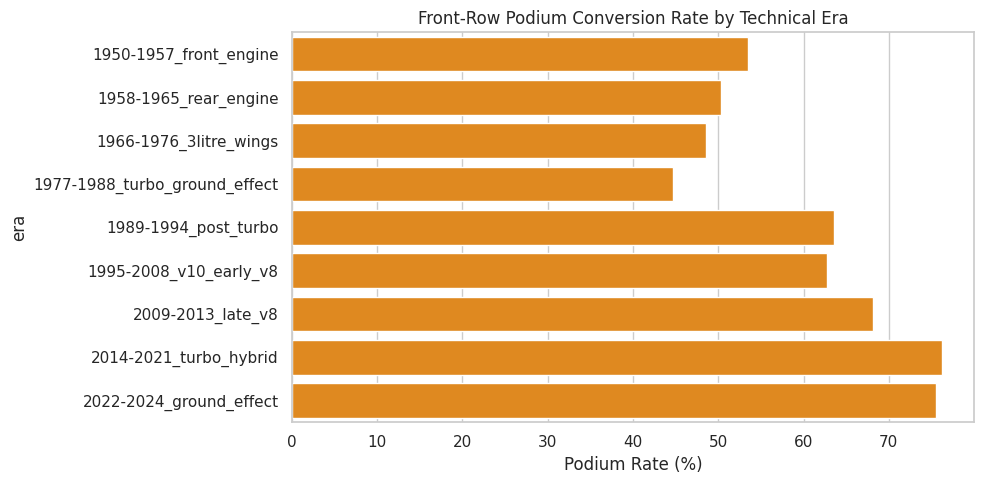

,era,starts,podium_rate
0,1950-1957_front_engine,129,53.488372
1,1958-1965_rear_engine,155,50.322581
2,1966-1976_3litre_wings,278,48.561151
3,1977-1988_turbo_ground_effect,376,44.680851
4,1989-1994_post_turbo,192,63.541667
5,1995-2008_v10_early_v8,478,62.761506
6,2009-2013_late_v8,188,68.085106
7,2014-2021_turbo_hybrid,319,76.175549
8,2022-2024_ground_effect,135,75.555556


In [25]:
# ============================================================
# ERA FEATURE (captures regulation changes that reshuffle competitiveness)
# ============================================================

def assign_era(year):
    if year >= 2022: return "2022-2024_ground_effect"
    if year >= 2014: return "2014-2021_turbo_hybrid"
    if year >= 2009: return "2009-2013_late_v8"
    if year >= 1995: return "1995-2008_v10_early_v8"
    if year >= 1989: return "1989-1994_post_turbo"
    if year >= 1977: return "1977-1988_turbo_ground_effect"
    if year >= 1966: return "1966-1976_3litre_wings"
    if year >= 1958: return "1958-1965_rear_engine"
    return "1950-1957_front_engine"

model_df["era"] = model_df["year"].apply(assign_era)

era_podium = (
    model_df[model_df["grid"].isin([1, 2])]  # front-row only, same logic as Q1
    .groupby("era")["podium"].agg(starts="size", podium_rate="mean").reset_index()
)
era_podium["podium_rate"] *= 100

plt.figure(figsize=(10, 5))
sns.barplot(data=era_podium.sort_values("era"), x="podium_rate", y="era", color="darkorange")
plt.title("Front-Row Podium Conversion Rate by Technical Era")
plt.xlabel("Podium Rate (%)")
plt.tight_layout()
plt.show()

display(era_podium.sort_values("era"))


### Add home-race indicator

Reuse the nationality-to-country mapping to derive whether the driver is racing in their home country.

In [26]:
# ============================================================
# HOME-RACE FLAG (reuses the nationality->country mapping from Question 2)
# ============================================================

model_df = model_df.merge(
    clean["drivers"][["driverId", "nationality"]], on="driverId", how="left"
).merge(
    clean["circuits"][["circuitId", "country"]], on="circuitId", how="left"
)

model_df["driver_country"] = model_df["nationality"].str.strip().map(nationality_to_country)
model_df["circuit_country"] = model_df["country"].replace(country_aliases)
model_df["driver_country"] = model_df["driver_country"].replace(country_aliases)

model_df["home_race"] = (
    (model_df["driver_country"] == model_df["circuit_country"]) &
    model_df["driver_country"].notna()
).astype(int)

print("Home races flagged:", model_df["home_race"].sum(), "/", len(model_df))


Home races flagged: 2490 / 26668


### Assemble feature candidates and correlations

List engineered predictors and inspect their relationships with the podium label. Correlation is descriptive evidence, not causality.

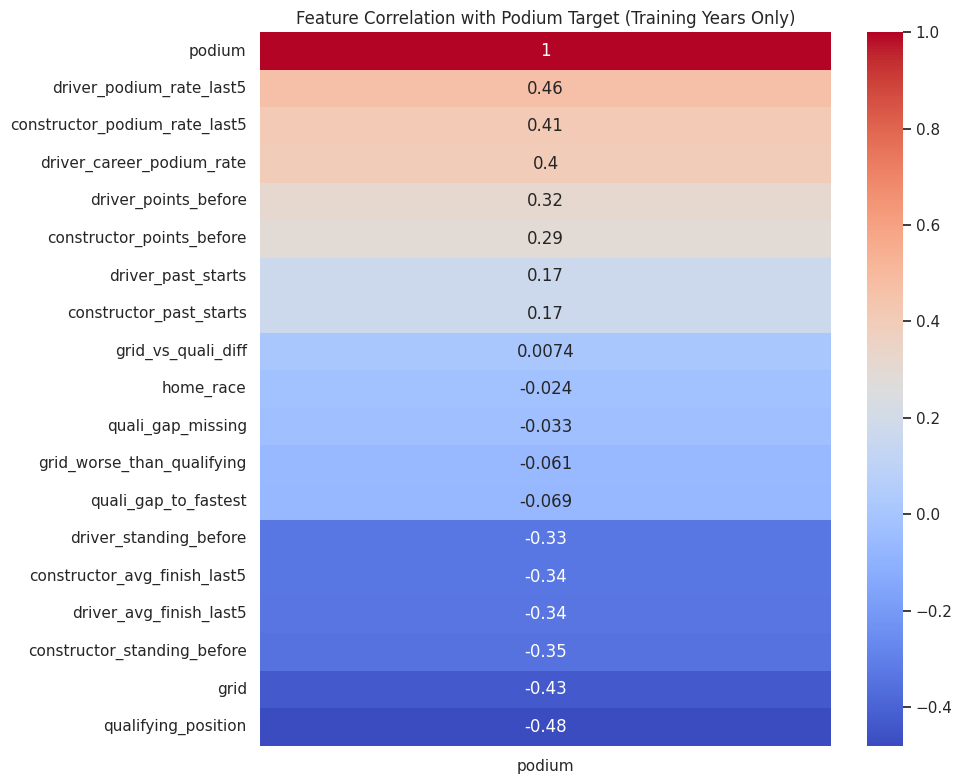

In [27]:
# ============================================================
# FINAL FEATURE SET AND TRAINING-ONLY CORRELATION WITH TARGET
# ============================================================

feature_cols = [
    "grid", "qualifying_position", "quali_gap_to_fastest", "quali_gap_missing",
    "grid_vs_quali_diff", "grid_worse_than_qualifying",
    "driver_podium_rate_last5", "driver_avg_finish_last5", "driver_career_podium_rate",
    "driver_past_starts",
    "constructor_podium_rate_last5", "constructor_avg_finish_last5", "constructor_past_starts",
    "driver_points_before", "driver_standing_before",
    "constructor_points_before", "constructor_standing_before",
    "home_race"
]

numeric_features = [c for c in feature_cols if model_df[c].dtype != "object"]

plt.figure(figsize=(10, 8))
corr = model_df.loc[model_df["year"] <= 2019, numeric_features + ["podium"]].corr()
sns.heatmap(corr[["podium"]].sort_values("podium", ascending=False), annot=True, cmap="coolwarm")
plt.title("Feature Correlation with Podium Target (Training Years Only)")
plt.tight_layout()
plt.show()


### Train / Validation / Test split

We use a **time-based (season) split**, not a random split:

- **Train:** seasons ≤ 2019
- **Validation:** seasons 2020–2021
- **Test:** seasons ≥ 2022

Reasons:
1. **No temporal leakage.** A random split would let the model train on a 2023 race
   and validate on a 2021 race from the same driver/constructor, indirectly leaking
   future car performance into the past.
2. **Realistic deployment scenario.** In practice we would always be predicting a
   future, not-yet-run race using only past data — the split should mirror that.
3. **Natural regulation boundary.** The test set (≥2022) sits entirely in the new
   ground-effect ruleset, which is a genuine distribution shift (per our era EDA) —
   a good, honest stress-test of generalization.
4. Our form/standings features already respect chronology via `shift()`, so splitting
   by season on top of that does not introduce any additional leakage risk.

**Validation safeguard:** The preliminary feature-selection trials above use 2020–2021 only. The 2022–2024 test years must be reserved for the final model evaluation.


### Create chronological train/validation/test sets

Use earlier seasons for training, 2020–2021 for validation, and 2022–2024 for final testing to respect time order.

In [28]:
# ============================================================
# TRAIN / VALIDATION / TEST SPLIT (season-based)
# ============================================================

final_df = model_df.dropna(subset=["podium"]).copy()

train_df = final_df[final_df["year"] <= 2019]
val_df   = final_df[(final_df["year"] >= 2020) & (final_df["year"] <= 2021)]
test_df  = final_df[final_df["year"] >= 2022]

for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:12s} rows: {len(d):6d}  seasons: {d['year'].min()}-{d['year'].max()}  "
          f"podium rate: {d['podium'].mean()*100:.2f}%")


Train        rows:  24529  seasons: 1950-2019  podium rate: 12.47%
Validation   rows:    780  seasons: 2020-2021  podium rate: 15.00%
Test         rows:   1359  seasons: 2022-2024  podium rate: 15.01%


### Empirical justification: does each feature group add value?

Beyond correlations, we run a quick logistic-regression check adding one feature
group at a time, measured by ROC-AUC on a simple hold-out split. This is a
preliminary, lightweight check — the full feature-group ablation on the final
models comes later in Section 5.

### Preliminary cumulative feature-group trials

Compare progressively larger feature groups with logistic regression. **Validation years 2020–2021 are used for these trials; the final 2022–2024 test period remains unseen.**

The trials reuse the chronological training and validation subsets created above; the held-out test set is not used to choose features.

In [29]:
# ============================================================
# EMPIRICAL TRIAL: cumulative feature-group value (quick check)
# ============================================================

def quick_auc(cols, label):
    imputer = SimpleImputer(strategy="median")
    X_train = imputer.fit_transform(train_df[cols])
    X_val = imputer.transform(val_df[cols])
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    model.fit(X_train, train_df["podium"])
    preds = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(val_df["podium"], preds)
    print(f"{label:40s} AUC = {auc:.4f}  (features: {len(cols)})")
    return auc

print("=== CUMULATIVE FEATURE-GROUP TRIALS ===")
t1 = quick_auc(["grid"], "Trial 1: grid only")
t2 = quick_auc(["grid", "qualifying_position", "quali_gap_to_fastest", "grid_vs_quali_diff"],
                "Trial 2: + qualifying features")
t3 = quick_auc(["grid", "qualifying_position", "quali_gap_to_fastest", "grid_vs_quali_diff",
                 "driver_podium_rate_last5", "driver_avg_finish_last5",
                 "constructor_podium_rate_last5", "constructor_avg_finish_last5"],
                "Trial 3: + driver & constructor form")
t4 = quick_auc(["grid", "qualifying_position", "quali_gap_to_fastest", "grid_vs_quali_diff",
                 "driver_podium_rate_last5", "driver_avg_finish_last5",
                 "constructor_podium_rate_last5", "constructor_avg_finish_last5",
                 "driver_points_before", "constructor_points_before", "home_race"],
                "Trial 4: + standings & home race")


=== CUMULATIVE FEATURE-GROUP TRIALS ===
Trial 1: grid only                       AUC = 0.9094  (features: 1)
Trial 2: + qualifying features           AUC = 0.9203  (features: 4)
Trial 3: + driver & constructor form     AUC = 0.9240  (features: 8)
Trial 4: + standings & home race         AUC = 0.9246  (features: 11)


### Candidate feature rationale (the selected subset is reported dynamically below)

The **18 numeric predictors** in `feature_cols` are the common feature set used by Logistic Regression, Random Forest and the shallow neural network. **None of these three models is a baseline** — the only baseline model in this notebook is the single-feature grid-only logistic regression, introduced after these three in Section 4.1. The final selected model is reported dynamically by the code below (`best_name`, `best_features`), .

| Feature group | Inputs in common 18-feature set | Reason to test | Cutoff / limitation |
|---|---|---|---|
| Grid | `grid` | Starting position strongly relates to podium opportunity | Recorded grid may differ from actual start in historical cases |
| Qualifying | `qualifying_position`, `quali_gap_to_fastest`, `quali_gap_missing`, `grid_vs_quali_diff`, `grid_worse_than_qualifying` | Pre-race pace, missing coverage and grid changes | Q1 gap is **not** the pole lap; grid change is **not proof of a penalty** |
| Driver form | `driver_podium_rate_last5`, `driver_avg_finish_last5`, `driver_career_podium_rate`, `driver_past_starts` | Past performance and experience | Earlier races only; shifted histories |
| Constructor form | `constructor_podium_rate_last5`, `constructor_avg_finish_last5`, `constructor_past_starts` | Historical team competitiveness | Earlier races only; constructor podium means any driver on podium |
| Championship standings | `driver_points_before`, `driver_standing_before`, `constructor_points_before`, `constructor_standing_before` | Season-to-date competitiveness | Previous-round snapshot within season; never current-race standings |
| Home | `home_race` | Test home familiarity hypothesis | Country matching is approximate; weak evidence is not causation |

`era` is explored in EDA but **is not in this 18-feature set**. We compare feature groups and candidate sets on the same validation period; apparent importance does not imply causation.

### Targeted candidate-feature comparison

Compare the base feature set against three optional features using the same training and validation years. Do not choose features based on test performance.

In [30]:
# ============================================================
# TARGETED CHECK: do the three weakest individual features help?
# ============================================================

base_features = [
    "grid", "qualifying_position",
    "driver_podium_rate_last5", "driver_avg_finish_last5",
    "constructor_podium_rate_last5", "constructor_avg_finish_last5",
]

t_base = quick_auc(base_features, "Base: grid + quali_position + form")
t_plus_gap = quick_auc(base_features + ["quali_gap_to_fastest"], "Base + quali_gap_to_fastest")
t_plus_penalty = quick_auc(base_features + ["grid_vs_quali_diff"], "Base + grid_vs_quali_diff")
t_plus_home = quick_auc(base_features + ["home_race"], "Base + home_race")


Base: grid + quali_position + form       AUC = 0.9211  (features: 6)
Base + quali_gap_to_fastest              AUC = 0.9209  (features: 7)
Base + grid_vs_quali_diff                AUC = 0.9237  (features: 7)
Base + home_race                         AUC = 0.9211  (features: 7)


### Feature availability and fairness audit

We should have **three directly comparable models**. Logistic Regression, Random Forest and the shallow neural network below are first trained on **exactly the same rows and the same 18 numeric features**. Additional feature sets are clearly labeled as experiments, not substitutes for that controlled comparison set. None of these three is a baseline model — see Section 4.1 for the notebook's one and only baseline. Every feature must be known at the cutoff after qualifying and before the start. The following assertions check key invariants; they do not prove the raw dataset is perfect.

In [31]:
assert model_df[["raceId", "driverId"]].notna().all().all()
assert not model_df.duplicated(["raceId", "driverId"]).any()
assert model_df["podium"].isin([0, 1]).all()
assert set(feature_cols).isdisjoint({"positionOrder", "podium", "statusId", "points", "laps", "milliseconds", "rank"})
assert (model_df["quali_gap_to_fastest"].dropna() >= -1e-8).all(), "Q1 gaps must be nonnegative"
assert model_df["quali_gap_missing"].equals(model_df["quali_gap_to_fastest"].isna().astype(int))
print("Unique driver-race rows:", len(model_df))
print("Podium prevalence:", round(model_df["podium"].mean(), 4))
print("Missing Q1 gaps:", int(model_df["quali_gap_to_fastest"].isna().sum()))
print("Feature counts:", len(feature_cols), "(common feature set; not a baseline)")
print("Feature list:", feature_cols)


Unique driver-race rows: 26668
Podium prevalence: 0.1267
Missing Q1 gaps: 16330
Feature counts: 18 (common feature set; not a baseline)
Feature list: ['grid', 'qualifying_position', 'quali_gap_to_fastest', 'quali_gap_missing', 'grid_vs_quali_diff', 'grid_worse_than_qualifying', 'driver_podium_rate_last5', 'driver_avg_finish_last5', 'driver_career_podium_rate', 'driver_past_starts', 'constructor_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_past_starts', 'driver_points_before', 'driver_standing_before', 'constructor_points_before', 'constructor_standing_before', 'home_race']


## 4. Modeling and evaluation

**Prediction cutoff:** after qualifying, before the race. The podium outcome is never an input. Imputation and scaling are fitted using training rows only. **Train:** through 2019; **validation:** 2020–2021; **held-out test:** 2022–2024.

**Primary selection metric: validation F1** (balances precision and recall for podium classification). **Secondary: validation PR-AUC / average precision** (ranks rare podium outcomes); **ROC-AUC** is also reported. We report accuracy, precision and recall for context. Logistic Regression, Random Forest and a shallow two-hidden-layer MLP are three common-feature **candidate models** (none of them a baseline) trained on the **same 18 features and the same rows**, before separately labeled feature/model experiments. The notebook's **one and only baseline** is the grid-only logistic regression introduced in Section 4.1. Hyperparameters, feature subsets, thresholds and optional race-level Top 3 strategy are selected using validation only. Scores on the held-out test set must never be used to reselect the model.

### Benchmark and dataset sanity checks

Validation podium prevalence (~15%) is the **chance-level PR-AUC reference**: any useful model must clear it. Rather than a trivial always-negative classifier (which trivially scores F1 = 0 and tells us nothing about whether our engineered features earn their complexity), the **one and only baseline model in this notebook** is a **grid-only logistic regression** — built with the exact same preprocessing/threshold pipeline as every other candidate, immediately after the three common-feature models in Section 4.1. If the full feature set can't beat a model that only knows starting grid position, the extra features aren't adding value. The logistic regression, random forest and neural network trained on the full feature set are candidate models, not baselines. This benchmark is evaluated on validation, never used to tune on test.

In [32]:
#baseline sanity checks (dummy classifier removed: it only showed the trivial F1=0 floor,
# which the validation podium prevalence below already captures without a model to discard)

assert not final_df.duplicated(["raceId", "driverId"]).any()
assert final_df["date"].notna().all()
assert final_df["year"].between(1950, 2024).all()
assert set(train_df["raceId"]).isdisjoint(val_df["raceId"])
assert set(val_df["raceId"]).isdisjoint(test_df["raceId"])

print("Validation podium prevalence (chance-level PR-AUC reference):", round(val_df.podium.mean(), 4))
print("Per-race entrant counts (validation):")
display(val_df.groupby("raceId").size().describe().to_frame("entrants"))
print("Per-race podium counts (validation):")
display(val_df.groupby("raceId").podium.sum().value_counts().sort_index().rename("races").to_frame())


Validation podium prevalence (chance-level PR-AUC reference): 0.15
Per-race entrant counts (validation):


,entrants
count,39.0
mean,20.0
std,0.0
min,20.0
25%,20.0
50%,20.0
75%,20.0
max,20.0


Per-race podium counts (validation):


,races
podium,
3,39


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, precision_recall_curve,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import warnings

SEED = 42
np.random.seed(SEED)
# Confirm the table is unique and the time split is nonoverlapping.
assert not final_df.duplicated(["raceId", "driverId"]).any()
assert set(train_df.raceId).isdisjoint(val_df.raceId)
assert set(val_df.raceId).isdisjoint(test_df.raceId)
assert set(train_df.raceId).isdisjoint(test_df.raceId)
assert train_df.year.max() < val_df.year.min() < test_df.year.min()
assert not any(x in feature_cols for x in ["podium", "positionOrder", "statusId", "points", "laps"])
assert all(pd.api.types.is_numeric_dtype(final_df[c]) for c in feature_cols)
assert set(final_df.podium.unique()).issubset({0, 1})
print("Validated unique grain, chronological split, and numeric feature list.")
print("Class balance:", {k: round(v.podium.mean(), 4) for k, v in
       [("train", train_df), ("validation", val_df), ("test", test_df)]})

Validated unique grain, chronological split, and numeric feature list.
Class balance: {'train': np.float64(0.1247), 'validation': np.float64(0.15), 'test': np.float64(0.1501)}


### 4.1 Candidate models (common feature set)

Median imputation handles incomplete historical records. Logistic regression and the neural network use standardized numeric features; the forest uses unscaled features. Class weighting is applied where supported. All three models use **exactly the same rows and feature columns**. The neural network has two hidden layers (32 and 16 units); early stopping uses a subset of training data, not the official validation or test years. **These three are candidate models** — the grid-only logistic regression added right after them is this notebook's one and only baseline.

In [34]:

def build_logistic_model():
    model = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=False)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
    ])
    return model


def build_forest_model():
    model = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=180, min_samples_leaf=5,
            max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1,
            random_state=SEED))
    ])
    return model


def build_neural_model():
    model = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(32, 16), alpha=0.01,
            early_stopping=True, validation_fraction=0.15, max_iter=250,
            n_iter_no_change=15, random_state=SEED))
    ])
    return model


def make_models(columns=feature_cols):
    return {
        "Logistic regression (18 features)": build_logistic_model(),
        "Random forest": build_forest_model(),
        "Shallow neural network": build_neural_model()
    }

def scores(y, probability, threshold=0.5):
    y = np.asarray(y).astype(int)
    predicted = (np.asarray(probability) >= threshold).astype(int)
    return {"Accuracy": accuracy_score(y, predicted),
            "PR-AUC": average_precision_score(y, probability),
            "ROC-AUC": roc_auc_score(y, probability),
            "F1": f1_score(y, predicted, zero_division=0),
            "Precision": precision_score(y, predicted, zero_division=0),
            "Recall": recall_score(y, predicted, zero_division=0)}

def choose_threshold(y, probability):
    """Pick the F1-maximizing validation cutoff from actual score breakpoints."""
    precision, recall, cutoffs = precision_recall_curve(np.asarray(y), np.asarray(probability))
    if len(cutoffs) == 0:
        return 0.5
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best = np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12))
    return float(cutoffs[best[-1]])

X_train, y_train = train_df[feature_cols], train_df["podium"]
X_val, y_val = val_df[feature_cols], val_df["podium"]
X_test, y_test = test_df[feature_cols], test_df["podium"]
models = make_models()
trained = {}
thresholds = {}
validation_rows = []
for name, pipeline in models.items():
    print("Training:", name)
    pipeline.fit(X_train, y_train)
    trained[name] = pipeline
    p_train = pipeline.predict_proba(X_train)[:, 1]
    p_val = pipeline.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(y_val, p_val)
    thresholds[name] = threshold
    for split, truth, pred in [("Train", y_train, p_train), ("Validation", y_val, p_val)]:
        validation_rows.append({"Model": name, "Split": split, "Threshold": threshold,
                                **scores(truth, pred, threshold)})
validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

Training: Logistic regression (18 features)
Training: Random forest
Training: Shallow neural network


,Model,Split,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Logistic regression (18 features),Train,0.7339,0.8769,0.5602,0.9060,0.5816,0.5047,0.6861
1,Logistic regression (18 features),Validation,0.7339,0.9064,0.7412,0.9294,0.7068,0.6667,0.7521
2,Random forest,Train,0.5259,0.9341,0.8924,0.9837,0.7797,0.6682,0.9359
3,Random forest,Validation,0.5259,0.9103,0.6963,0.9340,0.7034,0.6975,0.7094
4,Shallow neural network,Train,0.3247,0.8857,0.5969,0.9143,0.5932,0.5331,0.6684
5,Shallow neural network,Validation,0.3247,0.9077,0.7513,0.9280,0.6923,0.6923,0.6923


### 4.2 Validation-only model and feature tuning (F1 objective)

The project still reports **PR-AUC and ROC-AUC**, but this experiment selects a model by **validation F1**, which balances podium precision and recall. All candidate models are fitted on **1950–2019 training data**; 2020–2021 is used for model, feature-subset and decision-threshold selection. **2022–2024 is reserved for final reporting** and must not be used to choose a model.

We compare four fixed feature groups and modest regularization, tree, and shallow neural-network settings. We do not assume that using all 18 features is optimal. The threshold is selected from the validation precision–recall curve, rather than a coarse grid. Since we are trying several alternatives on a relatively small validation set, the best validation score may be optimistic. This is a targeted search, not proof of generalization.

In [35]:
# Candidate subsets: pre-race variables only; no feature importance computed from test data.
core = ["grid", "qualifying_position", "grid_vs_quali_diff",
        "driver_podium_rate_last5", "driver_avg_finish_last5",
        "constructor_podium_rate_last5", "constructor_avg_finish_last5"]
standings = ["driver_points_before", "driver_standing_before",
             "constructor_points_before", "constructor_standing_before"]
feature_sets = {
    "all_18": feature_cols,
    "core_7": core,
    "core_plus_standings_11": core + standings,
    "all_except_constructor_form": [c for c in feature_cols if c not in
        ["constructor_podium_rate_last5", "constructor_avg_finish_last5", "constructor_past_starts"]],
}
assert all(set(cols).issubset(feature_cols) for cols in feature_sets.values())

# Save each model's input columns: models trained on subsets cannot use all 18 at inference.
model_features = {name: feature_cols.copy() for name in trained}

# A small, reproducible search. Every imputer/scaler is fitted on training rows only.
candidates = {}
for subset_name, cols in feature_sets.items():
    for C in [0.1, 1.0]:
        name = f"Logistic tuned | {subset_name} | C={C}"
        candidates[name] = (cols, Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
            ("model", LogisticRegression(C=C, max_iter=3000,
                class_weight="balanced", random_state=SEED))
        ]))

# One conservative tree and one neural-network variant, keeping the original candidate-model configurations.
candidates["Forest tuned | core_plus_standings_11"] = (
    feature_sets["core_plus_standings_11"], Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("model", RandomForestClassifier(n_estimators=220, min_samples_leaf=12,
            max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1,
            random_state=SEED))
    ]))
candidates["Neural tuned | core_plus_standings_11"] = (
    feature_sets["core_plus_standings_11"], Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("model", MLPClassifier(hidden_layer_sizes=(16,), alpha=0.1,
            early_stopping=True, validation_fraction=0.15, max_iter=300,
            n_iter_no_change=20, random_state=SEED))
    ]))

# Additional shallow statistical candidates. These are fixed before inspecting test data.
from sklearn.ensemble import ExtraTreesClassifier

for subset_name in ["core_plus_standings_11", "all_18"]:
    cols = feature_sets[subset_name]
    for leaf in [5, 15]:
        name = f"Extra Trees | {subset_name} | leaf={leaf}"
        candidates[name] = (cols, Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("model", ExtraTreesClassifier(n_estimators=160, min_samples_leaf=leaf,
                max_features=0.8, class_weight="balanced", n_jobs=-1, random_state=SEED))
        ]))

for name, (cols, pipeline) in candidates.items():
    print("Training:", name)
    pipeline.fit(train_df[cols], y_train)
    trained[name] = pipeline
    model_features[name] = cols.copy()
    train_prob = pipeline.predict_proba(train_df[cols])[:, 1]
    val_prob = pipeline.predict_proba(val_df[cols])[:, 1]
    threshold = choose_threshold(y_val, val_prob)
    thresholds[name] = threshold
    for split, truth, prob in [("Train", y_train, train_prob),
                               ("Validation", y_val, val_prob)]:
        validation_rows.append({"Model": name, "Split": split,
            "Threshold": threshold, **scores(truth, prob, threshold)})

validation_results = pd.DataFrame(validation_rows)
comparison = validation_results.query("Split == 'Validation'").sort_values(
    ["F1", "PR-AUC", "ROC-AUC"], ascending=False)
display(comparison[["Model", "PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]].round(4))
print("Best validation F1 model:", comparison.iloc[0]["Model"])
print("Features used:", model_features[comparison.iloc[0]["Model"]])

Training: Logistic tuned | all_18 | C=0.1
Training: Logistic tuned | all_18 | C=1.0
Training: Logistic tuned | core_7 | C=0.1
Training: Logistic tuned | core_7 | C=1.0
Training: Logistic tuned | core_plus_standings_11 | C=0.1
Training: Logistic tuned | core_plus_standings_11 | C=1.0
Training: Logistic tuned | all_except_constructor_form | C=0.1
Training: Logistic tuned | all_except_constructor_form | C=1.0
Training: Forest tuned | core_plus_standings_11
Training: Neural tuned | core_plus_standings_11
Training: Extra Trees | core_plus_standings_11 | leaf=5
Training: Extra Trees | core_plus_standings_11 | leaf=15
Training: Extra Trees | all_18 | leaf=5
Training: Extra Trees | all_18 | leaf=15


,Model,PR-AUC,ROC-AUC,F1,Precision,Recall
1,Logistic regression (18 features),0.7412,0.9294,0.7068,0.6667,0.7521
33,Extra Trees | all_18 | leaf=15,0.7155,0.9284,0.7064,0.7034,0.7094
9,Logistic tuned | all_18 | C=1.0,0.7467,0.9328,0.7063,0.6593,0.7607
7,Logistic tuned | all_18 | C=0.1,0.7451,0.9324,0.7054,0.6855,0.7265
31,Extra Trees | all_18 | leaf=5,0.7035,0.9290,0.7036,0.6544,0.7607
17,Logistic tuned | core_plus_standings_11 | C=1.0,0.7274,0.9265,0.7034,0.6975,0.7094
15,Logistic tuned | core_plus_standings_11 | C=0.1,0.7273,0.9264,0.7034,0.6975,0.7094
3,Random forest,0.6963,0.9340,0.7034,0.6975,0.7094
23,Forest tuned | core_plus_standings_11,0.7203,0.9306,0.7027,0.7429,0.6667
19,Logistic tuned | all_except_constructor_form |...,0.7435,0.9320,0.7025,0.6800,0.7265


Best validation F1 model: Logistic regression (18 features)
Features used: ['grid', 'qualifying_position', 'quali_gap_to_fastest', 'quali_gap_missing', 'grid_vs_quali_diff', 'grid_worse_than_qualifying', 'driver_podium_rate_last5', 'driver_avg_finish_last5', 'driver_career_podium_rate', 'driver_past_starts', 'constructor_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_past_starts', 'driver_points_before', 'driver_standing_before', 'constructor_points_before', 'constructor_standing_before', 'home_race']


### 4.1 (continued) The baseline model: grid-only logistic regression

This is the **one and only baseline model in this notebook**. It is a logistic regression trained on `grid` alone, using the same `build_logistic_model()` pipeline, the same `choose_threshold()` rule, and the same `scores()` metrics as every other candidate, so it is directly comparable in every table below. It answers one question: how much do qualifying, form, constructor and standings features actually add over knowing only where a driver starts? The logistic regression, random forest and neural network above are **candidate models**, not baselines, whatever any earlier cell may have called them.

In [36]:
# ============================================================
# GRID-ONLY BASELINE (replaces the dummy classifier)
# ============================================================
grid_only_features = ["grid"]
grid_only_model = build_logistic_model()
grid_only_model.fit(train_df[grid_only_features], y_train)

trained["Grid-only logistic regression"] = grid_only_model
model_features["Grid-only logistic regression"] = grid_only_features

p_train = grid_only_model.predict_proba(train_df[grid_only_features])[:, 1]
p_val = grid_only_model.predict_proba(val_df[grid_only_features])[:, 1]
grid_only_threshold = choose_threshold(y_val, p_val)
thresholds["Grid-only logistic regression"] = grid_only_threshold

for split, truth, prob in [("Train", y_train, p_train), ("Validation", y_val, p_val)]:
    validation_rows.append({"Model": "Grid-only logistic regression", "Split": split,
                            "Threshold": grid_only_threshold, **scores(truth, prob, grid_only_threshold)})

validation_results = pd.DataFrame(validation_rows)
print("Grid-only logistic regression (the only baseline in this notebook) vs. the 18-feature logistic regression candidate:")
display(validation_results[validation_results.Model.isin(
    ["Grid-only logistic regression", "Logistic regression (18 features)"])].round(4))


Grid-only logistic regression (the only baseline in this notebook) vs. the 18-feature logistic regression candidate:


,Model,Split,Threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Logistic regression (18 features),Train,0.7339,0.8769,0.5602,0.9060,0.5816,0.5047,0.6861
1,Logistic regression (18 features),Validation,0.7339,0.9064,0.7412,0.9294,0.7068,0.6667,0.7521
34,Grid-only logistic regression,Train,0.8284,0.8855,0.4926,0.8899,0.5406,0.5407,0.5405
35,Grid-only logistic regression,Validation,0.8284,0.9077,0.6386,0.9094,0.6923,0.6923,0.6923


### Choose the model using validation results

The code ranks all trained candidates by validation F1. If two models have the same F1, it uses PR-AUC and then ROC-AUC to break the tie. The grid-only logistic regression is our simple baseline. The test years are not used to choose the model or its threshold.


Unconstrained argmax over 18 candidates selects: Logistic regression (18 features)
Selected model: Logistic regression (18 features) | Validation F1 threshold: 0.734


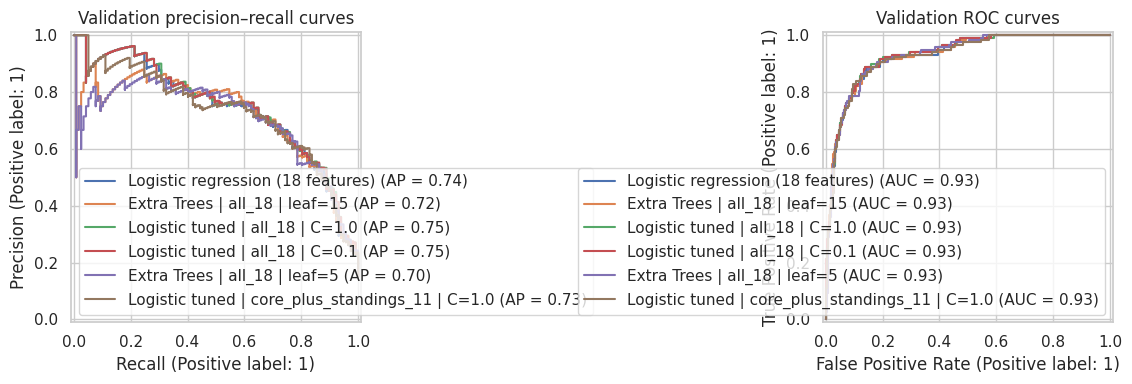

Chance-level PR-AUC reference (validation prevalence): 0.15
Selected feature count: 18 | Features: ['grid', 'qualifying_position', 'quali_gap_to_fastest', 'quali_gap_missing', 'grid_vs_quali_diff', 'grid_worse_than_qualifying', 'driver_podium_rate_last5', 'driver_avg_finish_last5', 'driver_career_podium_rate', 'driver_past_starts', 'constructor_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_past_starts', 'driver_points_before', 'driver_standing_before', 'constructor_points_before', 'constructor_standing_before', 'home_race']
Selected validation F1: 0.7068
18-feature logistic regression validation F1: 0.7068
Grid-only baseline validation F1: 0.6923


In [37]:
val_ranking = validation_results[validation_results.Split == "Validation"].sort_values(
    ["F1", "PR-AUC", "ROC-AUC"], ascending=False)

# Plain argmax over every trained candidate (common-feature models, tuned variants, the grid-only
# baseline, forest/neural variants) — no name filtering. The pre-declared rule is validation F1,
# with PR-AUC then ROC-AUC as tie-breakers, applied to whatever actually wins, not to a chosen family.
# Note: only "Grid-only logistic regression" is a baseline here; every other name in this dict is a
# candidate model.
best_name = val_ranking.iloc[0]["Model"]
print(f"Unconstrained argmax over {val_ranking['Model'].nunique()} candidates selects: {best_name}")

best_model = trained[best_name]
best_features = model_features[best_name]
best_threshold = thresholds[best_name]
print("Selected model:", best_name, "| Validation F1 threshold:", round(best_threshold, 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in val_ranking.head(6)["Model"]:
    pipeline = trained[name]
    p = pipeline.predict_proba(val_df[model_features[name]])[:, 1]
    PrecisionRecallDisplay.from_predictions(y_val, p, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_val, p, name=name, ax=axes[1])
axes[0].set_title("Validation precision–recall curves")
axes[1].set_title("Validation ROC curves")
plt.tight_layout(); plt.show()

print("Chance-level PR-AUC reference (validation prevalence):", round(y_val.mean(), 4))
print("Selected feature count:", len(best_features), "| Features:", best_features)
print("Selected validation F1:", round(float(val_ranking.iloc[0]["F1"]), 4))
print("18-feature logistic regression validation F1:", round(float(val_ranking.loc[val_ranking.Model == "Logistic regression (18 features)", "F1"].iloc[0]), 4))
print("Grid-only baseline validation F1:", round(float(val_ranking.loc[val_ranking.Model == "Grid-only logistic regression", "F1"].iloc[0]), 4))

### 4.4 Race-level Top-3 versus independent threshold predictions

**Motivation:** A standard Formula 1 Grand Prix awards three podium places. A binary threshold can select zero, two, five, or more drivers in the same race. We compare that existing method against selecting the **three highest predicted probabilities within each race**. The latter is only applicable when predictions for *all entrants in a race* are available, and it is not a guarantee of higher F1.

**Protocol:** All candidate models were fitted on 1950–2019 training seasons. The choice between threshold and race-level Top-3, and the final model, are determined **only using 2020–2021 validation F1**. Test seasons 2022–2024 are evaluated once after selection. PR-AUC/ROC-AUC are still calculated from probabilities, not hard labels. The race-level rule assumes exactly three podium outcomes among the represented drivers; historical anomalies or incomplete entry lists are a limitation.


In [38]:
def top_three_predictions(frame, probability):
    """Return one predicted podium for each of the top three scores per race.

    Requires a complete driver list per race, one row per driver-race, and
    probability aligned to frame row order. Grid is a deterministic tie-break.
    """
    assert len(frame) == len(probability)
    assert not frame.duplicated(["raceId", "driverId"]).any()
    temp = frame[["raceId", "driverId", "grid"]].copy().reset_index(drop=True)
    temp["probability"] = np.asarray(probability, dtype=float)
    assert np.isfinite(temp["probability"]).all()
    temp["tie_grid"] = pd.to_numeric(temp["grid"], errors="coerce").replace(0, np.nan).fillna(999)
    temp["row_number"] = np.arange(len(temp))
    ranked = temp.sort_values(["raceId", "probability", "tie_grid", "driverId"],
                              ascending=[True, False, True, True], kind="mergesort")
    ranked["pred"] = ranked.groupby("raceId").cumcount().lt(3).astype(int)
    return ranked.sort_values("row_number")["pred"].to_numpy(dtype=int)

race_comparison_rows = []
for name, model in trained.items():
    p = model.predict_proba(val_df[model_features[name]])[:, 1]
    for strategy in ["Threshold", "Race Top 3"]:
        pred = ((p >= thresholds[name]).astype(int) if strategy == "Threshold"
                else top_three_predictions(val_df, p))
        race_comparison_rows.append({
            "Model": name, "Strategy": strategy,
            "Validation F1": f1_score(y_val, pred, zero_division=0),
            "Precision": precision_score(y_val, pred, zero_division=0),
            "Recall": recall_score(y_val, pred, zero_division=0),
            "PR-AUC": average_precision_score(y_val, p),
            "ROC-AUC": roc_auc_score(y_val, p)
        })
race_comparison = pd.DataFrame(race_comparison_rows).sort_values(
    ["Validation F1", "PR-AUC", "ROC-AUC"], ascending=False).reset_index(drop=True)
display(race_comparison.head(15).round(4))

# Keep the selected model fixed to whichever candidate Section 4.3 selected.
# Compare its two race-level decision rules on validation only.
final_race_comparison = race_comparison.loc[race_comparison["Model"] == best_name].copy()
best_strategy = final_race_comparison.iloc[0]["Strategy"]
best_model = trained[best_name]
best_features = model_features[best_name]
best_threshold = thresholds[best_name]
print("Final model:", best_name, "|", best_strategy)
print("Selected validation F1:", round(float(final_race_comparison.iloc[0]["Validation F1"]), 4))
# Fixed: "final_candidates" no longer exists after the Section 4.3 argmax rewrite — this now reads
# the same unconstrained ranking used to pick best_name, instead of a stale/undefined variable that
# would raise NameError on a fresh Restart & Run All.
print("Previous best threshold-only validation F1:", round(float(val_ranking.iloc[0]["F1"]), 4))
print("F1 >= 0.90 is NOT assumed or guaranteed.")

# Check how well the race-level assumption fits the recorded target.
actual_per_race = val_df.groupby("raceId")["podium"].sum()
print("Validation races without exactly 3 labeled podium drivers:",
      int((actual_per_race != 3).sum()), "of", len(actual_per_race))


,Model,Strategy,Validation F1,Precision,Recall,PR-AUC,ROC-AUC
0,Neural tuned | core_plus_standings_11,Race Top 3,0.7094,0.7094,0.7094,0.7372,0.9284
1,Logistic regression (18 features),Threshold,0.7068,0.6667,0.7521,0.7412,0.9294
2,Extra Trees | all_18 | leaf=15,Threshold,0.7064,0.7034,0.7094,0.7155,0.9284
3,Logistic tuned | all_18 | C=1.0,Threshold,0.7063,0.6593,0.7607,0.7467,0.9328
4,Logistic tuned | all_18 | C=0.1,Threshold,0.7054,0.6855,0.7265,0.7451,0.9324
5,Extra Trees | all_18 | leaf=5,Threshold,0.7036,0.6544,0.7607,0.7035,0.9290
6,Logistic tuned | core_plus_standings_11 | C=1.0,Threshold,0.7034,0.6975,0.7094,0.7274,0.9265
7,Logistic tuned | core_plus_standings_11 | C=0.1,Threshold,0.7034,0.6975,0.7094,0.7273,0.9264
8,Logistic tuned | all_except_constructor_form |...,Threshold,0.7025,0.6800,0.7265,0.7435,0.9320
9,Neural tuned | core_plus_standings_11,Threshold,0.7022,0.7315,0.6752,0.7372,0.9284


Final model: Logistic regression (18 features) | Threshold
Selected validation F1: 0.7068
Previous best threshold-only validation F1: 0.7068
F1 >= 0.90 is NOT assumed or guaranteed.
Validation races without exactly 3 labeled podium drivers: 0 of 39


## 5. Experiments

Experiments use **training and validation only**. They are reported rather than silently discarding unsuccessful trials. Feature-group ablation removes each family from the full feature set, retrains the same 18-feature logistic regression candidate model (not the grid-only baseline), and measures changes in validation PR-AUC and ROC-AUC. This is predictive association, not causation.

,Removed,Features,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall,PR-AUC change vs full
0,None (full),18,0.9064,0.7412,0.9294,0.7068,0.6667,0.7521,0.0000
1,Grid,17,0.9115,0.7256,0.9271,0.7039,0.7069,0.7009,-0.0156
2,Qualifying,13,0.9128,0.7302,0.9242,0.7069,0.7130,0.7009,-0.0110
3,Driver form,14,0.9141,0.7299,0.9272,0.7022,0.7315,0.6752,-0.0112
4,Constructor form,15,0.9090,0.7393,0.9287,0.7029,0.6885,0.7179,-0.0019
5,Standings,14,0.9090,0.7279,0.9287,0.7102,0.6797,0.7436,-0.0132
6,Home race,17,0.9064,0.7412,0.9294,0.7068,0.6667,0.7521,0.0000


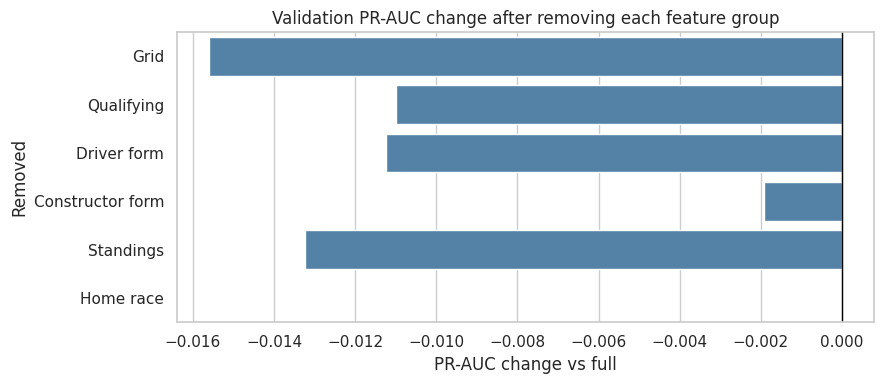

In [39]:
feature_groups = {
    "Grid": ["grid"],
    "Qualifying": ["qualifying_position", "quali_gap_to_fastest", "quali_gap_missing",
                   "grid_vs_quali_diff", "grid_worse_than_qualifying"],
    "Driver form": ["driver_podium_rate_last5", "driver_avg_finish_last5",
                    "driver_career_podium_rate", "driver_past_starts"],
    "Constructor form": ["constructor_podium_rate_last5", "constructor_avg_finish_last5",
                         "constructor_past_starts"],
    "Standings": ["driver_points_before", "driver_standing_before",
                  "constructor_points_before", "constructor_standing_before"],
    "Home race": ["home_race"]
}
assert set(sum(feature_groups.values(), [])) == set(feature_cols)

def fit_experiment(cols, estimator=None):
    estimator = estimator if estimator is not None else make_models()["Logistic regression (18 features)"]
    fitted = clone(estimator).fit(train_df[cols], y_train)
    prob = fitted.predict_proba(val_df[cols])[:, 1]
    return fitted, scores(y_val, prob, choose_threshold(y_val, prob))

_, full_metrics = fit_experiment(feature_cols)
ablation_rows = [{"Removed": "None (full)", "Features": len(feature_cols), **full_metrics}]
for group, removed in feature_groups.items():
    remaining = [c for c in feature_cols if c not in removed]
    _, metrics = fit_experiment(remaining)
    ablation_rows.append({"Removed": group, "Features": len(remaining), **metrics})
ablation_results = pd.DataFrame(ablation_rows)
ablation_results["PR-AUC change vs full"] = ablation_results["PR-AUC"] - full_metrics["PR-AUC"]
display(ablation_results.round(4))
plt.figure(figsize=(9, 4))
sns.barplot(data=ablation_results.iloc[1:], y="Removed", x="PR-AUC change vs full", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Validation PR-AUC change after removing each feature group")
plt.tight_layout(); plt.show()

### 5.2 Preprocessing-order experiments (two controlled comparisons)

Compare **median imputation → standardization**, **standardization → median imputation**, and **median imputation without scaling** with the same logistic regression, training rows and validation rows. The two ordering comparisons are A vs B and A vs C. For **each** pipeline, choose its decision threshold on validation F1, exactly as in the main tuning section. Since thresholds are selected on these same validation observations, the comparisons are exploratory, not unbiased performance estimates. PR-AUC and ROC-AUC remain threshold independent.


,Pipeline,Validation threshold,Accuracy,PR-AUC,ROC-AUC,F1,Precision,Recall
0,A: median impute → standardize,0.7339,0.9064,0.7412,0.9294,0.7068,0.6667,0.7521
1,B: standardize → median impute,0.7343,0.9064,0.7413,0.9294,0.7068,0.6667,0.7521
2,C: median impute → no scaling,0.7326,0.9064,0.7405,0.9291,0.7068,0.6667,0.7521


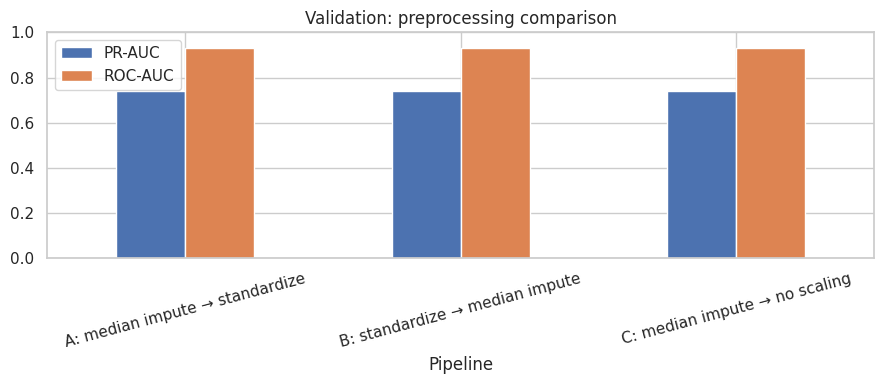

Observed missingness (train):


,Missing fraction
quali_gap_to_fastest,0.664846
qualifying_position,0.659342
grid_worse_than_qualifying,0.659342
grid_vs_quali_diff,0.659342
driver_standing_before,0.144686
constructor_standing_before,0.139631
driver_career_podium_rate,0.034531
driver_avg_finish_last5,0.034531
driver_podium_rate_last5,0.034531
constructor_podium_rate_last5,0.013902


Illustrative raw vs transformed range for grid:
Raw: 1 34
Scaled: -1.5912039718203683 2.8425237122923597


In [40]:
preprocess_trials = {
    "A: median impute → standardize": Pipeline([
        ("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))]),
    "B: standardize → median impute": Pipeline([
        ("scale", StandardScaler()), ("impute", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))]),
    "C: median impute → no scaling": Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))])
}
preprocess_rows = []
for label, pipeline in preprocess_trials.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=UserWarning)
        pipeline.fit(X_train, y_train)
    probability = pipeline.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(y_val, probability)
    preprocess_rows.append({"Pipeline": label, "Validation threshold": threshold,
                            **scores(y_val, probability, threshold)})
preprocess_results = pd.DataFrame(preprocess_rows)
display(preprocess_results.round(4))
preprocess_results.set_index("Pipeline")[["PR-AUC", "ROC-AUC"]].plot.bar(figsize=(9, 4), rot=15)
plt.ylim(0, 1); plt.title("Validation: preprocessing comparison")
plt.tight_layout(); plt.show()
print("Observed missingness (train):")
display(X_train.isna().mean().sort_values(ascending=False).rename("Missing fraction").to_frame().head(12))
print("Illustrative raw vs transformed range for grid:")
print("Raw:", X_train.grid.min(), X_train.grid.max())
print("Scaled:", np.nanmin(preprocess_trials["A: median impute → standardize"].named_steps["scale"].transform(
    preprocess_trials["A: median impute → standardize"].named_steps["impute"].transform(X_train))[:, feature_cols.index("grid")]),
    np.nanmax(preprocess_trials["A: median impute → standardize"].named_steps["scale"].transform(
    preprocess_trials["A: median impute → standardize"].named_steps["impute"].transform(X_train))[:, feature_cols.index("grid")]))

## 6. Explainability (XAI)

Section 6.1 computes permutation importance for the **validation-selected model**, using the **full validation set** (not a subsample) for a more stable estimate. Section 6.2 repeats permutation importance on the Random Forest for comparison — the two rankings disagree because they come from different models (a linear model vs. a tree ensemble weigh correlated/nonlinear signal differently), not because one is wrong. Section 6.3's sampled SHAP beeswarm and local waterfall now explain **the same validation-selected model** used everywhere else in this notebook, so global and local explanations are consistent with each other and with the model actually used in Section 7/8. All feature importance below is **predictive association, not causal evidence**.

### 6.1 Selected-model permutation importance (global)

Unlike the separate Random Forest SHAP demonstration below, this explanation **always corresponds to the actual validation-selected model and its exact feature subset**. The importance measure is the change in validation average precision when a feature is permuted. It is predictive reliance, **not causality**.

Grid dominates (PR-AUC importance 0.263, about 6× the next feature). The next clearly non-zero features are the standings features driver_points_before (0.046) and constructor_points_before (0.024), then smaller effects from driver_career_podium_rate, grid_vs_quali_diff, qualifying_position and grid_worse_than_qualifying (0.009–0.016, with standard deviations of similar size). The other features are near zero, so shuffling them does not hurt. Correlated features share importance, so a low value does not mean a group is uninformative; the ablation shows qualifying and driver form still cost about 0.011 PR-AUC each when removed.

,Feature,PR-AUC importance,Std
0,grid,0.2629,0.0396
13,driver_points_before,0.0455,0.0218
15,constructor_points_before,0.0239,0.0077
8,driver_career_podium_rate,0.0155,0.0140
4,grid_vs_quali_diff,0.0146,0.0116
1,qualifying_position,0.0125,0.0111
5,grid_worse_than_qualifying,0.0094,0.0045
10,constructor_podium_rate_last5,0.0073,0.0136
16,constructor_standing_before,0.0036,0.0094
3,quali_gap_missing,0.0013,0.0037


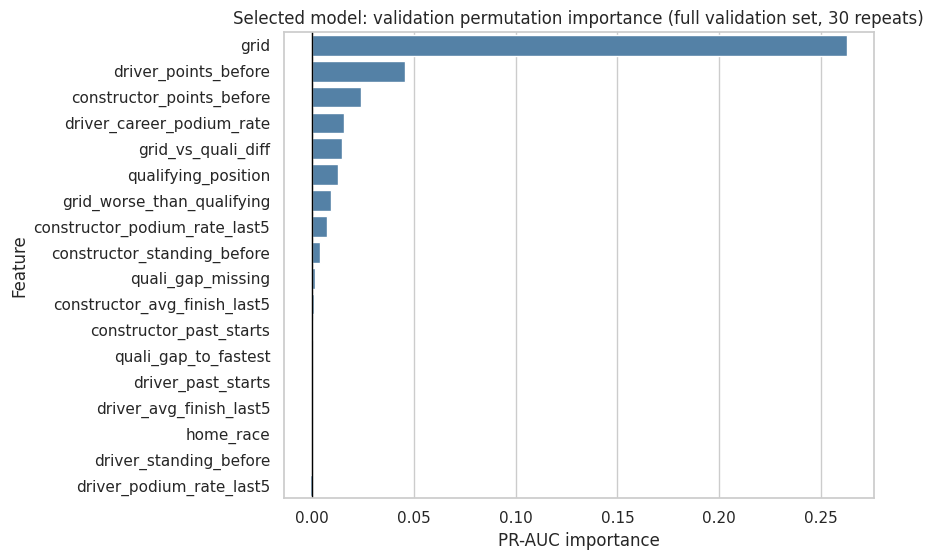

In [41]:
selected_xai = val_df  # full validation set (780 rows), not a 250-row subsample, for a more stable estimate
selected_importance = permutation_importance(
    best_model, selected_xai[best_features], selected_xai["podium"],
    scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=1
)
selected_importance_table = pd.DataFrame({
    "Feature": best_features,
    "PR-AUC importance": selected_importance.importances_mean,
    "Std": selected_importance.importances_std
}).sort_values("PR-AUC importance", ascending=False)
display(selected_importance_table.round(4))
plt.figure(figsize=(9, max(4, len(best_features) * 0.32)))
sns.barplot(data=selected_importance_table, x="PR-AUC importance", y="Feature", color="steelblue")
plt.axvline(0, color="black", linewidth=1)
plt.title("Selected model: validation permutation importance (full validation set, 30 repeats)")
plt.tight_layout()
plt.show()


The random forest also ranks grid first (0.139), then constructor form (about 0.042) and qualifying features (about 0.03), with standings features at or below zero. This differs from the linear model's second tier, but the forest was scored on a 200-row sample with 5 repeats and the standard deviations are large, so the ordering below grid is not reliable. The forest is not the selected model.

,Feature,PR-AUC importance,Std
0,grid,0.1388,0.0622
11,constructor_avg_finish_last5,0.0432,0.0205
10,constructor_podium_rate_last5,0.0416,0.0264
1,qualifying_position,0.0310,0.0236
2,quali_gap_to_fastest,0.0283,0.0344
4,grid_vs_quali_diff,0.0011,0.0009
5,grid_worse_than_qualifying,0.0010,0.0019
17,home_race,0.0006,0.0003
7,driver_avg_finish_last5,0.0006,0.0065
3,quali_gap_missing,0.0000,0.0000


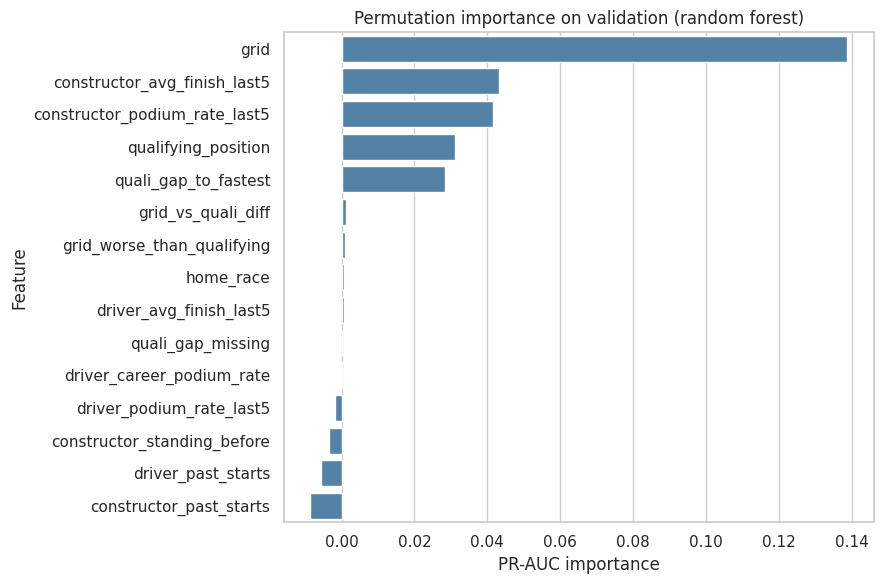

In [42]:
forest = trained["Random forest"]
# Fixed validation subsample to keep the notebook feasible on Kaggle.
xai_sample = X_val.sample(n=min(200, len(X_val)), random_state=SEED)
y_xai = y_val.loc[xai_sample.index]
perm = permutation_importance(forest, xai_sample, y_xai, n_repeats=5,
    random_state=SEED, scoring="average_precision", n_jobs=1)
perm_df = pd.DataFrame({"Feature": feature_cols, "PR-AUC importance": perm.importances_mean,
                        "Std": perm.importances_std}).sort_values("PR-AUC importance", ascending=False)
display(perm_df.head(15).round(4))
plt.figure(figsize=(9, 6))
sns.barplot(data=perm_df.head(15), x="PR-AUC importance", y="Feature", color="steelblue")
plt.title("Permutation importance on validation (random forest)")
plt.tight_layout(); plt.show()

### SHAP: explain the selected model

SHAP shows which features increase or decrease the selected model's predicted podium probability. The summary plot explains patterns across a sample of validation records. The waterfall plot explains one validation driver who actually finished on the podium. These explanations show how the model uses information; they do not prove what causes a podium finish.


In the beeswarm, low grid values push the podium probability up, and high grid values push it down; this is the widest band. driver_points_before is positive when high. constructor_points_before has a counterintuitive negative sign at high values, an artefact of correlation with the other team-strength features, so it should not be read as "more points hurt". quali_gap_missing ranks third in SHAP although its permutation importance is near zero. In the waterfall (probability 0.977, base 0.317), grid = 1 contributes +0.36. driver_career_podium_rate, constructor_podium_rate_last5 and driver_points_before contribute +0.07 each. The negatives are constructor_points_before (−0.05) and quali_gap_missing (−0.03). Every other feature contributes 0.05 or less. Only the net effect of all the others (+0.30) is smaller than the grid contribution. These are attributions of the model, not causes.


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
PermutationExplainer explainer: 101it [00:13,  4.79it/s]                         


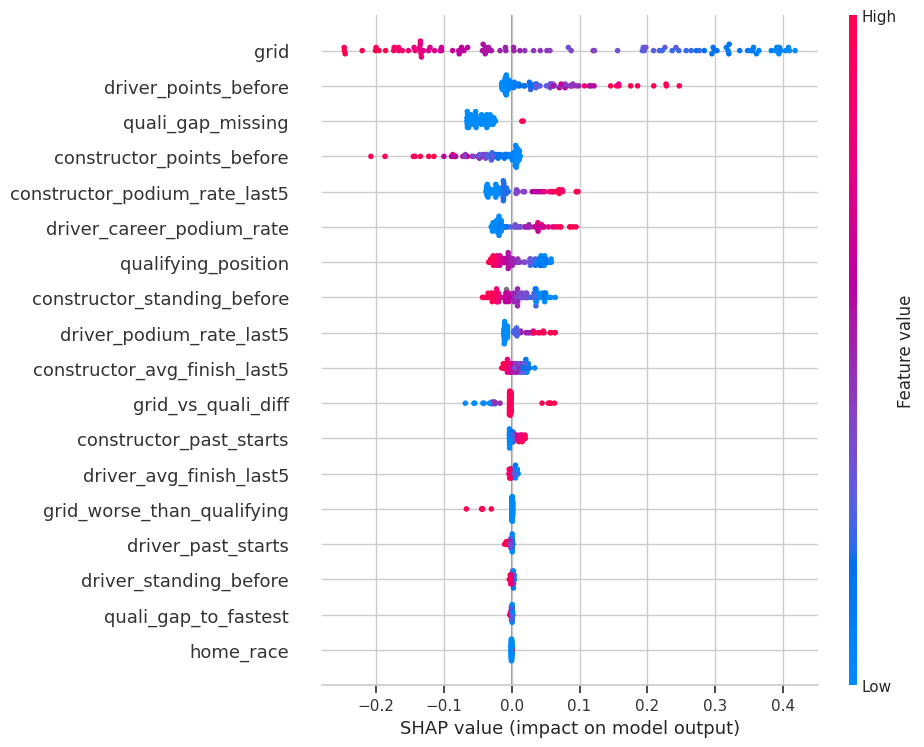

Local validation row: 24649 | true podium: 1 | selected-model podium probability: 0.9767


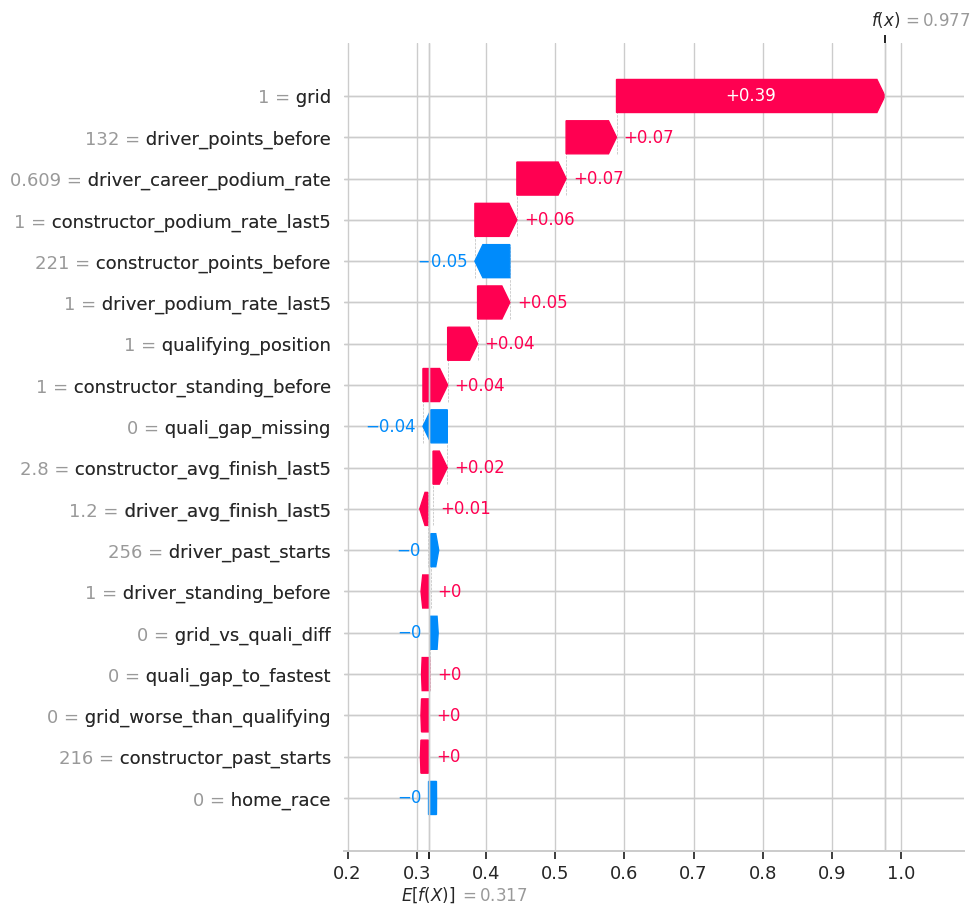

Interpretation: positive SHAP values push the selected model's predicted podium probability upward; negative values push it downward. This is predictive attribution, not a causal effect.


In [43]:
try:
    import shap
except ImportError as exc:
    raise ImportError("Install SHAP in the Kaggle environment (pip install shap) and rerun.") from exc

# Model-agnostic explainer on the fitted pipeline's predicted probability, since the selected
# model (logistic regression) is not a tree. Background sample mirrors training-only fitting.
background = train_df[best_features].sample(n=min(200, len(train_df)), random_state=SEED)

def predict_fn(X):
    return best_model.predict_proba(pd.DataFrame(X, columns=best_features))[:, 1]

explainer = shap.Explainer(predict_fn, shap.maskers.Independent(background), feature_names=best_features)
shap_validation = val_df[best_features].sample(n=min(100, len(val_df)), random_state=SEED)
shap_values = explainer(shap_validation)
shap.plots.beeswarm(shap_values, max_display=len(best_features), show=True)

# Pick the most confident TRUE podium prediction instead of an arbitrary row (previously row 0,
# a non-podium case at probability 0.078 — uninformative for a local explanation).
val_probability = predict_fn(shap_validation.values)
true_podium_mask = (val_df.loc[shap_validation.index, "podium"].values == 1)
local_index = int(np.argmax(np.where(true_podium_mask, val_probability, -1)))
print("Local validation row:", shap_validation.index[local_index],
      "| true podium:", int(val_df.loc[shap_validation.index[local_index], "podium"]),
      "| selected-model podium probability:", round(float(val_probability[local_index]), 4))
shap.plots.waterfall(shap_values[local_index], max_display=len(best_features), show=True)
print("Interpretation: positive SHAP values push the selected model's predicted podium probability "
      "upward; negative values push it downward. This is predictive attribution, not a causal effect.")


### 6.4 Local explanation (LIME)

Sections 6.1–6.3 give **global** explanations (which features matter overall). Here we add a **local** explanation for a single validation prediction using LIME (Local Interpretable Model-agnostic Explanations) on the **validation-selected model and its exact feature subset** (`best_model`, `best_features`). LIME fits a simple, interpretable surrogate model around one prediction to show which feature values pushed that specific driver's podium probability up or down. As with permutation importance and SHAP, this is **local predictive attribution, not a causal explanation**.


LIME agrees that grid <= 7 is the dominant positive factor. The main negative is grid_vs_quali_diff <= 0, a narrow local effect. This row has driver_points_before <= 0, probably the first race of a season, when all points are reset, and the model scores it down; this differs from the SHAP row, which was a different driver.

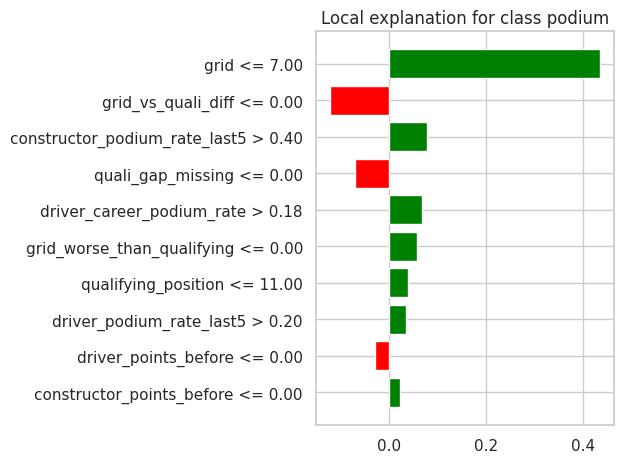

In [44]:
!pip install -q lime
from lime.lime_tabular import LimeTabularExplainer

bg = train_df[best_features]; medians = bg.median()
lime_explainer = LimeTabularExplainer(bg.fillna(medians).values, feature_names=best_features,
    class_names=["no podium", "podium"], mode="classification", random_state=SEED)
pos = np.flatnonzero(val_df["podium"].values == 1)[0]            # a real podium finisher
row = val_df[best_features].iloc[pos].fillna(medians)
exp = lime_explainer.explain_instance(row.values,
    lambda a: best_model.predict_proba(pd.DataFrame(a, columns=best_features)), num_features=10)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()


## 7. Final held-out test evaluation (2022–2024)

All hyperparameters, feature subsets, thresholds and race-level decision rules were chosen on validation, not test. The table below reports **training, validation and held-out test** metrics for the grid-only baseline and the three common-feature candidate models, plus the validation-selected candidate. The selected model is included only once in the test results; it is not counted again under a different label. The selected model may underperform the grid-only baseline on test F1; this must be reported, not used to retune the selection.


GRID-ONLY BASELINE + COMMON-FEATURE CANDIDATE MODELS: training, validation and unseen test


,Model,Split,Threshold,F1,PR-AUC,ROC-AUC,Precision,Recall,Accuracy
0,Logistic regression (18 features),Train,0.7339,0.5816,0.5602,0.9060,0.5047,0.6861,0.8769
1,Logistic regression (18 features),Validation,0.7339,0.7068,0.7412,0.9294,0.6667,0.7521,0.9064
2,Random forest,Train,0.5259,0.7797,0.8924,0.9837,0.6682,0.9359,0.9341
3,Random forest,Validation,0.5259,0.7034,0.6963,0.9340,0.6975,0.7094,0.9103
4,Shallow neural network,Train,0.3247,0.5932,0.5969,0.9143,0.5331,0.6684,0.8857
5,Shallow neural network,Validation,0.3247,0.6923,0.7513,0.9280,0.6923,0.6923,0.9077
34,Grid-only logistic regression,Train,0.8284,0.5406,0.4926,0.8899,0.5407,0.5405,0.8855
35,Grid-only logistic regression,Validation,0.8284,0.6923,0.6386,0.9094,0.6923,0.6923,0.9077
36,Grid-only logistic regression,Test,0.8284,0.6486,0.6473,0.9138,0.6502,0.6471,0.8948
37,Random forest,Test,0.5259,0.6853,0.6980,0.9327,0.6115,0.7794,0.8926


VALIDATION-SELECTED MODEL: train, validation and held-out test


,Model,Split,Threshold,F1,PR-AUC,ROC-AUC,Precision,Recall,Accuracy
0,Logistic regression (18 features),Train,0.7339,0.5816,0.5602,0.9060,0.5047,0.6861,0.8769
1,Logistic regression (18 features),Validation,0.7339,0.7068,0.7412,0.9294,0.6667,0.7521,0.9064
39,Logistic regression (18 features),Test,0.7339,0.6802,0.7057,0.9367,0.5793,0.8235,0.8837


Selected decision rule: Threshold
Selected model test F1: 0.6802


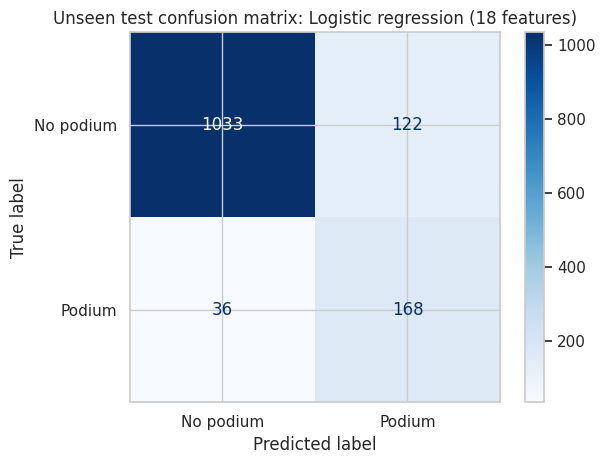

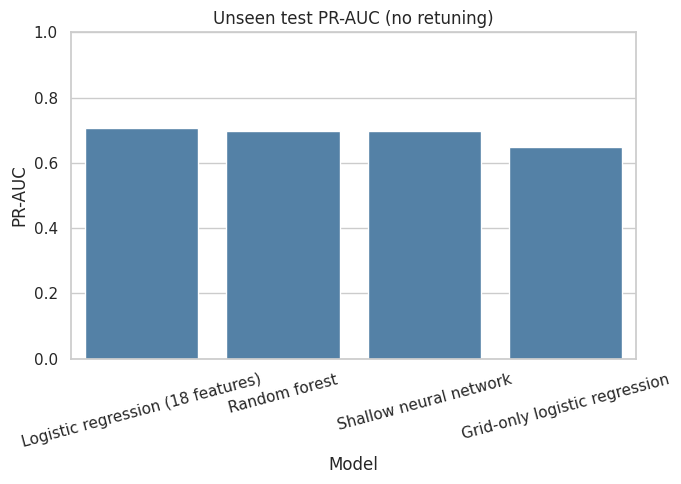

In [45]:
# The grid-only baseline, the common-feature candidate models, and the validation-selected candidate
# each appear once in the test table. Non-selected models use their own validation-selected
# thresholds; the selected candidate uses its frozen validation-selected race-level decision rule.
selected_test_probability = best_model.predict_proba(test_df[best_features])[:, 1]
selected_test_pred = (top_three_predictions(test_df, selected_test_probability)
                      if best_strategy == "Race Top 3"
                      else (selected_test_probability >= best_threshold).astype(int))
selected_test_metrics = {
    "Model": best_name, "Split": "Test",
    "Threshold": best_threshold if best_strategy == "Threshold" else np.nan,
    "PR-AUC": average_precision_score(y_test, selected_test_probability),
    "ROC-AUC": roc_auc_score(y_test, selected_test_probability),
    "F1": f1_score(y_test, selected_test_pred, zero_division=0),
    "Accuracy": accuracy_score(y_test, selected_test_pred),
    "Precision": precision_score(y_test, selected_test_pred, zero_division=0),
    "Recall": recall_score(y_test, selected_test_pred, zero_division=0)
}
test_rows = []
for name in ["Grid-only logistic regression", "Logistic regression (18 features)", "Random forest", "Shallow neural network"]:
    if name == best_name:
        continue
    probability = trained[name].predict_proba(test_df[model_features[name]])[:, 1]
    test_rows.append({"Model": name, "Split": "Test", "Threshold": thresholds[name],
                      **scores(y_test, probability, thresholds[name])})
test_rows.append(selected_test_metrics)
test_results = pd.DataFrame(test_rows)
all_results = pd.concat([validation_results, test_results], ignore_index=True)
print("GRID-ONLY BASELINE + COMMON-FEATURE CANDIDATE MODELS: training, validation and unseen test")
display(all_results.loc[all_results.Model.isin([
    "Grid-only logistic regression", "Logistic regression (18 features)", "Random forest", "Shallow neural network"
]), ["Model", "Split", "Threshold", "F1", "PR-AUC", "ROC-AUC", "Precision", "Recall", "Accuracy"]].round(4))
print("VALIDATION-SELECTED MODEL: train, validation and held-out test")
display(all_results.loc[all_results.Model == best_name,
    ["Model", "Split", "Threshold", "F1", "PR-AUC", "ROC-AUC", "Precision", "Recall", "Accuracy"]].round(4))
print("Selected decision rule:", best_strategy)
print("Selected model test F1:", round(selected_test_metrics["F1"], 4))
ConfusionMatrixDisplay.from_predictions(y_test, selected_test_pred, display_labels=["No podium", "Podium"],
                                         cmap="Blues", values_format="d")
plt.title(f"Unseen test confusion matrix: {best_name}")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=test_results.sort_values("PR-AUC", ascending=False).head(8), x="Model", y="PR-AUC", color="steelblue", ax=ax)
ax.set_ylim(0, 1); ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Unseen test PR-AUC (no retuning)")
plt.tight_layout(); plt.show()

### Held-out test: selected model versus the candidate models

The validation-selected model's configuration and decision rule are chosen using validation only. The following is **descriptive**, not a new round of model selection. ROC-AUC/PR-AUC measure ranking, while F1 depends on the decision rule. Do not claim the final model is superior unless the observed held-out metrics support that statement — and remember the grid-only logistic regression, not any of these three, is this notebook's baseline.

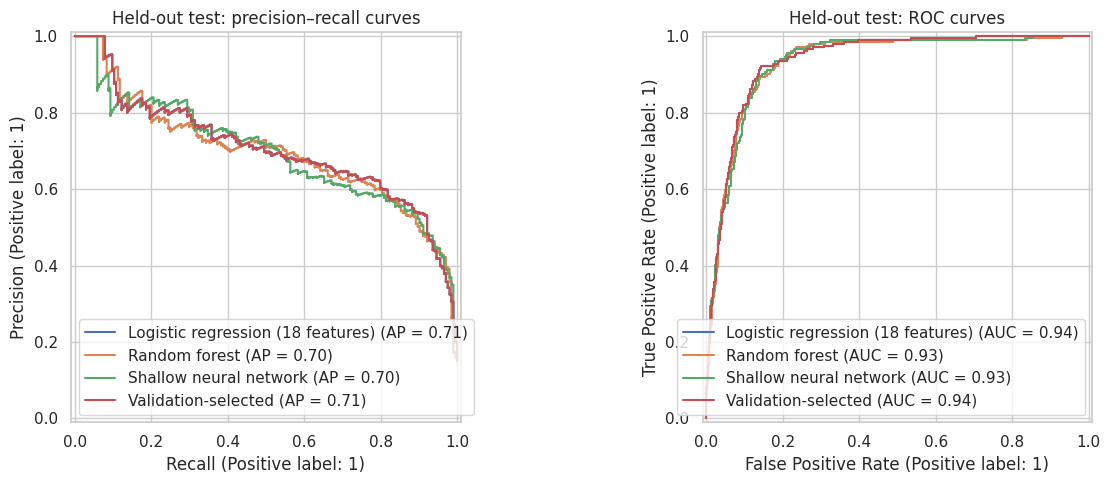

Validation-selected test F1: 0.6802
This test result must not be used to change the selected model or threshold.


In [46]:
comparison_names = ["Logistic regression (18 features)", "Random forest", "Shallow neural network"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in comparison_names:
    prob = trained[name].predict_proba(test_df[model_features[name]])[:, 1]
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, selected_test_probability,
                                       name="Validation-selected", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, selected_test_probability,
                                 name="Validation-selected", ax=axes[1])
axes[0].set_title("Held-out test: precision–recall curves")
axes[1].set_title("Held-out test: ROC curves")
plt.tight_layout()
plt.show()
print("Validation-selected test F1:", round(selected_test_metrics["F1"], 4))
print("This test result must not be used to change the selected model or threshold.")


## 8. Inference function and missing-input demonstration

Input is a dictionary of pre-race features computed using information available after qualifying and before the race. Missing values are handled by the training-fitted pipeline. The notebook demonstrates both a **complete input record** and a **partially missing record**. If no genuinely fully observed validation record exists, the first example is **explicitly labeled synthetic**, completed with training-set statistics. Historical form and standings must be computed from earlier races before inference; this is not a live F1 data collector. Single-driver predictions use the fixed threshold; if the selected race-level strategy is Top 3, the race-level function must be used to apply that strategy.


In [47]:
def predict_podium(record):
    if not isinstance(record, dict):
        raise TypeError("record must be a dictionary of pre-race feature values")
    unexpected = set(record) - set(best_features)
    if unexpected:
        raise ValueError(f"Unknown feature(s): {sorted(unexpected)}")
    row = pd.DataFrame([{col: record.get(col, np.nan) for col in best_features}])
    if row.notna().sum(axis=1).iloc[0] < max(3, len(best_features) // 2):
        raise ValueError("Too many missing inputs for a reliable single-driver prediction")
    for col in best_features:
        row[col] = pd.to_numeric(row[col], errors="coerce")
    probability = float(best_model.predict_proba(row[best_features])[0, 1])
    return {"model": best_name, "podium_probability": round(probability, 4),
            "threshold": round(best_threshold, 3),
            "predicted_podium": bool(probability >= best_threshold),
            "note": "Single-driver threshold decision; race-level Top 3 requires all entrants",
            "missing_feature_count": int(row.isna().sum(axis=1).iloc[0])}

# Prefer a truly fully observed validation row. When historical missingness
# prevents that, explicitly label a train-median-completed synthetic example.
fully_observed = val_df[best_features].notna().all(axis=1)
if fully_observed.any():
    complete_record = val_df.loc[fully_observed, best_features].iloc[0].to_dict()
    print("Complete-record source: genuinely fully observed validation entry")
else:
    complete_record = val_df[best_features].iloc[0].to_dict()
    print("Complete-record source: synthetic train-statistic-completed validation entry")
for _col in best_features:
    if pd.isna(complete_record[_col]):
        _known = train_df[_col].dropna()
        complete_record[_col] = _known.median() if not _known.empty else np.nan
partial_record = {c: complete_record[c] for c in best_features[:max(3, len(best_features) // 2)]}
print("Complete record:", predict_podium(complete_record))
print("Partially missing record:", predict_podium(partial_record))

def predict_race_podium(race_records):
    """Predict podium for an entire race of entrants, one record per driver.

    Each record must contain raceId and driverId plus available model features.
    Missing feature values use the training-fitted imputer. No post-race values.
    """
    rows = pd.DataFrame(race_records)
    required = {"raceId", "driverId"}
    if not required.issubset(rows.columns):
        raise ValueError("Each race record needs raceId and driverId")
    if rows.empty or rows.duplicated(["raceId", "driverId"]).any():
        raise ValueError("Records must be nonempty and unique by raceId, driverId")
    for col in best_features:
        if col not in rows.columns:
            rows[col] = np.nan
        rows[col] = pd.to_numeric(rows[col], errors="coerce")
    probability = best_model.predict_proba(rows[best_features])[:, 1]
    if best_strategy == "Race Top 3":
        if "grid" not in rows.columns:
            rows["grid"] = np.nan
        pred = top_three_predictions(rows, probability)
    else:
        pred = (probability >= best_threshold).astype(int)
    return pd.DataFrame({"raceId": rows["raceId"].values,
                         "driverId": rows["driverId"].values,
                         "podium_probability": probability,
                         "predicted_podium": pred.astype(bool)})

# Demonstration only: use validation features to show the inference API.
example_race = val_df.loc[val_df.raceId == val_df.raceId.iloc[0],
                          ["raceId", "driverId"] + list(dict.fromkeys(best_features))]
display(predict_race_podium(example_race.to_dict("records")).head())


Complete-record source: genuinely fully observed validation entry
Complete record: {'model': 'Logistic regression (18 features)', 'podium_probability': 0.9529, 'threshold': 0.734, 'predicted_podium': True, 'note': 'Single-driver threshold decision; race-level Top 3 requires all entrants', 'missing_feature_count': 0}
Partially missing record: {'model': 'Logistic regression (18 features)', 'podium_probability': 0.8652, 'threshold': 0.734, 'predicted_podium': True, 'note': 'Single-driver threshold decision; race-level Top 3 requires all entrants', 'missing_feature_count': 9}


,raceId,driverId,podium_probability,predicted_podium
0,1031,1,0.865873,True
1,1031,8,0.027741,False
2,1031,20,0.408177,False
3,1031,154,0.050789,False
4,1031,815,0.372196,False


## 9. Automated results summary and limitations

The tables below are generated from executed outputs (no invented performance numbers). Add their plots and observed findings to the PDF report. Limitations include sparse early qualifying coverage, era changes, uncertain historical nationality mapping, the simplified Q1 pace proxy, race-level constructor aggregation, and historical standings availability. Home-country matching is an approximation; feature importance is not causality. Models are trained on historical data and are **not** calibrated betting or safety predictions.

### Submission checklist and limitations

- Execute **Run All** on Kaggle with the intended 14-table dataset attached, confirm no failed cells, and save the executed version.
- In the separate PDF report, explain each of the three relational data-engineering questions with figures, the target/prediction cutoff, data quality, pre-race feature logic, chronological split, models, class imbalance, ablation, preprocessing-order comparisons, global and local explanations, and final held-out metrics.
- Include a clear distinction between **validation model selection** and **unseen test evaluation**. The first notebook's same-race post-race standings and test-based ablation must not be used.
- Historical qualifying coverage is incomplete; early qualifying fields are often missing; training-only pipeline imputation handles these gaps. Shared drives and classification conventions also limit historical comparability. The podium target is the assignment-defined `positionOrder` 1–3, not necessarily three classified finishers in every historical race.
- A single-driver inference call is a threshold decision; a race-level Top 3 call needs the full entrant list. Neither is a calibrated guarantee of a podium.
- Submit the executed Kaggle link, GitHub link, and PDF report as required by your course description. Verify deadline and sharing permissions separately.


In [48]:
print("REPORT-READY SUMMARY")
print("Dataset grain:", len(final_df), "unique driver–race entries")
print("Training years:", int(train_df.year.min()), "to", int(train_df.year.max()))
print("Validation years:", int(val_df.year.min()), "to", int(val_df.year.max()))
print("Unseen test years:", int(test_df.year.min()), "to", int(test_df.year.max()))
print("Model-selection metric: validation F1; also report PR-AUC and ROC-AUC")
print("Selected by validation:", best_name)
display(val_ranking[["Model", "PR-AUC", "ROC-AUC", "F1", "Threshold"]].round(4))
display(test_results[["Model", "PR-AUC", "ROC-AUC", "F1", "Precision", "Recall"]].round(4))
print("Ablation groups:", len(feature_groups), "| Preprocessing pipelines:", len(preprocess_trials))
print("Reminder: export this notebook and submit a separate PDF analytical report with the three DE answers and figures.")
print("Selected features:", best_features)
print("Candidate models evaluated:", len(trained))
print("Selected race-level decision strategy:", best_strategy)
print("Race-level validation comparison (top 10):")
display(race_comparison.head(10).round(4))


REPORT-READY SUMMARY
Dataset grain: 26668 unique driver–race entries
Training years: 1950 to 2019
Validation years: 2020 to 2021
Unseen test years: 2022 to 2024
Model-selection metric: validation F1; also report PR-AUC and ROC-AUC
Selected by validation: Logistic regression (18 features)


,Model,PR-AUC,ROC-AUC,F1,Threshold
1,Logistic regression (18 features),0.7412,0.9294,0.7068,0.7339
33,Extra Trees | all_18 | leaf=15,0.7155,0.9284,0.7064,0.7757
9,Logistic tuned | all_18 | C=1.0,0.7467,0.9328,0.7063,0.7233
7,Logistic tuned | all_18 | C=0.1,0.7451,0.9324,0.7054,0.7751
31,Extra Trees | all_18 | leaf=5,0.7035,0.9290,0.7036,0.5694
17,Logistic tuned | core_plus_standings_11 | C=1.0,0.7274,0.9265,0.7034,0.8063
15,Logistic tuned | core_plus_standings_11 | C=0.1,0.7273,0.9264,0.7034,0.8062
3,Random forest,0.6963,0.9340,0.7034,0.5259
23,Forest tuned | core_plus_standings_11,0.7203,0.9306,0.7027,0.8077
19,Logistic tuned | all_except_constructor_form |...,0.7435,0.9320,0.7025,0.7664


,Model,PR-AUC,ROC-AUC,F1,Precision,Recall
0,Grid-only logistic regression,0.6473,0.9138,0.6486,0.6502,0.6471
1,Random forest,0.6980,0.9327,0.6853,0.6115,0.7794
2,Shallow neural network,0.6964,0.9330,0.6483,0.6104,0.6912
3,Logistic regression (18 features),0.7057,0.9367,0.6802,0.5793,0.8235


Ablation groups: 6 | Preprocessing pipelines: 3
Reminder: export this notebook and submit a separate PDF analytical report with the three DE answers and figures.
Selected features: ['grid', 'qualifying_position', 'quali_gap_to_fastest', 'quali_gap_missing', 'grid_vs_quali_diff', 'grid_worse_than_qualifying', 'driver_podium_rate_last5', 'driver_avg_finish_last5', 'driver_career_podium_rate', 'driver_past_starts', 'constructor_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_past_starts', 'driver_points_before', 'driver_standing_before', 'constructor_points_before', 'constructor_standing_before', 'home_race']
Candidate models evaluated: 18
Selected race-level decision strategy: Threshold
Race-level validation comparison (top 10):


,Model,Strategy,Validation F1,Precision,Recall,PR-AUC,ROC-AUC
0,Neural tuned | core_plus_standings_11,Race Top 3,0.7094,0.7094,0.7094,0.7372,0.9284
1,Logistic regression (18 features),Threshold,0.7068,0.6667,0.7521,0.7412,0.9294
2,Extra Trees | all_18 | leaf=15,Threshold,0.7064,0.7034,0.7094,0.7155,0.9284
3,Logistic tuned | all_18 | C=1.0,Threshold,0.7063,0.6593,0.7607,0.7467,0.9328
4,Logistic tuned | all_18 | C=0.1,Threshold,0.7054,0.6855,0.7265,0.7451,0.9324
5,Extra Trees | all_18 | leaf=5,Threshold,0.7036,0.6544,0.7607,0.7035,0.9290
6,Logistic tuned | core_plus_standings_11 | C=1.0,Threshold,0.7034,0.6975,0.7094,0.7274,0.9265
7,Logistic tuned | core_plus_standings_11 | C=0.1,Threshold,0.7034,0.6975,0.7094,0.7273,0.9264
8,Logistic tuned | all_except_constructor_form |...,Threshold,0.7025,0.6800,0.7265,0.7435,0.9320
9,Neural tuned | core_plus_standings_11,Threshold,0.7022,0.7315,0.6752,0.7372,0.9284


## 10. Evidence-based conclusions and submission checklist

**Primary metric:** F1, because podiums are a minority class and the task needs both precision and recall. **Secondary metric:** PR-AUC, because it assesses positive-class ranking without committing to one threshold. ROC-AUC is also reported. Thresholds and hyperparameters are chosen on validation only; the unseen test is for final reporting.

**Limitations:** Historical shared drives; uneven historical qualifying coverage; changing F1 rules, grid sizes and car performance across eras; post-qualifying grid uncertainty; and the possibility of overfitting the 2020–2021 validation period. Feature importance is predictive association, **not causation**. Any selected-model advantage must be interpreted relative to the grid-only baseline, not assumed from validation ranking alone.

**Submission reminder (outside the notebook):** A separate analytical PDF report containing the three question answers and figures, selected features with evidence, evaluation tables, global/local XAI interpretations and limitations; a public Kaggle notebook link; and an accessible GitHub repository link.

**Result interpretation:** If the validation-selected final model has lower test F1 than the original Logistic Regression, report both results. The model was selected without inspecting the test set; test-set superiority must not be claimed merely from higher validation F1. Explain the difference as generalization uncertainty rather than retuning to the test.

In [49]:
print("FINAL VALIDATION-SELECTED MODEL:", best_name)
print("Decision rule:", best_strategy)
print("Features:", best_features)
print("Validation F1:", round(float(final_race_comparison.iloc[0]["Validation F1"]), 4))
print("Unseen test F1:", round(float(selected_test_metrics["F1"]), 4))
print("Unseen test PR-AUC:", round(float(selected_test_metrics["PR-AUC"]), 4))
print("Unseen test ROC-AUC:", round(float(selected_test_metrics["ROC-AUC"]), 4))
print("F1 difference (test - validation):", round(float(selected_test_metrics["F1"] - final_race_comparison.iloc[0]["Validation F1"]), 4))


FINAL VALIDATION-SELECTED MODEL: Logistic regression (18 features)
Decision rule: Threshold
Features: ['grid', 'qualifying_position', 'quali_gap_to_fastest', 'quali_gap_missing', 'grid_vs_quali_diff', 'grid_worse_than_qualifying', 'driver_podium_rate_last5', 'driver_avg_finish_last5', 'driver_career_podium_rate', 'driver_past_starts', 'constructor_podium_rate_last5', 'constructor_avg_finish_last5', 'constructor_past_starts', 'driver_points_before', 'driver_standing_before', 'constructor_points_before', 'constructor_standing_before', 'home_race']
Validation F1: 0.7068
Unseen test F1: 0.6802
Unseen test PR-AUC: 0.7057
Unseen test ROC-AUC: 0.9367
F1 difference (test - validation): -0.0267


### Final reproducibility and submission checks

The cell below checks uniqueness, leakage-sensitive feature names, model training/validation/test reporting, and the absence of duplicate model names in the final test table. It does not replace an independent Kaggle Run All or the required separate analytical PDF report.


In [50]:
assert not final_df.duplicated(["raceId", "driverId"]).any()
assert train_df.year.max() < val_df.year.min() < test_df.year.min()
assert not any(col in feature_cols for col in ["podium", "positionOrder", "statusId", "points", "laps"])
assert not test_results["Model"].duplicated().any(), "Duplicate test model labels"
for name in ["Logistic regression (18 features)", "Random forest", "Shallow neural network"]:
    assert {"Train", "Validation", "Test"}.issubset(set(all_results.loc[all_results.Model == name, "Split"]))
assert {"F1", "PR-AUC", "ROC-AUC", "Precision", "Recall", "Accuracy"}.issubset(all_results.columns)
print("Final structural, split, model-metrics and test-table checks passed.")


Final structural, split, model-metrics and test-table checks passed.
